<a href="https://colab.research.google.com/github/kimeyahguia/SPARTHEON/blob/main/CourseBottleneck_and_AcademicProgression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import os, shutil

DATA_DIR = "/content/data_original"
os.makedirs(DATA_DIR, exist_ok=True)

REQUIRED = ["course_master", "course_performance", "prerequisite_mapping",
            "student_progression", "historical_course_records", "student_course_history"]

for n in REQUIRED:
    src, dest = f"/content/{n}.csv", os.path.join(DATA_DIR, f"{n}.csv")
    if os.path.exists(dest):
        os.chmod(dest, 0o644)
    shutil.copy(src, dest)      # copy, so the files in /content stay as they are
    os.chmod(dest, 0o444)       # read-only protection

print("Files in", DATA_DIR, "->", sorted(os.listdir(DATA_DIR)))

Files in /content/data_original -> ['course_master.csv', 'course_performance.csv', 'historical_course_records.csv', 'prerequisite_mapping.csv', 'student_course_history.csv', 'student_progression.csv']


In [35]:
import os, re, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from IPython.display import display

try:
    import mlxtend
except ImportError:
    !pip install -q mlxtend
    import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules   # only confirms the import works; not used yet

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

print("pandas", pd.__version__, "| numpy", np.__version__, "| mlxtend", mlxtend.__version__, "| networkx", nx.__version__)

# ---------- result log ----------
RESULTS = []
ICON = {"PASS": "[PASS]   ", "INFO": "[INFO]   ", "WARNING": "[WARNING]", "ERROR": "[ERROR]  "}
def record(section, status, check, detail=""):
    RESULTS.append({"section": section, "status": status, "check": check, "detail": detail})
    print(f"{ICON[status]} {check}" + (f" -> {detail}" if detail else ""))

# ---------- parsing helpers ----------
NULL_TOKENS = {"", "none", "nan", "null", "n/a", "na", "not applicable", "-", "[]"}
def parse_ids(x):
    """'C001;C002' / 'C001, C002' / "['C001','C002']" -> ['C001','C002'].  Empty/NaN -> []."""
    if pd.isna(x):
        return []
    s = str(x).strip()
    if s.lower() in NULL_TOKENS:
        return []
    return [t for t in re.split(r"[;,|\s\[\]'\"]+", s) if t]

def sem_no(s):
    """'1st Semester' / 'First Semester' / 'Sem 1' -> 1 ; '2nd ...' -> 2 ; otherwise NaN."""
    if pd.isna(s):
        return np.nan
    t = str(s).lower().strip()
    if re.search(r"\b(1st|first|1)\b", t): return 1
    if re.search(r"\b(2nd|second|2)\b", t): return 2
    return np.nan

def ay_parts(s):
    m = re.match(r"\s*(\d{4})\s*[-\u2013/]\s*(\d{4})\s*$", str(s))
    return (int(m.group(1)), int(m.group(2))) if m else (np.nan, np.nan)

def add_period(df, sem_col="semester", ay_col="academic_year"):
    """Adds sem_n, ay_start, ay_end, period_idx (= ay_start*2 + sem_n; consecutive semesters differ by 1)."""
    df = df.copy()
    df["sem_n"] = df[sem_col].map(sem_no)
    parts = df[ay_col].map(ay_parts)
    df["ay_start"] = parts.map(lambda p: p[0])
    df["ay_end"] = parts.map(lambda p: p[1])
    df["period_idx"] = df["ay_start"] * 2 + df["sem_n"]
    return df

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
print("Helpers ready.")

pandas 2.2.3 | numpy 2.4.6 | mlxtend 0.23.4 | networkx 3.7
Helpers ready.


In [36]:
DATA_DIR = "/content/data_original"      # change this if you use Google Drive instead

NAMES = ["course_master", "course_performance", "prerequisite_mapping",
         "student_progression", "historical_course_records", "student_course_history"]

SCHEMA = {   # (column, expected kind)  kinds: str / int / float / bool
 "course_master": [("course_id","str"),("course_code","str"),("course_name","str"),("college_code","str"),
    ("college_name","str"),("program_code","str"),("program_name","str"),("year_level","int"),
    ("semester_offered","str"),("units","int"),("course_type","str"),("prerequisite_course_ids","str"),
    ("course_status","str")],
 "course_performance": [("performance_id","str"),("course_id","str"),("course_code","str"),("program_code","str"),
    ("semester","str"),("academic_year","str"),("total_enrolled","int"),("total_passed","int"),
    ("total_failed","int"),("total_withdrawn","int"),("total_incomplete","int"),("average_grade","float"),
    ("passing_rate","float"),("failure_rate","float"),("withdrawal_rate","float"),("total_sections","int"),
    ("total_repeat_students","int")],
 "prerequisite_mapping": [("mapping_id","str"),("program_code","str"),("prerequisite_course_id","str"),
    ("prerequisite_course_code","str"),("prerequisite_course_name","str"),("succeeding_course_id","str"),
    ("succeeding_course_code","str"),("succeeding_course_name","str"),("dependency_type","str"),
    ("academic_year_applicable","str"),("relationship_status","str")],
 "student_progression": [("student_id","str"),("program_code","str"),("college_code","str"),("year_level","int"),
    ("admission_year","int"),("current_semester","str"),("academic_year","str"),("previous_gpa","float"),
    ("current_gpa","float"),("total_courses_taken","int"),("total_courses_passed","int"),
    ("total_courses_failed","int"),("total_courses_withdrawn","int"),("total_repeated_courses","int"),
    ("failed_course_ids","str"),("blocked_course_ids","str"),("progression_status","str"),
    ("estimated_progression_delay","int"),("repeat_status","str")],
 "historical_course_records": [("historical_id","str"),("course_id","str"),("course_code","str"),
    ("program_code","str"),("college_code","str"),("semester","str"),("academic_year","str"),
    ("total_enrolled","int"),("total_passed","int"),("total_failed","int"),("total_withdrawn","int"),
    ("failure_rate","float"),("withdrawal_rate","float"),("repeat_rate","float"),("average_grade","float"),
    ("intervention_applied","str"),("intervention_type","str"),("intervention_effectiveness","str")],
 "student_course_history": [("history_id","str"),("student_id","str"),("course_id","str"),("semester","str"),
    ("academic_year","str"),("final_grade","float"),("course_result","str"),("attempt_number","int"),
    ("is_repeat","bool")],
}
EXPECTED_COLS = {n: [c for c, _ in cols] for n, cols in SCHEMA.items()}
EXPECTED_ROWS = {"course_master": (50, 50), "course_performance": (50, 50), "prerequisite_mapping": (60, 60),
                 "student_progression": (200, 200), "historical_course_records": (200, 200),
                 "student_course_history": (1000, 2000)}
PKS = {"course_master": "course_id", "course_performance": "performance_id", "prerequisite_mapping": "mapping_id",
       "student_progression": "student_id", "historical_course_records": "historical_id",
       "student_course_history": "history_id"}

ORIG_HASH = {}
dfs = {}
for n in NAMES:
    path = f"{DATA_DIR}/{n}.csv"
    ORIG_HASH[n] = md5(path)
    dfs[n] = pd.read_csv(path)
    print(f"Loaded {n:28s} rows={dfs[n].shape[0]:5d}  cols={dfs[n].shape[1]:3d}   md5={ORIG_HASH[n][:10]}...")

course_master             = dfs["course_master"]
course_performance        = dfs["course_performance"]
prerequisite_mapping      = dfs["prerequisite_mapping"]
student_progression       = dfs["student_progression"]
historical_course_records = dfs["historical_course_records"]
student_course_history    = dfs["student_course_history"]

# working copies (all analysis below uses these)
cm = course_master.copy()
cp = course_performance.copy()
pm = prerequisite_mapping.copy()
sp = student_progression.copy()
hc = historical_course_records.copy()
sh = student_course_history.copy()

Loaded course_master                rows=   50  cols= 13   md5=d9f58494ec...
Loaded course_performance           rows=   50  cols= 17   md5=2eb4faf5bd...
Loaded prerequisite_mapping         rows=   60  cols= 11   md5=be3d71f221...
Loaded student_progression          rows=  200  cols= 19   md5=eae8379b71...
Loaded historical_course_records    rows=  200  cols= 18   md5=449d3c368b...
Loaded student_course_history       rows= 1928  cols=  9   md5=af71f2eddf...


In [37]:
for n in NAMES:
    print("=" * 100)
    print(f"{n}.csv  -  first 5 rows")
    display(dfs[n].head(5))

course_master.csv  -  first 5 rows


,course_id,course_code,course_name,college_code,college_name,program_code,program_name,year_level,semester_offered,units,course_type,prerequisite_course_ids,course_status
0,C001,GE101,Purposive Communication,CAS,College of Arts and Sciences,GEN,General Education and Service Courses,1,1st Semester,3,GE,NaN,Active
1,C002,GE102,Mathematics in the Modern World,CAS,College of Arts and Sciences,GEN,General Education and Service Courses,1,1st Semester,3,GE,NaN,Active
2,C003,GE103,Understanding the Self,CAS,College of Arts and Sciences,GEN,General Education and Service Courses,1,2nd Semester,3,GE,NaN,Active
3,C004,GE104,Readings in Philippine History,CAS,College of Arts and Sciences,GEN,General Education and Service Courses,1,2nd Semester,3,GE,NaN,Active
4,C005,GE105,Ethics,CAS,College of Arts and Sciences,GEN,General Education and Service Courses,2,1st Semester,3,GE,C003,Active


course_performance.csv  -  first 5 rows


,performance_id,course_id,course_code,program_code,semester,academic_year,total_enrolled,total_passed,total_failed,total_withdrawn,total_incomplete,average_grade,passing_rate,failure_rate,withdrawal_rate,total_sections,total_repeat_students
0,CP001,C001,GE101,GEN,1st Semester,2026-2027,1572,1459,67,37,9,2.24,92.81,4.26,2.35,40,15
1,CP002,C002,GE102,GEN,1st Semester,2026-2027,1541,1300,170,60,11,2.46,84.36,11.03,3.89,39,65
2,CP003,C003,GE103,GEN,1st Semester,2026-2027,185,167,13,4,1,2.32,90.27,7.03,2.16,5,108
3,CP004,C004,GE104,GEN,1st Semester,2026-2027,202,183,13,5,1,2.31,90.59,6.44,2.48,6,92
4,CP005,C005,GE105,GEN,1st Semester,2026-2027,1438,1303,91,34,10,2.34,90.61,6.33,2.36,36,29


prerequisite_mapping.csv  -  first 5 rows


,mapping_id,program_code,prerequisite_course_id,prerequisite_course_code,prerequisite_course_name,succeeding_course_id,succeeding_course_code,succeeding_course_name,dependency_type,academic_year_applicable,relationship_status
0,PM001,BSCE,C006,MATH101,College Algebra and Trigonometry,C007,MATH102,Differential Calculus,Sequential,2022-2023 onwards,Active
1,PM002,BSCE,C007,MATH102,Differential Calculus,C008,MATH103,Integral Calculus,Sequential,2022-2023 onwards,Under Review
2,PM003,BSCE,C006,MATH101,College Algebra and Trigonometry,C009,PHYS101,General Physics 1,Sequential,2022-2023 onwards,Active
3,PM004,BSCE,C007,MATH102,Differential Calculus,C011,CE201,Statics of Rigid Bodies,Foundational,2022-2023 onwards,Under Review
4,PM005,BSCE,C009,PHYS101,General Physics 1,C011,CE201,Statics of Rigid Bodies,Foundational,2022-2023 onwards,Active


... (2 outputs left out)

historical_course_records.csv  -  first 5 rows


,historical_id,course_id,course_code,program_code,college_code,semester,academic_year,total_enrolled,total_passed,total_failed,total_withdrawn,failure_rate,withdrawal_rate,repeat_rate,average_grade,intervention_applied,intervention_type,intervention_effectiveness
0,HC0001,C001,GE101,GEN,CAS,1st Semester,2024-2025,1449,1354,62,29,4.28,2.00,1.24,2.27,No,NaN,Not Applicable
1,HC0002,C001,GE101,GEN,CAS,2nd Semester,2024-2025,156,145,8,2,5.13,1.28,48.08,2.30,No,NaN,Not Applicable
2,HC0003,C001,GE101,GEN,CAS,1st Semester,2025-2026,1486,1386,63,25,4.24,1.68,1.01,2.20,No,NaN,Not Applicable
3,HC0004,C001,GE101,GEN,CAS,2nd Semester,2025-2026,145,135,7,3,4.83,2.07,54.48,2.26,No,NaN,Not Applicable
4,HC0005,C002,GE102,GEN,CAS,1st Semester,2024-2025,1457,1055,304,79,20.86,5.42,8.03,2.88,No,NaN,Not Applicable


student_course_history.csv  -  first 5 rows


,history_id,student_id,course_id,semester,academic_year,final_grade,course_result,attempt_number,is_repeat
0,SCH00001,STU0001,C001,1st Semester,2024-2025,NaN,Incomplete,1,False
1,SCH00002,STU0001,C002,1st Semester,2024-2025,1.50,Passed,1,False
2,SCH00003,STU0001,C006,1st Semester,2024-2025,1.75,Passed,1,False
3,SCH00004,STU0001,C029,1st Semester,2024-2025,1.25,Passed,1,False
4,SCH00005,STU0001,C001,2nd Semester,2024-2025,2.50,Passed,2,True


In [38]:
S = "5-Inspection"
LEGIT_NULL = {"prerequisite_course_ids", "failed_course_ids", "blocked_course_ids",
              "intervention_type", "intervention_effectiveness",
              "repeat_status", "final_grade"}   # blanks re-checked for consistency in Sections 7 and 9
KIND_OK = {"int": pd.api.types.is_integer_dtype, "float": pd.api.types.is_numeric_dtype,
           "str": lambda s: pd.api.types.is_string_dtype(s) or s.dtype == object, "bool": pd.api.types.is_bool_dtype}

for n in NAMES:
    d = dfs[n]
    print("\n" + "=" * 100)
    print(f"{n}.csv   shape = {d.shape}")
    print("=" * 100)

    # --- dimensions
    lo, hi = EXPECTED_ROWS[n]
    if lo <= len(d) <= hi:
        record(S, "PASS", f"{n}: row count {len(d)} within expected {lo}-{hi}")
    else:
        record(S, "ERROR", f"{n}: row count {len(d)} outside expected {lo}-{hi}")

    # --- columns vs schema
    exp = EXPECTED_COLS[n]
    miss_cols = [c for c in exp if c not in d.columns]
    extra_cols = [c for c in d.columns if c not in exp]
    if not miss_cols and not extra_cols:
        record(S, "PASS", f"{n}: all {len(exp)} expected columns present")
    else:
        record(S, "ERROR", f"{n}: column mismatch", f"missing={miss_cols} extra={extra_cols}")

    # --- data types
    for col, kind in SCHEMA[n]:
        if col in d.columns and not KIND_OK[kind](d[col]):
            record(S, "ERROR", f"{n}.{col}: dtype {d[col].dtype} does not match expected {kind}",
                   "likely non-numeric / mixed entries in the column")

    # --- column profile table
    prof = pd.DataFrame({"dtype": d.dtypes.astype(str), "non_null": d.notna().sum(),
                         "missing": d.isna().sum(), "missing_%": (d.isna().mean() * 100).round(1),
                         "n_unique": d.nunique()})
    display(prof)

    # --- missing values
    miss = d.isna().sum()
    for col in miss[miss > 0].index:
        if col in LEGIT_NULL:
            record(S, "INFO", f"{n}.{col}: {miss[col]} blank values", "may be legitimate (none / not applicable); consistency is verified in Sections 7 and 9")
        else:
            record(S, "ERROR", f"{n}.{col}: {miss[col]} missing values")
    if miss.sum() == 0:
        record(S, "PASS", f"{n}: no missing values")

    # --- pseudo-missing text tokens and whitespace
    obj_cols = d.select_dtypes(include=["object", "string"]).columns
    for col in obj_cols:
        s = d[col].dropna().astype(str)
        pseudo = s.str.strip().str.lower().isin({"none", "nan", "null", "n/a", "na", "-"}).sum()
        ws = (s != s.str.strip()).sum()
        if pseudo and col not in LEGIT_NULL:
            record(S, "WARNING", f"{n}.{col}: {pseudo} placeholder text values (None/NA/-)")
        if ws:
            record(S, "WARNING", f"{n}.{col}: {ws} values with leading/trailing spaces")

    # --- duplicates
    dup_rows = int(d.duplicated().sum())
    record(S, "PASS" if dup_rows == 0 else "ERROR", f"{n}: {dup_rows} fully duplicated rows")

    # --- small categorical columns
    for col in obj_cols:
        if d[col].nunique() <= 12 and not col.endswith("_id") and col != "course_name":
            print(f"\n  Values of {col}:")
            print("  " + d[col].value_counts(dropna=False).to_string().replace("\n", "\n  "))


course_master.csv   shape = (50, 13)
[PASS]    course_master: row count 50 within expected 50-50
[PASS]    course_master: all 13 expected columns present


,dtype,non_null,missing,missing_%,n_unique
course_id,object,50,0,0.0,50
course_code,object,50,0,0.0,50
course_name,object,50,0,0.0,50
college_code,object,50,0,0.0,5
college_name,object,50,0,0.0,5
program_code,object,50,0,0.0,11
program_name,object,50,0,0.0,11
year_level,int64,50,0,0.0,4
semester_offered,object,50,0,0.0,2
units,int64,50,0,0.0,2


[INFO]    course_master.prerequisite_course_ids: 12 blank values -> may be legitimate (none / not applicable); consistency is verified in Sections 7 and 9
[PASS]    course_master: 0 fully duplicated rows

  Values of college_code:
  college_code
  CAS    18
  COE     9
  CCS     9
  CBA     8
  CED     6

  Values of college_name:
  college_name
  College of Arts and Sciences           18
  College of Engineering                  9
  College of Computing Studies            9
  College of Business and Accountancy     8
  College of Education                    6

  Values of program_code:
  program_code
  GEN      10
  BSCE      5
  BSCS      5
  BSEE      4
  BSIT      4
  BSA       4
  BSBA      4
  BSPSY     4
  BSBIO     4
  BSED      3
  BEED      3

  Values of program_name:
  program_name
  General Education and Service Courses          10
  BS Civil Engineering                            5
  BS Computer Science                             5
  BS Electrical Engineering           

,dtype,non_null,missing,missing_%,n_unique
performance_id,object,50,0,0.0,50
course_id,object,50,0,0.0,50
course_code,object,50,0,0.0,50
program_code,object,50,0,0.0,11
semester,object,50,0,0.0,1
academic_year,object,50,0,0.0,1
total_enrolled,int64,50,0,0.0,47
total_passed,int64,50,0,0.0,44
total_failed,int64,50,0,0.0,32
total_withdrawn,int64,50,0,0.0,20


[PASS]    course_performance: no missing values
[PASS]    course_performance: 0 fully duplicated rows

  Values of program_code:
  program_code
  GEN      10
  BSCE      5
  BSCS      5
  BSEE      4
  BSIT      4
  BSA       4
  BSBA      4
  BSPSY     4
  BSBIO     4
  BSED      3
  BEED      3

  Values of semester:
  semester
  1st Semester    50

  Values of academic_year:
  academic_year
  2026-2027    50

prerequisite_mapping.csv   shape = (60, 11)
[PASS]    prerequisite_mapping: row count 60 within expected 60-60
[PASS]    prerequisite_mapping: all 11 expected columns present


,dtype,non_null,missing,missing_%,n_unique
mapping_id,object,60,0,0.0,60
program_code,object,60,0,0.0,11
prerequisite_course_id,object,60,0,0.0,35
prerequisite_course_code,object,60,0,0.0,35
prerequisite_course_name,object,60,0,0.0,35
succeeding_course_id,object,60,0,0.0,38
succeeding_course_code,object,60,0,0.0,38
succeeding_course_name,object,60,0,0.0,38
dependency_type,object,60,0,0.0,3
academic_year_applicable,object,60,0,0.0,3


... (3 outputs left out)

,dtype,non_null,missing,missing_%,n_unique
historical_id,object,200,0,0.0,200
course_id,object,200,0,0.0,50
course_code,object,200,0,0.0,50
program_code,object,200,0,0.0,11
college_code,object,200,0,0.0,5
semester,object,200,0,0.0,2
academic_year,object,200,0,0.0,2
total_enrolled,int64,200,0,0.0,126
total_passed,int64,200,0,0.0,122
total_failed,int64,200,0,0.0,67


[INFO]    historical_course_records.intervention_type: 171 blank values -> may be legitimate (none / not applicable); consistency is verified in Sections 7 and 9
[PASS]    historical_course_records: 0 fully duplicated rows

  Values of program_code:
  program_code
  GEN      40
  BSCE     20
  BSCS     20
  BSEE     16
  BSIT     16
  BSA      16
  BSBA     16
  BSPSY    16
  BSBIO    16
  BSED     12
  BEED     12

  Values of college_code:
  college_code
  CAS    72
  COE    36
  CCS    36
  CBA    32
  CED    24

  Values of semester:
  semester
  1st Semester    100
  2nd Semester    100

  Values of academic_year:
  academic_year
  2024-2025    100
  2025-2026    100

  Values of intervention_applied:
  intervention_applied
  No     171
  Yes     29

  Values of intervention_type:
  intervention_type
  NaN                         171
  Peer Tutoring Program         8
  Remedial Classes              6
  Online Learning Modules       5
  Faculty Mentoring             5
  Supplementa

,dtype,non_null,missing,missing_%,n_unique
history_id,object,1928,0,0.0,1928
student_id,object,1928,0,0.0,200
course_id,object,1928,0,0.0,50
semester,object,1928,0,0.0,2
academic_year,object,1928,0,0.0,3
final_grade,float64,1806,122,6.3,10
course_result,object,1928,0,0.0,4
attempt_number,int64,1928,0,0.0,5
is_repeat,bool,1928,0,0.0,2


[INFO]    student_course_history.final_grade: 122 blank values -> may be legitimate (none / not applicable); consistency is verified in Sections 7 and 9
[PASS]    student_course_history: 0 fully duplicated rows

  Values of semester:
  semester
  1st Semester    1228
  2nd Semester     700

  Values of academic_year:
  academic_year
  2024-2025    951
  2025-2026    746
  2026-2027    231

  Values of course_result:
  course_result
  Passed        1572
  Failed         234
  Withdrawn      109
  Incomplete      13


In [39]:
S = "6-Keys"

# ---------- 6A. primary keys ----------
print("---- 6A. Primary keys ----")
pk_table = []
for n, pk in PKS.items():
    d = dfs[n]
    nulls, dups = int(d[pk].isna().sum()), int(d[pk].duplicated().sum())
    pk_table.append({"dataset": n, "primary_key": pk, "rows": len(d), "unique": d[pk].nunique(),
                     "nulls": nulls, "duplicates": dups})
    record(S, "PASS" if nulls == 0 and dups == 0 else "ERROR", f"PK {n}.{pk} is non-null and unique",
           "" if nulls == 0 and dups == 0 else f"nulls={nulls}, duplicates={dups}")
display(pd.DataFrame(pk_table))

def natural_key(df, cols, label, expect_unique=True):
    d = int(df.duplicated(subset=cols).sum())
    record(S, "PASS" if d == 0 else "ERROR", f"Natural key {label} {cols} unique", "" if d == 0 else f"{d} duplicates")

natural_key(cm, ["course_code"], "course_master")
natural_key(cp, ["course_id"], "course_performance (one record per course)")
natural_key(hc, ["course_id", "semester", "academic_year"], "historical_course_records")
natural_key(pm, ["program_code", "prerequisite_course_id", "succeeding_course_id"], "prerequisite_mapping (program + edge)")
shared = pm.groupby(["prerequisite_course_id", "succeeding_course_id"])["program_code"].nunique()
record(S, "INFO", f"{int((shared > 1).sum())} prerequisite edges are shared by 2+ programs (same course pair listed once per program)",
       "expected for shared courses (e.g. Math sequence); deduplicate edges by (prerequisite, succeeding) when building the graph")
natural_key(sh, ["student_id", "course_id", "attempt_number"], "student_course_history")

# ---------- 6B. foreign keys ----------
print("\n---- 6B. Foreign keys ----")
def fk_check(child, ccol, parent, pcol, label):
    vals = set(child[ccol].dropna().astype(str).str.strip())
    orphans = sorted(vals - set(parent[pcol].dropna().astype(str).str.strip()))
    if orphans:
        record(S, "ERROR", f"FK {label}", f"{len(orphans)} orphan value(s), e.g. {orphans[:5]}")
    else:
        record(S, "PASS", f"FK {label}", f"{len(vals)} distinct values, all found")

fk_check(cp, "course_id", cm, "course_id", "course_performance.course_id -> course_master.course_id")
fk_check(hc, "course_id", cm, "course_id", "historical_course_records.course_id -> course_master.course_id")
fk_check(pm, "prerequisite_course_id", cm, "course_id", "prerequisite_mapping.prerequisite_course_id -> course_master")
fk_check(pm, "succeeding_course_id", cm, "course_id", "prerequisite_mapping.succeeding_course_id -> course_master")
fk_check(sh, "course_id", cm, "course_id", "student_course_history.course_id -> course_master.course_id")
fk_check(sh, "student_id", sp, "student_id", "student_course_history.student_id -> student_progression.student_id")

# ID-list columns
for df_, col, lab in [(cm, "prerequisite_course_ids", "course_master.prerequisite_course_ids"),
                      (sp, "failed_course_ids", "student_progression.failed_course_ids"),
                      (sp, "blocked_course_ids", "student_progression.blocked_course_ids")]:
    ids = pd.Series([i for x in df_[col] for i in parse_ids(x)])
    orphans = sorted(set(ids) - set(cm["course_id"]))
    if orphans:
        record(S, "ERROR", f"FK {lab} -> course_master.course_id", f"{len(orphans)} orphan(s), e.g. {orphans[:5]}")
    else:
        record(S, "PASS", f"FK {lab} -> course_master.course_id", f"{ids.nunique()} distinct IDs, all found")

# ---------- 6C. duplicated descriptive columns must match course_master ----------
print("\n---- 6C. Descriptive columns match course_master ----")
cm_m = cm.add_suffix("_m")      # master columns carry an _m suffix so merges never collide

def attr_match(df, label, cols):
    m = df.merge(cm_m, left_on="course_id", right_on="course_id_m", how="left")
    for col in cols:
        bad = m[m[col].astype(str).str.strip() != m[col + "_m"].astype(str).str.strip()]
        if len(bad):
            record(S, "ERROR", f"{label}.{col} differs from course_master.{col}", f"{len(bad)} rows, e.g. {bad[col].head(3).tolist()}")
        else:
            record(S, "PASS", f"{label}.{col} matches course_master.{col}")

attr_match(cp, "course_performance", ["course_code", "program_code"])
attr_match(hc, "historical_course_records", ["course_code", "program_code", "college_code"])
# prerequisite mapping: prerequisite side and succeeding side
for side in ["prerequisite", "succeeding"]:
    m = pm.merge(cm_m, left_on=f"{side}_course_id", right_on="course_id_m", how="left")
    for col, mcol in [(f"{side}_course_code", "course_code_m"), (f"{side}_course_name", "course_name_m")]:
        bad = m[m[col].astype(str).str.strip() != m[mcol].astype(str).str.strip()]
        record(S, "PASS" if len(bad) == 0 else "ERROR", f"prerequisite_mapping.{col} matches course_master",
               "" if len(bad) == 0 else f"{len(bad)} mismatches")
    bad = m[m["program_code"].astype(str).str.strip() != m["program_code_m"].astype(str).str.strip()]
    record(S, "PASS" if len(bad) == 0 else "INFO",
           f"prerequisite_mapping.program_code equals program of the {side} course",
           "" if len(bad) == 0 else f"{len(bad)} edges use a course owned by another program (expected for shared GE/Math/Physics courses; confirm)")

# ---------- 6D. college / program structure ----------
print("\n---- 6D. College / program structure ----")
prog_col = cm.groupby("program_code")["college_code"].nunique()
record(S, "PASS" if (prog_col == 1).all() else "ERROR", "Each program_code belongs to exactly one college in course_master")
valid_pairs = set(zip(cm["program_code"], cm["college_code"]))
for n, d in [("student_progression", sp), ("historical_course_records", hc)]:
    bad = [p for p in zip(d["program_code"], d["college_code"]) if p not in valid_pairs]
    record(S, "PASS" if not bad else "ERROR", f"{n}: (program_code, college_code) pairs exist in course_master",
           "" if not bad else f"{len(bad)} invalid pairs, e.g. {bad[:3]}")
n_col, n_prog = cm["college_code"].nunique(), cm["program_code"].nunique()
record(S, "PASS" if n_col >= 5 else "ERROR", f"Colleges in course_master: {n_col} (requirement: at least 5)")
record(S, "INFO", f"Programs in course_master: {n_prog}")
yl = sorted(cm["year_level"].dropna().unique().tolist())
record(S, "PASS" if set(yl) == {1, 2, 3, 4} else "ERROR", f"Course year levels present: {yl} (requirement: 1-4)")
display(cm.groupby(["college_code", "program_code"]).agg(courses=("course_id", "count"),
        year_levels=("year_level", lambda s: sorted(s.unique()))).reset_index())

---- 6A. Primary keys ----
[PASS]    PK course_master.course_id is non-null and unique
[PASS]    PK course_performance.performance_id is non-null and unique
[PASS]    PK prerequisite_mapping.mapping_id is non-null and unique
[PASS]    PK student_progression.student_id is non-null and unique
[PASS]    PK historical_course_records.historical_id is non-null and unique
[PASS]    PK student_course_history.history_id is non-null and unique


,dataset,primary_key,rows,unique,nulls,duplicates
0,course_master,course_id,50,50,0,0
1,course_performance,performance_id,50,50,0,0
2,prerequisite_mapping,mapping_id,60,60,0,0
3,student_progression,student_id,200,200,0,0
4,historical_course_records,historical_id,200,200,0,0
5,student_course_history,history_id,1928,1928,0,0


[PASS]    Natural key course_master ['course_code'] unique
[PASS]    Natural key course_performance (one record per course) ['course_id'] unique
[PASS]    Natural key historical_course_records ['course_id', 'semester', 'academic_year'] unique
[PASS]    Natural key prerequisite_mapping (program + edge) ['program_code', 'prerequisite_course_id', 'succeeding_course_id'] unique
[INFO]    6 prerequisite edges are shared by 2+ programs (same course pair listed once per program) -> expected for shared courses (e.g. Math sequence); deduplicate edges by (prerequisite, succeeding) when building the graph
[PASS]    Natural key student_course_history ['student_id', 'course_id', 'attempt_number'] unique

---- 6B. Foreign keys ----
[PASS]    FK course_performance.course_id -> course_master.course_id -> 50 distinct values, all found
[PASS]    FK historical_course_records.course_id -> course_master.course_id -> 50 distinct values, all found
[PASS]    FK prerequisite_mapping.prerequisite_course_id -> c

,college_code,program_code,courses,year_levels
0,CAS,BSBIO,4,"[1, 2, 3]"
1,CAS,BSPSY,4,"[1, 2, 3]"
2,CAS,GEN,10,"[1, 2]"
3,CBA,BSA,4,"[1, 2, 3]"
4,CBA,BSBA,4,"[1, 2, 3, 4]"
5,CCS,BSCS,5,"[1, 2, 3]"
6,CCS,BSIT,4,"[2, 3, 4]"
7,CED,BEED,3,"[1, 2, 3]"
8,CED,BSED,3,"[1, 2, 3]"
9,COE,BSCE,5,"[2, 3, 4]"


In [40]:
S = "7-References"

# ---- working flags on the history copy (original untouched)
res = sh["course_result"].astype(str).str.strip().str.lower()
sh["is_pass"] = res.str.startswith("pass")
sh["is_fail"] = res.str.startswith("fail")
sh["is_wd"]   = res.str.startswith("withdr")
sh["is_inc"]  = res.str.startswith("incomp")
sh["is_repeat_b"] = sh["is_repeat"].astype(str).str.strip().str.lower().isin(["true", "1"])
unrec = sh.loc[~(sh.is_pass | sh.is_fail | sh.is_wd | sh.is_inc), "course_result"].unique()
record(S, "PASS" if len(unrec) == 0 else "ERROR", "All course_result labels recognised (Passed/Failed/Withdrawn/Incomplete)",
       "" if len(unrec) == 0 else f"unrecognised labels: {list(unrec)}")
print("course_result labels:", sh["course_result"].value_counts().to_dict())

# ---- 7A. student coverage
sp_ids, sh_ids = set(sp["student_id"]), set(sh["student_id"])
a, b = sorted(sp_ids - sh_ids), sorted(sh_ids - sp_ids)
record(S, "PASS" if not a else "ERROR", "Every student in student_progression has history rows",
       "" if not a else f"{len(a)} students without history, e.g. {a[:5]}")
record(S, "PASS" if not b else "ERROR", "Every student in student_course_history exists in student_progression",
       "" if not b else f"{len(b)} unknown students, e.g. {b[:5]}")
rows_per_student = sh.groupby("student_id").size()
print("\nHistory rows per student:"); display(rows_per_student.describe().round(2).to_frame("value").T)

# ---- 7B. failed_course_ids backed by history
fail_hist = sh[sh.is_fail].groupby("student_id")["course_id"].apply(set).to_dict()
not_backed, total_failed_ids = 0, 0
for sid, raw in zip(sp["student_id"], sp["failed_course_ids"]):
    for cid in parse_ids(raw):
        total_failed_ids += 1
        if cid not in fail_hist.get(sid, set()):
            not_backed += 1
record(S, "PASS" if not_backed == 0 else "ERROR", "failed_course_ids are backed by a Failed row in student_course_history",
       f"{not_backed} of {total_failed_ids} failed IDs have no Failed history record")

# failed in history but not listed in progression (only meaningful if course not later passed)
passed_hist = sh[sh.is_pass].groupby("student_id")["course_id"].apply(set).to_dict()
unlisted = 0
for sid, courses in fail_hist.items():
    listed = set(parse_ids(sp.loc[sp.student_id == sid, "failed_course_ids"].squeeze() if (sp.student_id == sid).any() else None))
    unlisted += len({c for c in courses if c not in passed_hist.get(sid, set())} - listed)
record(S, "PASS" if unlisted == 0 else "WARNING", "Currently-unpassed failed courses in history are all listed in failed_course_ids",
       f"{unlisted} failed (never later passed) courses missing from failed_course_ids")

# ---- 7C. per-student totals vs history
agg = sh.groupby("student_id").agg(h_rows=("history_id", "count"), h_pass=("is_pass", "sum"),
                                   h_fail=("is_fail", "sum"), h_wd=("is_wd", "sum"),
                                   h_repeat_rows=("is_repeat_b", "sum"))
rep_courses = sh[sh.attempt_number > 1].groupby("student_id")["course_id"].nunique().rename("h_repeat_courses")
cmp_ = sp.set_index("student_id").join(agg).join(rep_courses).fillna({"h_rows": 0, "h_pass": 0, "h_fail": 0, "h_wd": 0,
                                                                    "h_repeat_rows": 0, "h_repeat_courses": 0})
pairs = [("total_courses_taken", "h_rows"), ("total_courses_passed", "h_pass"),
         ("total_courses_failed", "h_fail"), ("total_courses_withdrawn", "h_wd")]
for pcol, hcol in pairs:
    diff = (cmp_[pcol] - cmp_[hcol])
    n_bad = int((diff != 0).sum())
    record(S, "PASS" if n_bad == 0 else "WARNING", f"student_progression.{pcol} equals count of matching history rows",
           "" if n_bad == 0 else f"{n_bad}/{len(cmp_)} students differ (max abs diff {int(diff.abs().max())})")
for hcol, lab in [("h_repeat_rows", "repeat attempts (is_repeat rows)"), ("h_repeat_courses", "distinct repeated courses")]:
    n_bad = int((cmp_["total_repeated_courses"] != cmp_[hcol]).sum())
    record(S, "PASS" if n_bad == 0 else "INFO", f"total_repeated_courses == {lab}",
           "matches for all students" if n_bad == 0 else f"{n_bad}/{len(cmp_)} students differ")

# ---- 7D. blocked courses vs prerequisite graph (direct and transitive)
G7 = nx.DiGraph()
G7.add_edges_from(zip(pm["prerequisite_course_id"], pm["succeeding_course_id"]))
G7.add_edges_from((p_, c_) for c_, raw in zip(cm["course_id"], cm["prerequisite_course_ids"]) for p_ in parse_ids(raw))
direct = transitive = unexplained = 0
unexpl_rows = []
for sid, bl, fl in zip(sp["student_id"], sp["blocked_course_ids"], sp["failed_course_ids"]):
    failed_set = set(parse_ids(fl))
    for cid in parse_ids(bl):
        parents = set(G7.predecessors(cid)) if cid in G7 else set()
        if parents & failed_set:
            direct += 1
        elif (nx.ancestors(G7, cid) if cid in G7 else set()) & failed_set:
            transitive += 1
        else:
            unexplained += 1
            unexpl_rows.append((sid, cid, sorted(failed_set)))
blocked_total = direct + transitive + unexplained
if blocked_total:
    record(S, "PASS" if unexplained == 0 else "ERROR",
           "Every blocked course traces back to one of the student's failed courses via the prerequisite graph",
           f"direct={direct}, transitive (chain)={transitive}, unexplained={unexplained} of {blocked_total}")
    if unexplained:
        print("  Unexplained blocked entries (student, blocked course, student's failed courses):")
        print(pd.DataFrame(unexpl_rows, columns=["student_id", "blocked_course", "failed_courses"]).to_string(index=False))
    if transitive:
        record(S, "INFO", f"{transitive} blocked entries are blocked transitively (failed course is an earlier link in the chain)",
               "bottleneck impact counting must include downstream courses, not only direct successors")
else:
    record(S, "INFO", "No blocked_course_ids found in student_progression")

# ---- 7E. status logic
sp["n_failed_ids"] = sp["failed_course_ids"].map(lambda x: len(parse_ids(x)))
sp["n_blocked_ids"] = sp["blocked_course_ids"].map(lambda x: len(parse_ids(x)))
rs_blank = sp["repeat_status"].isna() | sp["repeat_status"].astype(str).str.strip().str.lower().isin(NULL_TOKENS)
bad_rs = int((rs_blank != (sp["total_repeated_courses"] == 0)).sum())
record(S, "PASS" if bad_rs == 0 else "WARNING", "repeat_status is blank exactly when total_repeated_courses = 0",
       "" if bad_rs == 0 else f"{bad_rs} students inconsistent (blank status with repeats, or a status with zero repeats)")
n_mismatch = int((sp["n_failed_ids"] != sp["total_courses_failed"]).sum())
record(S, "PASS" if n_mismatch == 0 else "INFO", "Count of failed_course_ids equals total_courses_failed",
       "" if n_mismatch == 0 else f"{n_mismatch} students differ (OK if failed courses were later re-passed)")

[PASS]    All course_result labels recognised (Passed/Failed/Withdrawn/Incomplete)
course_result labels: {'Passed': 1572, 'Failed': 234, 'Withdrawn': 109, 'Incomplete': 13}
[PASS]    Every student in student_progression has history rows
[PASS]    Every student in student_course_history exists in student_progression

History rows per student:


,count,mean,std,min,25%,50%,75%,max
value,200.0,9.64,3.73,3.0,6.0,10.0,12.0,20.0


[PASS]    failed_course_ids are backed by a Failed row in student_course_history -> 0 of 174 failed IDs have no Failed history record
[PASS]    Currently-unpassed failed courses in history are all listed in failed_course_ids -> 0 failed (never later passed) courses missing from failed_course_ids
[PASS]    student_progression.total_courses_taken equals count of matching history rows
[PASS]    student_progression.total_courses_passed equals count of matching history rows
[PASS]    student_progression.total_courses_failed equals count of matching history rows
[PASS]    student_progression.total_courses_withdrawn equals count of matching history rows
[PASS]    total_repeated_courses == repeat attempts (is_repeat rows) -> matches for all students
[INFO]    total_repeated_courses == distinct repeated courses -> 46/200 students differ
[ERROR]   Every blocked course traces back to one of the student's failed courses via the prerequisite graph -> direct=17, transitive (chain)=26, unexplained=7 

In [41]:
S = "8-Periods"
cp = add_period(cp); hc = add_period(hc); sh = add_period(sh)
sp = add_period(sp, sem_col="current_semester", ay_col="academic_year")

# ---- 8A. format of semester / academic year
for n, d, scol in [("course_performance", cp, "semester"), ("historical_course_records", hc, "semester"),
                   ("student_course_history", sh, "semester"), ("student_progression", sp, "current_semester")]:
    print(f"\n{n}: semester values = {d[scol].unique().tolist()} | academic_year values = {sorted(d['academic_year'].unique().tolist())}")
    bad_sem = int(d["sem_n"].isna().sum()); bad_ay = int(d["ay_start"].isna().sum())
    record(S, "PASS" if bad_sem == 0 else "ERROR", f"{n}: semester labels parse to 1st/2nd", "" if bad_sem == 0 else f"{bad_sem} unparseable")
    record(S, "PASS" if bad_ay == 0 else "ERROR", f"{n}: academic_year matches YYYY-YYYY", "" if bad_ay == 0 else f"{bad_ay} unparseable")
    wrong_span = int(((d["ay_end"] - d["ay_start"]) != 1).sum()) - bad_ay
    record(S, "PASS" if wrong_span <= 0 else "ERROR", f"{n}: academic_year end = start + 1", "" if wrong_span <= 0 else f"{wrong_span} rows")

# ---- 8B. historical periods
EXPECT_HIST = {(2024, 1), (2024, 2), (2025, 1), (2025, 2)}
found = set(zip(hc["ay_start"].dropna().astype(int), hc["sem_n"].dropna().astype(int)))
record(S, "PASS" if found == EXPECT_HIST else "ERROR", "historical_course_records contains exactly the 4 required periods",
       f"found={sorted(found)}")
per_course = hc.groupby("course_id")["period_idx"].nunique()
record(S, "PASS" if (per_course == 4).all() and len(per_course) == 50 else "ERROR",
       "Every course has exactly 4 historical periods (50 courses x 4 = 200)",
       f"courses={len(per_course)}, courses with !=4 periods={int((per_course != 4).sum())}")
display(hc.groupby(["academic_year", "semester"]).size().rename("records").to_frame())

# ---- 8C. current performance period
cur = set(zip(cp["ay_start"].dropna().astype(int), cp["sem_n"].dropna().astype(int)))
record(S, "PASS" if cur == {(2026, 1)} else "ERROR", "course_performance is the 1st Semester AY 2026-2027 snapshot", f"found={sorted(cur)}")
record(S, "PASS" if cp["course_id"].nunique() == len(cm) else "ERROR", "course_performance covers every course in course_master",
       f"{cp['course_id'].nunique()} of {len(cm)} courses")

# ---- 8D. consecutive sequence
seq = sorted(set(hc["period_idx"].dropna().astype(int)) | set(cp["period_idx"].dropna().astype(int)))
gaps = [b - a for a, b in zip(seq, seq[1:])]
record(S, "PASS" if all(g == 1 for g in gaps) and len(seq) == 5 else "ERROR",
       "Semester sequence is consecutive: 2024-25 S1, S2, 2025-26 S1, S2, 2026-27 S1", f"period_idx={seq}")

# ---- 8E. student_progression period & year level
print("\nstudent_progression current period distribution:")
display(sp.groupby(["academic_year", "current_semester"]).size().rename("students").to_frame())
exp_year = (sp["ay_start"] - sp["admission_year"] + 1)
off = (sp["year_level"] - exp_year).abs()
record(S, "PASS" if (off <= 1).all() else "WARNING", "year_level is consistent with admission_year (within +/-1 for irregular students)",
       f"{int((off > 1).sum())} students deviate by more than 1 year" if (off > 1).any() else "")
record(S, "INFO", f"admission_year range {int(sp['admission_year'].min())}-{int(sp['admission_year'].max())}; year_level counts {sp['year_level'].value_counts().sort_index().to_dict()}")

# ---- 8F. student_course_history periods
print("\nstudent_course_history period distribution:")
display(sh.groupby(["academic_year", "semester"]).size().rename("records").to_frame())
ALLOWED = {(2024, 1), (2024, 2), (2025, 1), (2025, 2), (2026, 1)}
outside = sh[~sh.apply(lambda r: (r["ay_start"], r["sem_n"]) in ALLOWED, axis=1)]
record(S, "PASS" if outside.empty else "WARNING", "student_course_history uses only the 5 defined project periods",
       "" if outside.empty else f"{len(outside)} rows outside the defined periods (periods: {sorted(outside['academic_year'].unique())})")
adm = sh.merge(sp[["student_id", "admission_year"]], on="student_id", how="left")
before = adm[adm["ay_start"] < adm["admission_year"]]
record(S, "PASS" if before.empty else "ERROR", "No course attempt occurs before the student's admission_year",
       "" if before.empty else f"{len(before)} rows, {before['student_id'].nunique()} students")

# ---- 8G. semester offered vs semester taken
off_map = cm.set_index("course_id")["semester_offered"].map(sem_no)
print("\nsemester_offered values:", cm["semester_offered"].unique().tolist())
for n, d in [("historical_course_records", hc), ("student_course_history", sh)]:
    off_sem = d["course_id"].map(off_map)
    comparable = off_sem.notna()
    mism = int((comparable & (off_sem != d["sem_n"])).sum())
    record(S, "PASS" if mism == 0 else "WARNING", f"{n}: semester taken matches course_master.semester_offered",
           f"{mism} of {int(comparable.sum())} comparable rows mismatch (labels like 'Both' are skipped)" if mism else "")

# ---- 8H. attempt sequence integrity
keys = ["student_id", "course_id"]
sh = sh.sort_values(keys + ["attempt_number", "period_idx"]).reset_index(drop=True)
g = sh.groupby(keys)
seq_ok = g["attempt_number"].apply(lambda s: list(s) == list(range(1, len(s) + 1)))
record(S, "PASS" if seq_ok.all() else "ERROR", "Attempt numbers run 1,2,3... without gaps per student-course",
       "" if seq_ok.all() else f"{int((~seq_ok).sum())} student-course pairs have broken attempt sequences")
sh["prev_period"] = g["period_idx"].shift()
sh["prev_pass"] = g["is_pass"].shift()
bad_chrono = sh[(sh["prev_period"].notna()) & (sh["period_idx"] <= sh["prev_period"])]
record(S, "PASS" if bad_chrono.empty else "ERROR", "Later attempts occur in later semesters than earlier attempts",
       "" if bad_chrono.empty else f"{len(bad_chrono)} attempts are not chronologically after the previous attempt")
bad_rep_flag = sh[sh["is_repeat_b"] != (sh["attempt_number"] > 1)]
record(S, "PASS" if bad_rep_flag.empty else "ERROR", "is_repeat is True exactly when attempt_number > 1",
       "" if bad_rep_flag.empty else f"{len(bad_rep_flag)} rows inconsistent")
rep_after_pass = sh[(sh["prev_pass"] == True) & (sh["attempt_number"] > 1)]
record(S, "PASS" if rep_after_pass.empty else "ERROR", "No student re-takes a course they already passed",
       "" if rep_after_pass.empty else f"{len(rep_after_pass)} re-takes after a Passed attempt")
same_period = sh.duplicated(subset=["student_id", "course_id", "period_idx"]).sum()
record(S, "PASS" if same_period == 0 else "ERROR", "No student takes the same course twice in one semester",
       "" if same_period == 0 else f"{int(same_period)} duplicates")

# ---- 8I. prerequisites passed before succeeding course
strict = pm[~pm["dependency_type"].astype(str).str.lower().str.contains("co")]
pre_of = strict.groupby("succeeding_course_id")["prerequisite_course_id"].apply(set).to_dict()
first_pass = sh[sh.is_pass].groupby(["student_id", "course_id"])["period_idx"].min().to_dict()
seen_pairs = set(zip(sh["student_id"], sh["course_id"]))
first_attempt = sh.groupby(["student_id", "course_id"])["period_idx"].min().reset_index()
viol = absent = ok = 0
for sid, cid, pidx in first_attempt.itertuples(index=False):
    for pre in pre_of.get(cid, ()):
        if (sid, pre) in first_pass and first_pass[(sid, pre)] < pidx:
            ok += 1
        elif (sid, pre) not in seen_pairs:
            absent += 1
        else:
            viol += 1
print("\nPrerequisite dependency_type values:", pm["dependency_type"].unique().tolist())
record(S, "PASS" if viol == 0 else "WARNING", "Prerequisites were passed in an earlier semester before the succeeding course was taken",
       f"satisfied={ok}, violated={viol}, prerequisite not in history sample={absent}")
if absent:
    record(S, "INFO", "Some prerequisites have no history row for that student",
           "may be pre-2024 courses outside the 5 modelled periods; confirm this is by design")


course_performance: semester values = ['1st Semester'] | academic_year values = ['2026-2027']
[PASS]    course_performance: semester labels parse to 1st/2nd
[PASS]    course_performance: academic_year matches YYYY-YYYY
[PASS]    course_performance: academic_year end = start + 1

historical_course_records: semester values = ['1st Semester', '2nd Semester'] | academic_year values = ['2024-2025', '2025-2026']
[PASS]    historical_course_records: semester labels parse to 1st/2nd
[PASS]    historical_course_records: academic_year matches YYYY-YYYY
[PASS]    historical_course_records: academic_year end = start + 1

student_course_history: semester values = ['1st Semester', '2nd Semester'] | academic_year values = ['2024-2025', '2025-2026', '2026-2027']
[PASS]    student_course_history: semester labels parse to 1st/2nd
[PASS]    student_course_history: academic_year matches YYYY-YYYY
[PASS]    student_course_history: academic_year end = start + 1

student_progression: semester values = ['1st

records
academic_year semester             
2024-2025     1st Semester       50
              2nd Semester       50
2025-2026     1st Semester       50
              2nd Semester       50

[PASS]    course_performance is the 1st Semester AY 2026-2027 snapshot -> found=[(2026, 1)]
[PASS]    course_performance covers every course in course_master -> 50 of 50 courses
[PASS]    Semester sequence is consecutive: 2024-25 S1, S2, 2025-26 S1, S2, 2026-27 S1 -> period_idx=[4049, 4050, 4051, 4052, 4053]

student_progression current period distribution:


,,students
academic_year,current_semester,
2026-2027,1st Semester,200


[PASS]    year_level is consistent with admission_year (within +/-1 for irregular students)
[INFO]    admission_year range 2023-2025; year_level counts {2: 29, 3: 88, 4: 83}

student_course_history period distribution:


records
academic_year semester             
2024-2025     1st Semester      541
              2nd Semester      410
2025-2026     1st Semester      456
              2nd Semester      290
2026-2027     1st Semester      231

[PASS]    student_course_history uses only the 5 defined project periods
[PASS]    No course attempt occurs before the student's admission_year

semester_offered values: ['1st Semester', '2nd Semester']
[WARNING] historical_course_records: semester taken matches course_master.semester_offered -> 100 of 200 comparable rows mismatch (labels like 'Both' are skipped)
[WARNING] student_course_history: semester taken matches course_master.semester_offered -> 322 of 1928 comparable rows mismatch (labels like 'Both' are skipped)
[PASS]    Attempt numbers run 1,2,3... without gaps per student-course
[PASS]    Later attempts occur in later semesters than earlier attempts
[PASS]    is_repeat is True exactly when attempt_number > 1
[PASS]    No student re-takes a course they already passed
[PASS]    No student takes the same course twice in one semester

Prerequisite dependency_type values: ['Sequential', 'Foundational', 'Cross-Program']
[PASS]    Prerequisites were passed in an earlier semester b

In [42]:
S = "9-Numbers"

def check_rate(df, label, num, den, rate):
    scale = 100 if df[rate].max() > 1.5 else 1
    exp = df[num] / df[den].replace(0, np.nan) * scale
    diff = (df[rate] - exp).abs()
    tol = 0.0051 * scale
    bad = int((diff > tol).sum())
    record(S, "PASS" if bad == 0 else "ERROR", f"{label}: {rate} = {num}/{den} (stored as {'percent' if scale == 100 else 'fraction'})",
           f"max abs diff {diff.max():.4f}" if bad == 0 else f"{bad} rows off by more than {tol:.4f} (max {diff.max():.4f})")
    return scale

# ---------- 9A. course_performance ----------
print("---- 9A. course_performance ----")
tot = cp["total_passed"] + cp["total_failed"] + cp["total_withdrawn"] + cp["total_incomplete"]
bad = int((tot != cp["total_enrolled"]).sum())
record(S, "PASS" if bad == 0 else "ERROR", "course_performance: passed+failed+withdrawn+incomplete = total_enrolled",
       "" if bad == 0 else f"{bad} rows differ")
for r, n_ in [("passing_rate", "total_passed"), ("failure_rate", "total_failed"), ("withdrawal_rate", "total_withdrawn")]:
    check_rate(cp, "course_performance", n_, "total_enrolled", r)
neg = int((cp.select_dtypes("number") < 0).any(axis=1).sum())
record(S, "PASS" if neg == 0 else "ERROR", "course_performance: no negative numbers", "" if neg == 0 else f"{neg} rows")
record(S, "PASS" if (cp["total_enrolled"] > 0).all() else "ERROR", "course_performance: total_enrolled > 0 for all courses")
record(S, "PASS" if (cp["total_sections"] >= 1).all() else "ERROR", "course_performance: total_sections >= 1")
record(S, "PASS" if (cp["total_repeat_students"] <= cp["total_enrolled"]).all() else "ERROR",
       "course_performance: total_repeat_students <= total_enrolled")
print("average_grade summary:"); display(cp["average_grade"].describe().round(3).to_frame().T)
record(S, "INFO", f"course_performance.average_grade range {cp['average_grade'].min():.2f} to {cp['average_grade'].max():.2f}",
       "confirm the grading scale (e.g. 1.0-5.0 or 0-100) and which direction is 'better' before modelling")
inactive = cp.merge(cm[["course_id", "course_status"]], on="course_id")
print("course_status values:", cm["course_status"].value_counts().to_dict())
record(S, "INFO", f"course_master.course_status distribution: {cm['course_status'].value_counts().to_dict()}")

# ---------- 9B. historical_course_records ----------
print("\n---- 9B. historical_course_records ----")
tot = hc["total_passed"] + hc["total_failed"] + hc["total_withdrawn"]
over = int((tot > hc["total_enrolled"]).sum()); under = int((tot < hc["total_enrolled"]).sum())
record(S, "PASS" if over == 0 else "ERROR", "historical: passed+failed+withdrawn <= total_enrolled",
       "" if over == 0 else f"{over} rows exceed enrolled")
record(S, "PASS" if under == 0 else "INFO", "historical: passed+failed+withdrawn = total_enrolled",
       "" if under == 0 else f"{under} rows have enrolled > sum (difference = implicit incomplete/ungraded; no incomplete column exists)")
check_rate(hc, "historical", "total_failed", "total_enrolled", "failure_rate")
check_rate(hc, "historical", "total_withdrawn", "total_enrolled", "withdrawal_rate")
rs = 100 if hc["repeat_rate"].max() > 1.5 else 1
record(S, "PASS" if hc["repeat_rate"].between(0, rs).all() else "ERROR", f"historical.repeat_rate within 0-{rs}")
for c in ["failure_rate", "withdrawal_rate"]:
    record(S, "PASS" if hc[c].between(0, rs).all() else "ERROR", f"historical.{c} within 0-{rs}")
neg = int((hc.select_dtypes("number") < 0).any(axis=1).sum())
record(S, "PASS" if neg == 0 else "ERROR", "historical: no negative numbers", "" if neg == 0 else f"{neg} rows")
print("\nintervention_applied:", hc["intervention_applied"].value_counts(dropna=False).to_dict())
yes = hc["intervention_applied"].astype(str).str.strip().str.lower().isin(["yes", "true", "1", "y"])
type_missing_when_yes = int((yes & hc["intervention_type"].isna()).sum())
type_present_when_no = int((~yes & hc["intervention_type"].notna() & ~hc["intervention_type"].astype(str).str.lower().isin(NULL_TOKENS)).sum())
eff_present_when_no = int((~yes & hc["intervention_effectiveness"].notna() & ~hc["intervention_effectiveness"].astype(str).str.lower().isin(NULL_TOKENS)).sum())
record(S, "PASS" if type_missing_when_yes == 0 else "ERROR", "Intervention applied -> intervention_type is filled",
       "" if type_missing_when_yes == 0 else f"{type_missing_when_yes} rows")
record(S, "PASS" if type_present_when_no == 0 else "WARNING", "No intervention -> intervention_type is empty/None",
       "" if type_present_when_no == 0 else f"{type_present_when_no} rows")
record(S, "PASS" if eff_present_when_no == 0 else "WARNING", "No intervention -> intervention_effectiveness is empty/None/Not Applicable",
       "" if eff_present_when_no == 0 else f"{eff_present_when_no} rows have an effectiveness value without an intervention")
print("intervention_type:", hc["intervention_type"].value_counts(dropna=False).to_dict())
print("intervention_effectiveness:", hc["intervention_effectiveness"].value_counts(dropna=False).to_dict())

# ---------- 9C. student_course_history ----------
print("\n---- 9C. student_course_history ----")
g = sh.groupby("course_result")["final_grade"].agg(["count", "min", "max", "mean"]).round(2)
display(g)
null_grade_ps = int(sh[(sh.is_pass | sh.is_fail) & sh["final_grade"].isna()].shape[0])
record(S, "PASS" if null_grade_ps == 0 else "ERROR", "Passed/Failed records all have a final_grade", "" if null_grade_ps == 0 else f"{null_grade_ps} missing")
pmin = sh.loc[sh.is_pass, "final_grade"].min(); pmax = sh.loc[sh.is_pass, "final_grade"].max()
fmin = sh.loc[sh.is_fail, "final_grade"].min(); fmax = sh.loc[sh.is_fail, "final_grade"].max()
overlap = (pmin <= fmax) and (fmin <= pmax)
record(S, "PASS" if not overlap else "WARNING", "Passed and Failed grade ranges do not overlap",
       f"Passed {pmin}-{pmax}, Failed {fmin}-{fmax}")
# history vs historical totals (history is expected to be a SAMPLE of enrolled students)
hc_chk = sh.groupby(["course_id", "period_idx"]).size().rename("sample_rows").reset_index().merge(
    hc[["course_id", "period_idx", "total_enrolled"]], on=["course_id", "period_idx"], how="left")
matched = hc_chk[hc_chk["total_enrolled"].notna()]
exceed = int((matched["sample_rows"] > matched["total_enrolled"]).sum())
record(S, "PASS" if exceed == 0 else "ERROR", "student_course_history rows per course-period never exceed historical total_enrolled",
       f"{len(matched)} course-periods compared" if exceed == 0 else f"{exceed} course-periods exceed enrolled")
record(S, "INFO", "student_course_history is a student SAMPLE, not the full enrolment",
       "aggregate pass/fail rates from the 200 students will not equal course-level rates; use hc/cp for course rates")

# ---------- 9D. student_progression ----------
print("\n---- 9D. student_progression ----")
tot = sp["total_courses_passed"] + sp["total_courses_failed"] + sp["total_courses_withdrawn"]
over = int((tot > sp["total_courses_taken"]).sum())
record(S, "PASS" if over == 0 else "ERROR", "passed+failed+withdrawn <= total_courses_taken", "" if over == 0 else f"{over} students")
record(S, "PASS" if (sp["total_courses_taken"] == tot).all() else "INFO", "passed+failed+withdrawn = total_courses_taken",
       "" if (sp["total_courses_taken"] == tot).all() else f"{int((sp['total_courses_taken'] != tot).sum())} students differ (incomplete/in-progress courses?)")
record(S, "PASS" if (sp["total_repeated_courses"] <= sp["total_courses_taken"]).all() else "ERROR", "total_repeated_courses <= total_courses_taken")
record(S, "PASS" if (sp["estimated_progression_delay"] >= 0).all() else "ERROR", "estimated_progression_delay >= 0")
print("GPA summary:"); display(sp[["previous_gpa", "current_gpa"]].describe().round(3).T)
record(S, "PASS" if sp[["previous_gpa", "current_gpa"]].notna().all().all() else "ERROR", "GPA columns have no missing values")
record(S, "INFO", f"GPA range {sp[['previous_gpa','current_gpa']].min().min():.2f}-{sp[['previous_gpa','current_gpa']].max().max():.2f}",
       "confirm the GPA scale and direction (1.0 best vs 4.0 best)")
print("\nprogression_status:", sp["progression_status"].value_counts().to_dict())
print("repeat_status:", sp["repeat_status"].value_counts().to_dict())
expected_states = {"on track", "at risk", "delayed"}
found_states = set(sp["progression_status"].astype(str).str.strip().str.lower())
record(S, "PASS" if found_states == expected_states else "ERROR", "progression_status contains exactly On Track / At Risk / Delayed",
       f"found={sorted(found_states)}")
st = sp["progression_status"].astype(str).str.strip().str.lower()
ct = pd.crosstab(sp["progression_status"], [sp["estimated_progression_delay"] > 0, sp["n_blocked_ids"] > 0, sp["n_failed_ids"] > 0],
                 rownames=["status"], colnames=["delay>0", "has_blocked", "has_failed"])
print("\nProgression status vs delay / blocked / failed (diagnostic):"); display(ct)
on_but_delay = int(((st == "on track") & ((sp["estimated_progression_delay"] > 0) | (sp["n_blocked_ids"] > 0))).sum())
del_no_delay = int(((st == "delayed") & (sp["estimated_progression_delay"] == 0)).sum())
record(S, "PASS" if on_but_delay == 0 else "WARNING", "'On Track' students have no delay and no blocked courses",
       "" if on_but_delay == 0 else f"{on_but_delay} On Track students have delay>0 or blocked courses")
record(S, "PASS" if del_no_delay == 0 else "WARNING", "'Delayed' students have estimated_progression_delay > 0",
       "" if del_no_delay == 0 else f"{del_no_delay} Delayed students have delay = 0")

# ---------- 9E. prerequisite graph ----------
print("\n---- 9E. Prerequisite graph ----")
print("dependency_type:", pm["dependency_type"].value_counts().to_dict())
print("relationship_status:", pm["relationship_status"].value_counts().to_dict())
print("academic_year_applicable:", pm["academic_year_applicable"].value_counts().to_dict())
self_loops = int((pm["prerequisite_course_id"] == pm["succeeding_course_id"]).sum())
record(S, "PASS" if self_loops == 0 else "ERROR", "No course is its own prerequisite", "" if self_loops == 0 else f"{self_loops} self-loops")
G = nx.DiGraph(); G.add_edges_from(zip(pm["prerequisite_course_id"], pm["succeeding_course_id"]))
cycles = list(nx.simple_cycles(G))
record(S, "PASS" if not cycles else "ERROR", "Prerequisite graph is acyclic (valid DAG)", "" if not cycles else f"{len(cycles)} cycle(s), e.g. {cycles[:2]}")
yl = cm.set_index("course_id")["year_level"]
pm_y = pm.assign(pre_year=pm["prerequisite_course_id"].map(yl), suc_year=pm["succeeding_course_id"].map(yl))
backwards = pm_y[pm_y["pre_year"] > pm_y["suc_year"]]
record(S, "PASS" if backwards.empty else "ERROR", "Prerequisites are never in a higher year level than the succeeding course",
       "" if backwards.empty else f"{len(backwards)} edges point backwards, e.g. {backwards['mapping_id'].head(3).tolist()}")
# mapping vs course_master.prerequisite_course_ids
master_edges = {(p, c) for c, raw in zip(cm["course_id"], cm["prerequisite_course_ids"]) for p in parse_ids(raw)}
map_edges = set(zip(pm["prerequisite_course_id"], pm["succeeding_course_id"]))
only_master, only_map = master_edges - map_edges, map_edges - master_edges
record(S, "PASS" if not only_master and not only_map else "WARNING",
       "course_master.prerequisite_course_ids agrees with prerequisite_mapping",
       f"in master only: {len(only_master)}, in mapping only: {len(only_map)}" if (only_master or only_map) else f"{len(map_edges)} edges agree")
nodes_in_graph = set(G.nodes)
iso = sorted(set(cm["course_id"]) - nodes_in_graph)
record(S, "INFO", f"Courses with no prerequisite relationship at all: {len(iso)} of {len(cm)}")
print("Max prerequisite chain length (courses):", nx.dag_longest_path_length(G) + 1 if not cycles else "n/a (cycle)")

---- 9A. course_performance ----
[PASS]    course_performance: passed+failed+withdrawn+incomplete = total_enrolled
[PASS]    course_performance: passing_rate = total_passed/total_enrolled (stored as percent) -> max abs diff 0.0048
[PASS]    course_performance: failure_rate = total_failed/total_enrolled (stored as percent) -> max abs diff 0.0050
[PASS]    course_performance: withdrawal_rate = total_withdrawn/total_enrolled (stored as percent) -> max abs diff 0.0048
[PASS]    course_performance: no negative numbers
[PASS]    course_performance: total_enrolled > 0 for all courses
[PASS]    course_performance: total_sections >= 1
[PASS]    course_performance: total_repeat_students <= total_enrolled
average_grade summary:


,count,mean,std,min,25%,50%,75%,max
average_grade,50.0,2.641,0.324,2.24,2.41,2.585,2.785,3.44


[INFO]    course_performance.average_grade range 2.24 to 3.44 -> confirm the grading scale (e.g. 1.0-5.0 or 0-100) and which direction is 'better' before modelling
course_status values: {'Active': 46, 'Under Review': 4}
[INFO]    course_master.course_status distribution: {'Active': 46, 'Under Review': 4}

---- 9B. historical_course_records ----
[PASS]    historical: passed+failed+withdrawn <= total_enrolled
[INFO]    historical: passed+failed+withdrawn = total_enrolled -> 129 rows have enrolled > sum (difference = implicit incomplete/ungraded; no incomplete column exists)
[PASS]    historical: failure_rate = total_failed/total_enrolled (stored as percent) -> max abs diff 0.0050
[PASS]    historical: withdrawal_rate = total_withdrawn/total_enrolled (stored as percent) -> max abs diff 0.0050
[PASS]    historical.repeat_rate within 0-100
[PASS]    historical.failure_rate within 0-100
[PASS]    historical.withdrawal_rate within 0-100
[PASS]    historical: no negative numbers

intervention_

,count,min,max,mean
course_result,,,,
Failed,234,5.0,5.0,5.0
Incomplete,0,NaN,NaN,NaN
Passed,1572,1.0,3.0,2.1
Withdrawn,0,NaN,NaN,NaN


[PASS]    Passed/Failed records all have a final_grade
[PASS]    Passed and Failed grade ranges do not overlap -> Passed 1.0-3.0, Failed 5.0-5.0
[PASS]    student_course_history rows per course-period never exceed historical total_enrolled -> 136 course-periods compared
[INFO]    student_course_history is a student SAMPLE, not the full enrolment -> aggregate pass/fail rates from the 200 students will not equal course-level rates; use hc/cp for course rates

---- 9D. student_progression ----
[PASS]    passed+failed+withdrawn <= total_courses_taken
[INFO]    passed+failed+withdrawn = total_courses_taken -> 12 students differ (incomplete/in-progress courses?)
[PASS]    total_repeated_courses <= total_courses_taken
[PASS]    estimated_progression_delay >= 0
GPA summary:


,count,mean,std,min,25%,50%,75%,max
previous_gpa,200.0,2.428,0.648,1.23,1.9,2.380,2.842,4.75
current_gpa,200.0,2.414,0.639,1.21,1.9,2.355,2.822,4.78


[PASS]    GPA columns have no missing values
[INFO]    GPA range 1.21-4.78 -> confirm the GPA scale and direction (1.0 best vs 4.0 best)

progression_status: {'On Track': 81, 'Delayed': 75, 'At Risk': 44}
repeat_status: {'Repeated - Cleared': 67, 'Currently Repeating': 45, 'Repeat Pending': 18}
[PASS]    progression_status contains exactly On Track / At Risk / Delayed -> found=['at risk', 'delayed', 'on track']

Progression status vs delay / blocked / failed (diagnostic):


delay>0     False       True                   
has_blocked False       False       True       
has_failed  False True  False True  False True 
status                                         
At Risk        18    26     0     0     0     0
Delayed         0     0     9    41     2    23
On Track       70    11     0     0     0     0

[PASS]    'On Track' students have no delay and no blocked courses
[PASS]    'Delayed' students have estimated_progression_delay > 0

---- 9E. Prerequisite graph ----
dependency_type: {'Sequential': 48, 'Foundational': 11, 'Cross-Program': 1}
relationship_status: {'Active': 53, 'Under Review': 7}
academic_year_applicable: {'2022-2023 onwards': 51, '2024-2025 onwards': 6, '2023-2024 onwards': 3}
[PASS]    No course is its own prerequisite
[PASS]    Prerequisite graph is acyclic (valid DAG)
[PASS]    Prerequisites are never in a higher year level than the succeeding course
[PASS]    course_master.prerequisite_course_ids agrees with prerequisite_mapping -> 48 edges agree
[INFO]    Courses with no prerequisite relationship at all: 3 of 50
Max prerequisite chain length (courses): 7


In [43]:
S = "10-Readiness"

# ---------- Apriori ----------
print("---- Apriori readiness ----")
baskets = {sid: set(parse_ids(x)) for sid, x in zip(sp["student_id"], sp["failed_course_ids"])}
sizes = pd.Series({k: len(v) for k, v in baskets.items()})
N = len(sizes)
print("Failed-course basket size per student (from student_progression):")
display(sizes.value_counts().sort_index().rename("students").to_frame())
multi = int((sizes >= 2).sum())
record(S, "PASS" if multi >= 30 else "WARNING", f"Students with 2+ failed courses (needed for co-failure rules): {multi}/{N}",
       "" if multi >= 30 else "few multi-failure baskets; rules will be sparse or unstable")
item_counts = pd.Series([c for b in baskets.values() for c in b]).value_counts()
item_support = (item_counts / N).rename("support")
for thr in [0.02, 0.05, 0.10]:
    record(S, "INFO", f"Courses with support >= {thr:.0%} ({int(np.ceil(thr*N))}+ students): {int((item_support >= thr).sum())}")
print("\nTop 10 most frequently failed courses (student-level support):")
display(item_support.head(10).round(3).to_frame().join(cm.set_index("course_id")["course_code"]))
# progression vs history baskets
hist_fail = sh[sh.is_fail].groupby("student_id")["course_id"].apply(set).to_dict()
diff_students = sum(1 for sid, b in baskets.items() if b != hist_fail.get(sid, set()))
record(S, "INFO", f"Students whose failed_course_ids basket differs from the set of Failed history rows: {diff_students}/{N}",
       "decide in preprocessing which source defines a 'failure transaction' (current unpassed vs ever failed)")
rep_baskets = sh[sh.attempt_number > 1].groupby("student_id")["course_id"].apply(set)
record(S, "INFO", f"Students with at least one repeated course (basket source for 'repeated' rules): {len(rep_baskets)}/{N}")

# ---------- Markov ----------
print("\n---- Markov chain readiness ----")
record(S, "PASS" if sp["student_id"].is_unique else "ERROR", "student_progression has one row per student (single snapshot state)")
record(S, "WARNING", "student_progression holds ONE progression_status per student - no state history",
       "Markov transitions (state_t -> state_t+1) cannot be read directly; states per semester must be DERIVED from student_course_history with documented rules (decision required)")
per = sh.groupby("student_id")["period_idx"].apply(lambda s: sorted(s.unique()))
n_periods = per.map(len)
consec = per.map(lambda l: sum(1 for a, b in zip(l, l[1:]) if b - a == 1))
gap_cnt = per.map(lambda l: sum(1 for a, b in zip(l, l[1:]) if b - a > 1))
print("Distinct semesters per student:"); display(n_periods.value_counts().sort_index().rename("students").to_frame())
total_trans = int(consec.sum())
record(S, "PASS" if total_trans >= 200 else "WARNING", f"Consecutive-semester transitions available from history: {total_trans}",
       "" if total_trans >= 200 else "few transitions; some state-to-state probabilities may rest on very small counts")
record(S, "PASS" if int((n_periods >= 2).sum()) == N else "WARNING", f"Students with 2+ semesters of history: {int((n_periods >= 2).sum())}/{N}")
record(S, "PASS" if int(gap_cnt.sum()) == 0 else "WARNING", "Students' semesters are consecutive (no gaps)",
       "" if int(gap_cnt.sum()) == 0 else f"{int(gap_cnt.sum())} gaps (skipped semesters) across {int((gap_cnt > 0).sum())} students - decide how to treat gaps")
sem_students = sh.groupby("period_idx")["student_id"].nunique().rename("students_with_records").to_frame()
print("\nStudents with at least one record, per semester:"); display(sem_students)
state_counts = sp["progression_status"].value_counts()
record(S, "PASS" if (state_counts >= 10).all() and len(state_counts) == 3 else "WARNING",
       f"Each of the 3 states has enough students in the snapshot: {state_counts.to_dict()}")

# ---------- Cross-cutting inconsistencies that affect both models ----------
print("\n---- Items needing a decision before preprocessing ----")
record(S, "INFO", "Define explicit, documented rules to classify student-semester state (On Track / At Risk / Delayed) from history (e.g. failed units, GPA, blocked courses)")
record(S, "INFO", "Define the Apriori item set: ever-failed vs currently-unpassed vs repeated courses, and the min_support / min_confidence / min_lift thresholds")

---- Apriori readiness ----
Failed-course basket size per student (from student_progression):


,students
0,99
1,52
2,32
3,12
4,3
5,2


[PASS]    Students with 2+ failed courses (needed for co-failure rules): 49/200
[INFO]    Courses with support >= 2% (4+ students): 11
[INFO]    Courses with support >= 5% (10+ students): 5
[INFO]    Courses with support >= 10% (20+ students): 2

Top 10 most frequently failed courses (student-level support):


,support,course_code
C002,0.125,GE102
C010,0.120,STAT201
C006,0.085,MATH101
C007,0.060,MATH102
C005,0.060,GE105
C003,0.045,GE103
C022,0.035,CS201
C001,0.030,GE101
C004,0.030,GE104
C030,0.025,ACC201


[INFO]    Students whose failed_course_ids basket differs from the set of Failed history rows: 0/200 -> decide in preprocessing which source defines a 'failure transaction' (current unpassed vs ever failed)
[INFO]    Students with at least one repeated course (basket source for 'repeated' rules): 128/200

---- Markov chain readiness ----
[PASS]    student_progression has one row per student (single snapshot state)
[WARNING] student_progression holds ONE progression_status per student - no state history -> Markov transitions (state_t -> state_t+1) cannot be read directly; states per semester must be DERIVED from student_course_history with documented rules (decision required)
Distinct semesters per student:


,students
period_idx,
2,13
3,43
4,31
5,113


[PASS]    Consecutive-semester transitions available from history: 610
[PASS]    Students with 2+ semesters of history: 200/200
[WARNING] Students' semesters are consecutive (no gaps) -> 34 gaps (skipped semesters) across 34 students - decide how to treat gaps

Students with at least one record, per semester:


,students_with_records
period_idx,
4049,171
4050,155
4051,200
4052,158
4053,160


[PASS]    Each of the 3 states has enough students in the snapshot: {'On Track': 81, 'Delayed': 75, 'At Risk': 44}

---- Items needing a decision before preprocessing ----
[INFO]    Define explicit, documented rules to classify student-semester state (On Track / At Risk / Delayed) from history (e.g. failed units, GPA, blocked courses)
[INFO]    Define the Apriori item set: ever-failed vs currently-unpassed vs repeated courses, and the min_support / min_confidence / min_lift thresholds


VALIDATION SUMMARY


,checks
status,
PASS,127
INFO,29
WARNING,5
ERROR,1


status,ERROR,INFO,PASS,WARNING
section,,,,
10-Readiness,0,7,5,2
5-Inspection,0,6,20,0
6-Keys,0,4,34,0
7-References,1,3,10,1
8-Periods,0,2,26,2
9-Numbers,0,7,32,0



Original files unchanged (MD5 re-check): YES

----------------------------------------------------------------------------------------------------
ERROR  (1)
----------------------------------------------------------------------------------------------------
   1. [7-References] Every blocked course traces back to one of the student's failed courses via the prerequisite graph
      -> direct=17, transitive (chain)=26, unexplained=7 of 50

----------------------------------------------------------------------------------------------------
WARNING  (5)
----------------------------------------------------------------------------------------------------
   1. [10-Readiness] student_progression holds ONE progression_status per student - no state history
      -> Markov transitions (state_t -> state_t+1) cannot be read directly; states per semester must be DERIVED from student_course_history with documented rules (decision required)
   2. [10-Readiness] Students' semesters are consecutive (

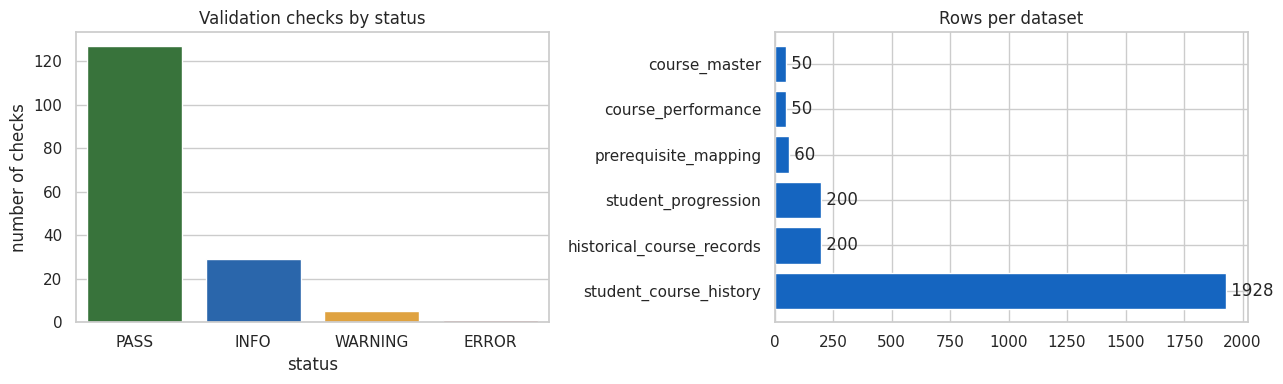


RESULT: 1 ERROR(s) found. DO NOT proceed to Apriori / Markov.
        Fix the issues in the source datasets / generator, re-upload, and re-run this notebook.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
from google.colab import files

report = pd.DataFrame(RESULTS)
print("=" * 100)
print("VALIDATION SUMMARY")
print("=" * 100)
counts = report["status"].value_counts().reindex(["PASS", "INFO", "WARNING", "ERROR"]).fillna(0).astype(int)
display(counts.rename("checks").to_frame())
display(report.groupby(["section", "status"]).size().unstack(fill_value=0))

# ---- originals untouched?
changed = [n for n in NAMES if md5(f"{DATA_DIR}/{n}.csv") != ORIG_HASH[n]]
print("\nOriginal files unchanged (MD5 re-check):", "YES" if not changed else f"NO -> {changed}")

# ---- issues list
issues = report[report["status"] != "PASS"].copy()
order = {"ERROR": 0, "WARNING": 1, "INFO": 2}
issues = issues.sort_values(by=["status", "section"], key=lambda c: c.map(order) if c.name == "status" else c)
for sev in ["ERROR", "WARNING", "INFO"]:
    sub = issues[issues["status"] == sev]
    print(f"\n{'-' * 100}\n{sev}  ({len(sub)})\n{'-' * 100}")
    if sub.empty:
        print("  none")
    for i, r in enumerate(sub.itertuples(index=False), 1):
        print(f"  {i:2d}. [{r.section}] {r.check}" + (f"\n      -> {r.detail}" if r.detail else ""))

# ---- export report (originals are NOT touched)
os.makedirs("/content/outputs", exist_ok=True)
report.to_csv("/content/outputs/task1_validation_report.csv", index=False)
report.to_json("/content/outputs/task1_validation_report.json", orient="records", indent=2)
print("\nSaved: /content/outputs/task1_validation_report.csv and .json")

# ---- charts
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=counts.index, y=counts.values, palette=["#2e7d32", "#1565c0", "#f9a825", "#c62828"], ax=ax[0])
ax[0].set_title("Validation checks by status"); ax[0].set_ylabel("number of checks")
actual = [len(dfs[n]) for n in NAMES]
ax[1].barh(NAMES, actual, color="#1565c0"); ax[1].set_title("Rows per dataset"); ax[1].invert_yaxis()
for i, v in enumerate(actual): ax[1].text(v, i, f" {v}", va="center")
plt.tight_layout(); plt.show()

# ---- gate
n_err = int(counts["ERROR"])
print("\n" + "=" * 100)
if changed:
    print("STOP: an original file changed. Re-upload the originals.")
elif n_err == 0:
    print("RESULT: no ERRORs. Data is structurally valid for preprocessing.")
    print("        Review the WARNING / INFO items above (especially the Markov state-definition decision) and reply before Task 2.")
else:
    print(f"RESULT: {n_err} ERROR(s) found. DO NOT proceed to Apriori / Markov.")
    print("        Fix the issues in the source datasets / generator, re-upload, and re-run this notebook.")
print("=" * 100)
files.download("/content/outputs/task1_validation_report.csv")   # optional: download the report

In [45]:
# ============================================================
# TASK 2: DATA PREPROCESSING AND FEATURE ENGINEERING
# SECTION 1: IMPORTS AND WORKING COPIES
# ============================================================

import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from IPython.display import display

# Confirm that Task 1 datasets are loaded
required_datasets = [
    "course_master",
    "course_performance",
    "prerequisite_mapping",
    "student_progression",
    "historical_course_records",
    "student_course_history"
]

if "dfs" not in globals():
    raise RuntimeError(
        "Task 1 DataFrames not found. Run the dataset loading cells first."
    )

missing = [name for name in required_datasets if name not in dfs]

if missing:
    raise ValueError(f"Missing datasets: {missing}")

# Preserve the original DataFrames
original_dfs = {
    name: dfs[name].copy(deep=True)
    for name in required_datasets
}

# Create independent working copies
course_master = original_dfs["course_master"].copy()
course_performance = original_dfs["course_performance"].copy()
prerequisite_mapping = original_dfs["prerequisite_mapping"].copy()
student_progression = original_dfs["student_progression"].copy()
historical_course_records = original_dfs["historical_course_records"].copy()
student_course_history = original_dfs["student_course_history"].copy()

# Central dictionary for processed datasets
processed_dfs = {
    "course_master": course_master,
    "course_performance": course_performance,
    "prerequisite_mapping": prerequisite_mapping,
    "student_progression": student_progression,
    "historical_course_records": historical_course_records,
    "student_course_history": student_course_history
}

print("TASK 2 INITIALIZED")
print("=" * 65)

for name, df in processed_dfs.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

print("\nOriginal datasets preserved.")

TASK 2 INITIALIZED
course_master: 50 rows × 13 columns
course_performance: 50 rows × 17 columns
prerequisite_mapping: 60 rows × 11 columns
student_progression: 200 rows × 19 columns
historical_course_records: 200 rows × 18 columns
student_course_history: 1,928 rows × 9 columns

Original datasets preserved.


In [46]:
# ============================================================
# TASK 2: DATA PREPROCESSING AND FEATURE ENGINEERING
# SECTION 1: IMPORTS AND WORKING COPIES
# ============================================================

import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from IPython.display import display

# Confirm that Task 1 datasets are loaded
required_datasets = [
    "course_master",
    "course_performance",
    "prerequisite_mapping",
    "student_progression",
    "historical_course_records",
    "student_course_history"
]

if "dfs" not in globals():
    raise RuntimeError(
        "Task 1 DataFrames not found. Run the dataset loading cells first."
    )

missing = [name for name in required_datasets if name not in dfs]

if missing:
    raise ValueError(f"Missing datasets: {missing}")

# Preserve the original DataFrames
original_dfs = {
    name: dfs[name].copy(deep=True)
    for name in required_datasets
}

# Create independent working copies
course_master = original_dfs["course_master"].copy()
course_performance = original_dfs["course_performance"].copy()
prerequisite_mapping = original_dfs["prerequisite_mapping"].copy()
student_progression = original_dfs["student_progression"].copy()
historical_course_records = original_dfs["historical_course_records"].copy()
student_course_history = original_dfs["student_course_history"].copy()

# Central dictionary for processed datasets
processed_dfs = {
    "course_master": course_master,
    "course_performance": course_performance,
    "prerequisite_mapping": prerequisite_mapping,
    "student_progression": student_progression,
    "historical_course_records": historical_course_records,
    "student_course_history": student_course_history
}

print("TASK 2 INITIALIZED")
print("=" * 65)

for name, df in processed_dfs.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

print("\nOriginal datasets preserved.")

TASK 2 INITIALIZED
course_master: 50 rows × 13 columns
course_performance: 50 rows × 17 columns
prerequisite_mapping: 60 rows × 11 columns
student_progression: 200 rows × 19 columns
historical_course_records: 200 rows × 18 columns
student_course_history: 1,928 rows × 9 columns

Original datasets preserved.


In [47]:
# ============================================================
# SECTION 2: CLEANING FUNCTIONS
# ============================================================

NULL_TOKENS = {
    "", "nan", "none", "null", "n/a", "na", "not applicable"
}
def clean_text(series):
    """Remove unnecessary spaces and normalize empty text."""
    result = series.astype("string").str.strip()

    result = result.mask(
        result.str.lower().isin(NULL_TOKENS),
        pd.NA
    )
    return result
def normalize_result(value):
    """Standardize student course outcomes."""
    if pd.isna(value):
        return pd.NA
    value = str(value).strip().lower()
    mapping = {
        "pass": "Passed", "passed": "Passed","fail": "Failed", "failed": "Failed", "withdrawn": "Withdrawn",
        "withdraw": "Withdrawn", "wd": "Withdrawn", "incomplete": "Incomplete",  "inc": "Incomplete"
    }
    return mapping.get(value, pd.NA)
def normalize_boolean(series):
    """Convert common true/false representations into booleans."""
    mapping = {
        "true": True, "1": True, "yes": True, "y": True,
        "false": False, "0": False, "no": False, "n": False
    }
    return series.astype("string").str.strip().str.lower().map(mapping)
def parse_semester(value):
    """Convert semester labels into semester numbers."""
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if re.search(r"\b(1st|first|1)\b", value):
        return 1
    if re.search(r"\b(2nd|second|2)\b", value):
        return 2
    return np.nan
def parse_academic_year(value):
    """Extract starting and ending academic years."""

    if pd.isna(value):
        return np.nan, np.nan
    match = re.search(
        r"(20\d{2})\s*[-–/]\s*(20\d{2})",
        str(value)
    )
    if not match:
        return np.nan, np.nan
    return int(match.group(1)), int(match.group(2))
def add_academic_period(df, semester_col="semester",
                        academic_year_col="academic_year"):
    result = df.copy()
    result["semester_no"] = result[semester_col].apply(
        parse_semester
    )
    parsed = result[academic_year_col].apply(
        parse_academic_year
    )
    result["academic_year_start"] = parsed.apply(
        lambda x: x[0]
    )
    result["academic_year_end"] = parsed.apply(
        lambda x: x[1]
    )
    result["period_index"] = (
        (result["academic_year_start"] - 2024) * 2
        + result["semester_no"]
    )
    return result
print("Cleaning functions successfully defined.")

Cleaning functions successfully defined.


In [48]:
# ============================================================
# SECTION 3: CLEAN THE SIX DATASETS
# ============================================================

# 1. Course Master
text_columns = [
    "course_id", "course_code", "course_name", "college_code", "college_name", "program_code", "program_name", "semester_offered", "course_type", "course_status", "prerequisite_course_ids"
]
for col in text_columns:
    if col in course_master.columns:
        course_master[col] = clean_text(course_master[col])

# 2. Course Performance
text_columns = [
    "performance_id", "course_id", "course_code",
    "program_code", "semester", "academic_year"
]
for col in text_columns:
    course_performance[col] = clean_text(
        course_performance[col]
    )
numeric_columns = [
    "total_enrolled", "total_passed", "total_failed", "total_withdrawn", "total_incomplete", "average_grade", "passing_rate", "failure_rate","withdrawal_rate", "total_sections", "total_repeat_students"
]
for col in numeric_columns:
    course_performance[col] = pd.to_numeric(
        course_performance[col],
        errors="coerce"
    )
# 3. Prerequisite Mapping
for col in prerequisite_mapping.select_dtypes(
    include=["object", "string"]
).columns:
    prerequisite_mapping[col] = clean_text(
        prerequisite_mapping[col]
    )
# 4. Student Progression
for col in [
    "student_id", "program_code", "college_code","progression_status", "repeat_status", "failed_course_ids", "blocked_course_ids"
]:
    student_progression[col] = clean_text(
        student_progression[col]
    )

progression_numeric = [
    "year_level", "admission_year", "previous_gpa", "current_gpa",  "total_courses_taken", "total_courses_passed","total_courses_failed", "total_courses_withdrawn","total_repeated_courses", "estimated_progression_delay"
]

for col in progression_numeric:
    student_progression[col] = pd.to_numeric(
        student_progression[col],
        errors="coerce"
    )


# 5. Historical Course Records
for col in historical_course_records.select_dtypes(
    include=["object", "string"]
).columns:
    historical_course_records[col] = clean_text(
        historical_course_records[col]
    )
historical_numeric = [
    "total_enrolled", "total_passed", "total_failed", "total_withdrawn", "failure_rate", "withdrawal_rate","repeat_rate", "average_grade"
]
for col in historical_numeric:
    historical_course_records[col] = pd.to_numeric(
        historical_course_records[col],
        errors="coerce"
    )
# 6. Student Course History
for col in [
    "history_id", "student_id", "course_id", "semester", "academic_year", "course_result"
]:
    student_course_history[col] = clean_text(
        student_course_history[col]
    )
student_course_history["course_result"] = (
    student_course_history["course_result"]
    .apply(normalize_result)
)
student_course_history["final_grade"] = pd.to_numeric(
    student_course_history["final_grade"],
    errors="coerce"
)
student_course_history["attempt_number"] = pd.to_numeric(
    student_course_history["attempt_number"],
    errors="coerce"
)
student_course_history["is_repeat"] = normalize_boolean(
    student_course_history["is_repeat"]
)
# Standardize student progression labels
progression_map = {
    "on track": "On Track","at risk": "At Risk","delayed": "Delayed"
}
student_progression["progression_status"] = (
    student_progression["progression_status"]
    .str.lower()
    .map(progression_map)
    .fillna(student_progression["progression_status"])
)
# Rebuild the processed dictionary
processed_dfs = {
    "course_master": course_master,  "course_performance": course_performance, "prerequisite_mapping": prerequisite_mapping, "student_progression": student_progression, "historical_course_records": historical_course_records, "student_course_history": student_course_history
}
print("DATA CLEANING COMPLETED.")

DATA CLEANING COMPLETED.


In [49]:
# ============================================================
# SECTION 4: CLEANING DIAGNOSTICS
# ============================================================

cleaning_reports = []

for name, df in processed_dfs.items():

    cleaning_reports.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_primary_keys": (
            int(df.iloc[:, 0].duplicated().sum())
            if len(df.columns) > 0 else 0
        )
    })

cleaning_summary = pd.DataFrame(cleaning_reports)

display(cleaning_summary)

# Missing values by column
for name, df in processed_dfs.items():

    missing = (
        df.isna()
        .sum()
        .loc[lambda x: x > 0]
        .sort_values(ascending=False)
    )

    if not missing.empty:
        print(f"\n{name} - Missing values")
        display(missing.to_frame("missing_count"))


# Invalid academic outcome labels
print("\nCourse result distribution:")

display(
    student_course_history["course_result"]
    .value_counts(dropna=False)
    .to_frame("records")
)

# Check missing grades for passed/failed courses
grade_issues = student_course_history[
    student_course_history["course_result"].isin(
        ["Passed", "Failed"]
    )
    & student_course_history["final_grade"].isna()
]

print(
    "\nPassed/Failed records with missing grades:",
    len(grade_issues)
)

# Check attempt number
attempt_issues = student_course_history[
    student_course_history["attempt_number"].isna()
    | (student_course_history["attempt_number"] < 1)
    | (
        student_course_history["attempt_number"]
        != student_course_history["attempt_number"].round()
    )
]

print("Invalid attempt numbers:", len(attempt_issues))

# Check repeat flag consistency
repeat_issues = student_course_history[
    student_course_history["is_repeat"].notna()
    & (
        student_course_history["is_repeat"]
        != (student_course_history["attempt_number"] > 1)
    )
]

print("Repeat flag inconsistencies:", len(repeat_issues))

,dataset,rows,columns,missing_cells,duplicate_rows,duplicate_primary_keys
0,course_master,50,13,12,0,0
1,course_performance,50,17,0,0,0
2,prerequisite_mapping,60,11,0,0,0
3,student_progression,200,19,344,0,0
4,historical_course_records,200,18,342,0,0
5,student_course_history,1928,9,122,0,0



course_master - Missing values


,missing_count
prerequisite_course_ids,12



student_progression - Missing values


,missing_count
blocked_course_ids,175
failed_course_ids,99
repeat_status,70



historical_course_records - Missing values


... (2 outputs left out)

,missing_count
final_grade,122



Course result distribution:


,records
course_result,
Passed,1572
Failed,234
Withdrawn,109
Incomplete,13



Passed/Failed records with missing grades: 0
Invalid attempt numbers: 0
Repeat flag inconsistencies: 0


In [50]:
# ============================================================
# SECTION 5: ACADEMIC PERIOD STANDARDIZATION
# ============================================================

course_performance = add_academic_period(course_performance)

historical_course_records = add_academic_period(
    historical_course_records
)

student_course_history = add_academic_period(
    student_course_history
)

student_progression = add_academic_period(
    student_progression,
    semester_col="current_semester",
    academic_year_col="academic_year"
)

PERIOD_LABELS = {
    1: "1st Semester, AY 2024-2025",
    2: "2nd Semester, AY 2024-2025",
    3: "1st Semester, AY 2025-2026",
    4: "2nd Semester, AY 2025-2026",
    5: "1st Semester, AY 2026-2027"
}

student_course_history["period_label"] = (
    student_course_history["period_index"]
    .map(PERIOD_LABELS)
)

historical_course_records["period_label"] = (
    historical_course_records["period_index"]
    .map(PERIOD_LABELS)
)

course_performance["period_label"] = (
    course_performance["period_index"]
    .map(PERIOD_LABELS)
)

student_progression["period_label"] = (
    student_progression["period_index"]
    .map(PERIOD_LABELS)
)

# Sort chronological student history
student_course_history = (
    student_course_history
    .sort_values([
        "student_id",
        "period_index",
        "course_id",
        "attempt_number"
    ])
    .reset_index(drop=True)
)

print("Academic period distribution:")

display(
    student_course_history
    .groupby(["period_index", "period_label"])
    .agg(
        student_count=("student_id", "nunique"),
        course_history_records=("history_id", "count")
    )
    .reset_index()
)

print("\nChronological records prepared.")

Academic period distribution:


,period_index,period_label,student_count,course_history_records
0,1,"1st Semester, AY 2024-2025",171,541
1,2,"2nd Semester, AY 2024-2025",155,410
2,3,"1st Semester, AY 2025-2026",200,456
3,4,"2nd Semester, AY 2025-2026",158,290
4,5,"1st Semester, AY 2026-2027",160,231



Chronological records prepared.


In [51]:
# ============================================================
# SECTION 6: PREREQUISITE FEATURE ENGINEERING
# ============================================================

# Build directed prerequisite graph
# Edge direction: prerequisite -> succeeding course

G = nx.DiGraph()

G.add_nodes_from(course_master["course_id"].dropna())

for row in prerequisite_mapping.itertuples(index=False):

    prerequisite = row.prerequisite_course_id
    succeeding = row.succeeding_course_id

    if pd.notna(prerequisite) and pd.notna(succeeding):
        if prerequisite != succeeding:
            G.add_edge(prerequisite, succeeding)

# Add prerequisite relationships from Course Master
def parse_course_ids(value):

    if pd.isna(value):
        return []

    return [
        x.strip()
        for x in re.split(r"[,;|]", str(value))
        if x.strip() and x.strip().lower() not in NULL_TOKENS
    ]


for row in course_master.itertuples(index=False):

    for prerequisite in parse_course_ids(
        row.prerequisite_course_ids
    ):

        G.add_edge(prerequisite, row.course_id)

# Validate graph
if not nx.is_directed_acyclic_graph(G):
    raise ValueError(
        "Circular prerequisite dependency detected. "
        "Resolve the cycle before proceeding."
    )

# Calculate graph metrics
prerequisite_features = pd.DataFrame({
    "course_id": list(G.nodes),
    "prerequisite_count": [
        G.in_degree(n) for n in G.nodes
    ],
    "succeeding_course_count": [
        G.out_degree(n) for n in G.nodes
    ],
    "total_dependency_degree": [
        G.degree(n) for n in G.nodes
    ],
    "downstream_course_count": [
        len(nx.descendants(G, n)) for n in G.nodes
    ]
})

prerequisite_features = prerequisite_features.merge(
    course_master[
        ["course_id", "course_code", "course_name", "program_code"]
    ],
    on="course_id",
    how="left"
)

prerequisite_features["dependency_flag"] = (
    prerequisite_features["succeeding_course_count"] > 0
)

prerequisite_features["potential_bottleneck_flag"] = (
    prerequisite_features["succeeding_course_count"] >= 2
)

print("PREREQUISITE FEATURES")

display(
    prerequisite_features.sort_values(
        "succeeding_course_count",
        ascending=False
    ).head(15)
)

print(
    "\nTotal prerequisite relationships:",
    G.number_of_edges()
)

print(
    "Courses serving as prerequisites:",
    int(
        (prerequisite_features["dependency_flag"]).sum()
    )
)

PREREQUISITE FEATURES


,course_id,prerequisite_count,succeeding_course_count,total_dependency_degree,downstream_course_count,course_code,course_name,program_code,dependency_flag,potential_bottleneck_flag
5,C006,0,5,5,22,MATH101,College Algebra and Trigonometry,GEN,True,True
6,C007,1,3,4,10,MATH102,Differential Calculus,GEN,True,True
9,C010,1,3,4,5,STAT201,Probability and Statistics,GEN,True,True
7,C008,1,2,3,7,MATH103,Integral Calculus,GEN,True,True
8,C009,1,2,3,9,PHYS101,General Physics 1,GEN,True,True
20,C021,1,2,3,6,CS102,Computer Programming 1,BSCS,True,True
24,C025,1,2,3,3,IT201,Database Management Systems,BSIT,True,True
36,C037,0,2,2,3,PSY101,Introduction to Psychology,BSPSY,True,True
15,C016,2,1,3,3,EE201,Circuit Analysis 1,BSEE,True,False
16,C017,2,1,3,2,EE202,Circuit Analysis 2,BSEE,True,False



Total prerequisite relationships: 48
Courses serving as prerequisites: 35


In [52]:
# ============================================================
# REVISED SECTION 7: APRIORI TRANSACTION PREPARATION
# ============================================================

history = student_course_history.copy()

history["is_pass"] = history["course_result"].eq("Passed")
history["is_fail"] = history["course_result"].eq("Failed")
history["is_withdrawn"] = history["course_result"].eq("Withdrawn")
history["is_incomplete"] = history["course_result"].eq("Incomplete")

history["is_repeat_attempt"] = (
    history["attempt_number"].gt(1)
    & history["attempt_number"].notna()
)

# Exclude unrecognized outcomes and invalid periods
history_valid = history[
    history["course_result"].isin(
        ["Passed", "Failed", "Withdrawn", "Incomplete"]
    )
    & history["period_index"].isin([1, 2, 3, 4, 5])
    & history["student_id"].notna()
    & history["course_id"].notna()
].copy()

history_valid["period_index"] = (
    history_valid["period_index"].astype(int)
)

transaction_records = []

for (sid, period), group in history_valid.groupby(
    ["student_id", "period_index"]
):

    transaction_records.append({

        "student_id": sid,
        "period_index": period,
        "period_label": PERIOD_LABELS[period],

        "courses_taken": group["course_id"].nunique(),

        "failed_courses": sorted(
            group.loc[group["is_fail"], "course_id"].unique()
        ),

        "repeated_courses": sorted(
            group.loc[
                group["is_repeat_attempt"], "course_id"
            ].unique()
        ),

        "withdrawn_courses": sorted(
            group.loc[
                group["is_withdrawn"], "course_id"
            ].unique()
        ),

        "incomplete_courses": sorted(
            group.loc[
                group["is_incomplete"], "course_id"
            ].unique()
        ),

        "passed_courses": sorted(
            group.loc[group["is_pass"], "course_id"].unique()
        )
    })


transaction_summary = pd.DataFrame(transaction_records)

transaction_summary["transaction_id"] = (
    transaction_summary["student_id"].astype(str)
    + "_SEM_"
    + transaction_summary["period_index"].astype(str)
)

course_code_map = (
    course_master.set_index("course_id")["course_code"].to_dict()
)

for col in [
    "failed_courses",
    "repeated_courses",
    "withdrawn_courses",
    "incomplete_courses",
    "passed_courses"
]:

    transaction_summary[col.replace("_courses", "_codes")] = (
        transaction_summary[col].apply(
            lambda ids: [
                course_code_map.get(cid, cid)
                for cid in ids
            ]
        )
    )

print("Revised transaction preparation completed.")

display(transaction_summary.head(10))

Revised transaction preparation completed.


,student_id,period_index,period_label,courses_taken,failed_courses,repeated_courses,withdrawn_courses,incomplete_courses,passed_courses,transaction_id,failed_codes,repeated_codes,withdrawn_codes,incomplete_codes,passed_codes
0,STU0001,1,"1st Semester, AY 2024-2025",4,[],[],[],[C001],"[C002, C006, C029]",STU0001_SEM_1,[],[],[],[GE101],"[GE102, MATH101, ACC101]"
1,STU0001,2,"2nd Semester, AY 2024-2025",3,[],[C001],[],[],"[C001, C003, C004]",STU0001_SEM_2,[],[GE101],[],[],"[GE101, GE103, GE104]"
2,STU0001,3,"1st Semester, AY 2025-2026",3,[],[],[],[C030],"[C005, C010]",STU0001_SEM_3,[],[],[],[ACC201],"[GE105, STAT201]"
3,STU0001,4,"2nd Semester, AY 2025-2026",1,[],[C030],[],[],[C030],STU0001_SEM_4,[],[ACC201],[],[],[ACC201]
4,STU0001,5,"1st Semester, AY 2026-2027",1,[],[],[],[],[C031],STU0001_SEM_5,[],[],[],[],[ACC202]
5,STU0002,1,"1st Semester, AY 2024-2025",4,[C002],[],[],[],"[C001, C006, C020]",STU0002_SEM_1,[GE102],[],[],[],"[GE101, MATH101, CS101]"
6,STU0002,2,"2nd Semester, AY 2024-2025",4,[C003],[C002],[],[],"[C002, C004, C021]",STU0002_SEM_2,[GE103],[GE102],[],[],"[GE102, GE104, CS102]"
7,STU0002,3,"1st Semester, AY 2025-2026",2,[],[C003],[],[],"[C003, C022]",STU0002_SEM_3,[],[GE103],[],[],"[GE103, CS201]"
8,STU0002,4,"2nd Semester, AY 2025-2026",2,[],[],[],[],"[C005, C025]",STU0002_SEM_4,[],[],[],[],"[GE105, IT201]"
9,STU0002,5,"1st Semester, AY 2026-2027",1,[C026],[],[],[],[],STU0002_SEM_5,[IT301],[],[],[],[]


In [53]:
# ============================================================
# SECTION 8: APRIORI TRANSACTION DATASETS
# ============================================================

def create_transaction_baskets(df, source_column):

    baskets = df[
        ["student_id", "period_index", "period_label", source_column]
    ].copy()

    baskets = baskets.rename(
        columns={source_column: "items"}
    )

    baskets["items"] = baskets["items"].apply(
        lambda x: sorted(set(x))
    )

    baskets["transaction_id"] = (
        baskets["student_id"].astype(str)
        + "_SEM_"
        + baskets["period_index"].astype(str)
    )

    return baskets


failed_transactions = create_transaction_baskets(
    transaction_summary,
    "failed_courses"
)

repeat_transactions = create_transaction_baskets(
    transaction_summary,
    "repeated_courses"
)

withdrawal_transactions = create_transaction_baskets(
    transaction_summary,
    "withdrawn_courses"
)

incomplete_transactions = create_transaction_baskets(
    transaction_summary,
    "incomplete_courses"
)

passed_transactions = create_transaction_baskets(
    transaction_summary,
    "passed_courses"
)

# Count transactions with 2 or more items
transaction_counts = pd.DataFrame({
    "transaction_type": [
        "Failed",
        "Repeated",
        "Withdrawn",
        "Incomplete",
        "Passed"
    ],

    "total_transactions": [
        len(failed_transactions),
        len(repeat_transactions),
        len(withdrawal_transactions),
        len(incomplete_transactions),
        len(passed_transactions)
    ],

    "transactions_with_2plus_items": [
        int((failed_transactions["items"].apply(len) >= 2).sum()),
        int((repeat_transactions["items"].apply(len) >= 2).sum()),
        int((withdrawal_transactions["items"].apply(len) >= 2).sum()),
        int((incomplete_transactions["items"].apply(len) >= 2).sum()),
        int((passed_transactions["items"].apply(len) >= 2).sum())
    ]
})

display(transaction_counts)

# Example failed transaction
print("\nSample failed-course transactions:")

display(
    failed_transactions[
        failed_transactions["items"].apply(len) > 0
    ].head(10)
)

,transaction_type,total_transactions,transactions_with_2plus_items
0,Failed,844,37
1,Repeated,844,63
2,Withdrawn,844,6
3,Incomplete,844,0
4,Passed,844,436



Sample failed-course transactions:


,student_id,period_index,period_label,items,transaction_id
5,STU0002,1,"1st Semester, AY 2024-2025",[C002],STU0002_SEM_1
6,STU0002,2,"2nd Semester, AY 2024-2025",[C003],STU0002_SEM_2
9,STU0002,5,"1st Semester, AY 2026-2027",[C026],STU0002_SEM_5
12,STU0003,5,"1st Semester, AY 2026-2027",[C010],STU0003_SEM_5
24,STU0007,2,"2nd Semester, AY 2024-2025",[C021],STU0007_SEM_2
37,STU0010,1,"1st Semester, AY 2024-2025","[C002, C006]",STU0010_SEM_1
41,STU0010,5,"1st Semester, AY 2026-2027",[C039],STU0010_SEM_5
43,STU0011,4,"2nd Semester, AY 2025-2026",[C004],STU0011_SEM_4
47,STU0012,3,"1st Semester, AY 2025-2026",[C032],STU0012_SEM_3
55,STU0014,4,"2nd Semester, AY 2025-2026",[C003],STU0014_SEM_4


In [54]:
# ============================================================
# SECTION 9: STUDENT-SEMESTER PROGRESSION FEATURES
# ============================================================

# Student reference information
student_info = student_progression[
    [
        "student_id",
        "program_code",
        "college_code",
        "admission_year"
    ]
].drop_duplicates("student_id").copy()

student_info["admission_year"] = pd.to_numeric(
    student_info["admission_year"],
    errors="coerce"
)

# Course year-level reference
course_year_map = (
    course_master
    .drop_duplicates("course_id")
    .set_index("course_id")["year_level"]
    .to_dict()
)

# Build prerequisite relationships by program
program_prerequisites = {}

for program, group in prerequisite_mapping.groupby("program_code"):

    program_prerequisites[program] = {}

    for row in group.itertuples(index=False):

        pre = row.prerequisite_course_id
        succeeding = row.succeeding_course_id

        program_prerequisites[program].setdefault(
            pre, set()
        ).add(succeeding)


# Fallback prerequisite graph
all_prerequisites = {
    node: set(G.successors(node))
    for node in G.nodes
}


# Period records
period_records = []

# Exclude records with unparseable periods
valid_history = history_valid[
    history_valid["period_index"].notna()
].copy()

valid_history["period_index"] = (
    valid_history["period_index"].astype(int)
)

for student_id, student_rows in valid_history.groupby("student_id"):

    info = student_info[
        student_info["student_id"] == student_id
    ]

    if info.empty:
        continue

    program = info.iloc[0]["program_code"]
    admission_year = info.iloc[0]["admission_year"]

    observed_periods = sorted(
        student_rows["period_index"].unique()
    )

    for period in observed_periods:

        # Use only information available up to this semester
        cumulative = student_rows[
            student_rows["period_index"] <= period
        ].copy()

        current = student_rows[
            student_rows["period_index"] == period
        ].copy()

        # All courses attempted up to this semester
        failed_all = set(
            cumulative.loc[
                cumulative["is_fail"], "course_id"
            ].dropna()
        )

        passed_all = set(
            cumulative.loc[
                cumulative["is_pass"], "course_id"
            ].dropna()
        )

        withdrawn_all = set(
            cumulative.loc[
                cumulative["is_withdrawn"], "course_id"
            ].dropna()
        )

        incomplete_all = set(
            cumulative.loc[
                cumulative["is_incomplete"], "course_id"
            ].dropna()
        )

        # A previously failed course is unresolved
        # until a Passed attempt appears by the current period.
        unresolved_failed = failed_all - passed_all
        unresolved_withdrawn = withdrawn_all - passed_all
        unresolved_incomplete = incomplete_all - passed_all

        unresolved_courses = (
            unresolved_failed
            | unresolved_withdrawn
            | unresolved_incomplete
        )

        # Repeat attempts in the current semester
        repeated_current = set(
            current.loc[
                current["is_repeat_attempt"], "course_id"
            ].dropna()
        )

        # Select program-specific prerequisite mappings.
        # If no program-specific mapping exists for a prerequisite,
        # use the shared graph as a fallback.
        prerequisite_map = program_prerequisites.get(
            program, {}
        )

        failed_prerequisites = set()

        for course_id in unresolved_failed:

            successors = prerequisite_map.get(
                course_id,
                all_prerequisites.get(course_id, set())
            )

            if successors:
                failed_prerequisites.add(course_id)

        # Determine expected academic year from admission year.
        period_year = 2024 + ((period - 1) // 2)

        expected_year = np.nan

        if pd.notna(admission_year):
            expected_year = period_year - int(admission_year) + 1

        # Identify overdue failed prerequisites.
        overdue_prerequisites = set()

        if pd.notna(expected_year):

            for course_id in failed_prerequisites:

                course_year = course_year_map.get(
                    course_id
                )

                if (
                    pd.notna(course_year)
                    and course_year < expected_year
                ):
                    overdue_prerequisites.add(course_id)

        # Determine directly blocked succeeding courses.
        blocked_succeeding = set()

        for prerequisite in unresolved_courses:

            successors = prerequisite_map.get(
                prerequisite,
                all_prerequisites.get(prerequisite, set())
            )

            blocked_succeeding.update(successors)

        # Exclude courses already passed by this student.
        blocked_succeeding -= passed_all

        # Semester-level outcome counts
        semester_passed = int(current["is_pass"].sum())
        semester_failed = int(current["is_fail"].sum())
        semester_withdrawn = int(current["is_withdrawn"].sum())
        semester_incomplete = int(current["is_incomplete"].sum())

        # Academic state classification
        if len(overdue_prerequisites) > 0:
            state = "Delayed"

        elif len(unresolved_courses) > 0:
            state = "At Risk"

        else:
            state = "On Track"

        period_records.append({

            "student_id": student_id,
            "program_code": program,
            "period_index": period,
            "academic_period": PERIOD_LABELS.get(period),

            "expected_year_level": expected_year,

            "semester_courses_taken": current["course_id"].nunique(),
            "semester_passed": semester_passed,
            "semester_failed": semester_failed,
            "semester_withdrawn": semester_withdrawn,
            "semester_incomplete": semester_incomplete,

            "cumulative_courses_taken": cumulative["course_id"].nunique(),
            "cumulative_failed_attempts": int(
                cumulative["is_fail"].sum()
            ),

            "unresolved_failed_count": len(unresolved_failed),
            "unresolved_withdrawn_count": len(unresolved_withdrawn),
            "unresolved_incomplete_count": len(unresolved_incomplete),

            "unresolved_course_ids": sorted(unresolved_courses),
            "failed_prerequisite_ids": sorted(failed_prerequisites),
            "overdue_prerequisite_ids": sorted(overdue_prerequisites),

            "blocked_course_ids": sorted(blocked_succeeding),
            "repeated_course_ids": sorted(repeated_current),

            "repeated_course_count": len(repeated_current),

            "progression_state": state
        })


student_semester_features = pd.DataFrame(period_records)

student_semester_features = (
    student_semester_features
    .sort_values(["student_id", "period_index"])
    .reset_index(drop=True)
)

print("STUDENT-SEMESTER FEATURES")

display(student_semester_features.head(10))

print("\nProgression state distribution:")

display(
    student_semester_features["progression_state"]
    .value_counts()
    .to_frame("student_semester_records")
)

STUDENT-SEMESTER FEATURES


,student_id,program_code,period_index,academic_period,expected_year_level,semester_courses_taken,semester_passed,semester_failed,semester_withdrawn,semester_incomplete,cumulative_courses_taken,cumulative_failed_attempts,unresolved_failed_count,unresolved_withdrawn_count,unresolved_incomplete_count,unresolved_course_ids,failed_prerequisite_ids,overdue_prerequisite_ids,blocked_course_ids,repeated_course_ids,repeated_course_count,progression_state
0,STU0001,BSA,1,"1st Semester, AY 2024-2025",1,4,3,0,0,1,4,0,0,0,1,[C001],[],[],[],[],0,At Risk
1,STU0001,BSA,2,"2nd Semester, AY 2024-2025",1,3,3,0,0,0,6,0,0,0,0,[],[],[],[],[C001],1,On Track
2,STU0001,BSA,3,"1st Semester, AY 2025-2026",2,3,2,0,0,1,9,0,0,0,1,[C030],[],[],[C031],[],0,At Risk
3,STU0001,BSA,4,"2nd Semester, AY 2025-2026",2,1,1,0,0,0,9,0,0,0,0,[],[],[],[],[C030],1,On Track
4,STU0001,BSA,5,"1st Semester, AY 2026-2027",3,1,1,0,0,0,10,0,0,0,0,[],[],[],[],[],0,On Track
5,STU0002,BSIT,1,"1st Semester, AY 2024-2025",1,4,3,1,0,0,4,1,1,0,0,[C002],[],[],[],[],0,At Risk
6,STU0002,BSIT,2,"2nd Semester, AY 2024-2025",1,4,3,1,0,0,7,2,1,0,0,[C003],[C003],[],[C005],[C002],1,At Risk
7,STU0002,BSIT,3,"1st Semester, AY 2025-2026",2,2,2,0,0,0,8,2,0,0,0,[],[],[],[],[C003],1,On Track
8,STU0002,BSIT,4,"2nd Semester, AY 2025-2026",2,2,2,0,0,0,10,2,0,0,0,[],[],[],[],[],0,On Track
9,STU0002,BSIT,5,"1st Semester, AY 2026-2027",3,1,0,1,0,0,11,3,1,0,0,[C026],[C026],[],[C028],[],0,At Risk



Progression state distribution:


,student_semester_records
progression_state,
On Track,567
At Risk,235
Delayed,42


In [55]:
# ============================================================
# SECTION 10: MARKOV CHAIN STATE SEQUENCES
# ============================================================

# Historical training periods only:
# 1 = 2024-2025 S1
# 2 = 2024-2025 S2
# 3 = 2025-2026 S1
# 4 = 2025-2026 S2

INCLUDE_CURRENT_PERIOD_IN_MARKOV_TRAINING = False

if INCLUDE_CURRENT_PERIOD_IN_MARKOV_TRAINING:
    markov_source = student_semester_features.copy()
else:
    markov_source = student_semester_features[
        student_semester_features["period_index"] <= 4
    ].copy()


markov_source = markov_source.sort_values(
    ["student_id", "period_index"]
)

# Student progression sequences
student_state_sequences = (
    markov_source
    .groupby("student_id")
    .agg(
        periods=("period_index", list),
        states=("progression_state", list),
        number_of_observations=(
            "progression_state", "count"
        )
    )
    .reset_index()
)

# Count valid consecutive transitions
transition_records = []

for student_id, group in markov_source.groupby("student_id"):

    group = group.sort_values("period_index")

    records = group[
        ["period_index", "progression_state"]
    ].to_dict("records")

    for previous, current in zip(
        records[:-1], records[1:]
    ):

        # Only consecutive semesters are accepted
        if (
            current["period_index"]
            == previous["period_index"] + 1
        ):

            transition_records.append({

                "student_id": student_id,

                "from_period": previous["period_index"],
                "to_period": current["period_index"],

                "from_state": previous["progression_state"],
                "to_state": current["progression_state"],

                "transition": (
                    previous["progression_state"]
                    + " -> "
                    + current["progression_state"]
                )
            })


markov_transitions = pd.DataFrame(
    transition_records
)

STATE_ORDER = [
    "On Track",
    "At Risk",
    "Delayed"
]

print("STUDENT STATE SEQUENCES")

display(student_state_sequences.head(10))

print("\nVALID CONSECUTIVE TRANSITIONS")

display(markov_transitions.head(10))

print(
    "\nTotal valid consecutive transitions:",
    len(markov_transitions)
)

print(
    "Students with at least two historical observations:",
    int(
        (
            student_state_sequences[
                "number_of_observations"
            ] >= 2
        ).sum()
    )
)

print("\nTransitions by semester pair:")

if not markov_transitions.empty:

    display(
        markov_transitions.groupby(
            ["from_period", "to_period"]
        ).size().rename("transition_count").to_frame()
    )
else:
    print("No valid consecutive-semester transitions found.")

STUDENT STATE SEQUENCES


,student_id,periods,states,number_of_observations
0,STU0001,"[1, 2, 3, 4]","[At Risk, On Track, At Risk, On Track]",4
1,STU0002,"[1, 2, 3, 4]","[At Risk, At Risk, On Track, On Track]",4
2,STU0003,"[3, 4]","[At Risk, On Track]",2
3,STU0004,"[1, 3]","[On Track, On Track]",2
4,STU0005,"[1, 2, 3, 4]","[On Track, On Track, On Track, At Risk]",4
5,STU0006,"[1, 2, 3]","[On Track, On Track, On Track]",3
6,STU0007,"[1, 2, 3, 4]","[On Track, At Risk, On Track, On Track]",4
7,STU0008,"[1, 2, 3, 4]","[At Risk, On Track, On Track, On Track]",4
8,STU0009,"[1, 2, 3, 4]","[On Track, On Track, On Track, On Track]",4
9,STU0010,"[1, 2, 3, 4]","[At Risk, On Track, On Track, At Risk]",4



VALID CONSECUTIVE TRANSITIONS


,student_id,from_period,to_period,from_state,to_state,transition
0,STU0001,1,2,At Risk,On Track,At Risk -> On Track
1,STU0001,2,3,On Track,At Risk,On Track -> At Risk
2,STU0001,3,4,At Risk,On Track,At Risk -> On Track
3,STU0002,1,2,At Risk,At Risk,At Risk -> At Risk
4,STU0002,2,3,At Risk,On Track,At Risk -> On Track
5,STU0002,3,4,On Track,On Track,On Track -> On Track
6,STU0003,3,4,At Risk,On Track,At Risk -> On Track
7,STU0005,1,2,On Track,On Track,On Track -> On Track
8,STU0005,2,3,On Track,On Track,On Track -> On Track
9,STU0005,3,4,On Track,At Risk,On Track -> At Risk



Total valid consecutive transitions: 468
Students with at least two historical observations: 200

Transitions by semester pair:


,,transition_count
from_period,to_period,
1,2,155
2,3,155
3,4,158


In [56]:
# ============================================================
# SECTION 11: HISTORICAL COURSE PERFORMANCE FEATURES
# ============================================================

historical_features = historical_course_records.copy()

# Normalize percentages to 0-1 fractions
def normalize_rate(series):

    numeric = pd.to_numeric(
        series,
        errors="coerce"
    )

    if numeric.max(skipna=True) > 1.5:
        return numeric / 100

    return numeric


for col in [
    "failure_rate",
    "withdrawal_rate",
    "repeat_rate"
]:

    historical_features[col + "_normalized"] = (
        normalize_rate(historical_features[col])
    )


# Chronological sorting
historical_features = historical_features.sort_values(
    ["course_id", "period_index"]
).copy()

# Previous semester performance
historical_features["previous_failure_rate"] = (
    historical_features
    .groupby("course_id")["failure_rate_normalized"]
    .shift(1)
)

historical_features["previous_withdrawal_rate"] = (
    historical_features
    .groupby("course_id")["withdrawal_rate_normalized"]
    .shift(1)
)

historical_features["previous_repeat_rate"] = (
    historical_features
    .groupby("course_id")["repeat_rate_normalized"]
    .shift(1)
)

# Semester-over-semester changes
historical_features["failure_rate_change"] = (
    historical_features["failure_rate_normalized"]
    - historical_features["previous_failure_rate"]
)

historical_features["withdrawal_rate_change"] = (
    historical_features["withdrawal_rate_normalized"]
    - historical_features["previous_withdrawal_rate"]
)

historical_features["repeat_rate_change"] = (
    historical_features["repeat_rate_normalized"]
    - historical_features["previous_repeat_rate"]
)

# Historical trend classification
historical_features["failure_trend"] = np.select(
    [
        historical_features["failure_rate_change"] > 0,
        historical_features["failure_rate_change"] < 0
    ],
    [
        "Increasing",
        "Decreasing"
    ],
    default="Unchanged or First Observation"
)

print("HISTORICAL COURSE FEATURES")

display(
    historical_features[
        [
            "course_id",
            "course_code",
            "period_label",
            "failure_rate_normalized",
            "previous_failure_rate",
            "failure_rate_change",
            "failure_trend"
        ]
    ].head(15)
)

HISTORICAL COURSE FEATURES


,course_id,course_code,period_label,failure_rate_normalized,previous_failure_rate,failure_rate_change,failure_trend
0,C001,GE101,"1st Semester, AY 2024-2025",0.0428,NaN,NaN,Unchanged or First Observation
1,C001,GE101,"2nd Semester, AY 2024-2025",0.0513,0.0428,0.0085,Increasing
2,C001,GE101,"1st Semester, AY 2025-2026",0.0424,0.0513,-0.0089,Decreasing
3,C001,GE101,"2nd Semester, AY 2025-2026",0.0483,0.0424,0.0059,Increasing
4,C002,GE102,"1st Semester, AY 2024-2025",0.2086,NaN,NaN,Unchanged or First Observation
5,C002,GE102,"2nd Semester, AY 2024-2025",0.2049,0.2086,-0.0037,Decreasing
6,C002,GE102,"1st Semester, AY 2025-2026",0.1575,0.2049,-0.0474,Decreasing
7,C002,GE102,"2nd Semester, AY 2025-2026",0.1338,0.1575,-0.0237,Decreasing
8,C003,GE103,"1st Semester, AY 2024-2025",0.0718,NaN,NaN,Unchanged or First Observation
9,C003,GE103,"2nd Semester, AY 2024-2025",0.0509,0.0718,-0.0209,Decreasing


In [57]:
# ============================================================
# SECTION 12: INTEGRATED COURSE FEATURES
# ============================================================

# Current course performance
current_course_features = course_performance.copy()

for col in [
    "passing_rate",
    "failure_rate",
    "withdrawal_rate"
]:

    current_course_features[col + "_normalized"] = (
        normalize_rate(current_course_features[col])
    )

current_course_features["repeat_student_rate"] = (
    current_course_features["total_repeat_students"]
    / current_course_features["total_enrolled"].replace(0, np.nan)
)

# Latest historical performance per course
latest_historical = (
    historical_features
    .sort_values("period_index")
    .groupby("course_id")
    .tail(1)
    [[
        "course_id",
        "failure_rate_normalized",
        "withdrawal_rate_normalized",
        "repeat_rate_normalized",
        "failure_trend",
        "failure_rate_change"
    ]]
    .rename(columns={
        "failure_rate_normalized": "latest_historical_failure_rate",
        "withdrawal_rate_normalized": "latest_historical_withdrawal_rate",
        "repeat_rate_normalized": "latest_historical_repeat_rate"
    })
)

# Merge current performance with course information
course_analytical_features = (
    course_master.merge(
        current_course_features,
        on="course_id",
        how="left",
        suffixes=("", "_performance")
    )
    .merge(
        prerequisite_features[
            [
                "course_id",
                "prerequisite_count",
                "succeeding_course_count",
                "downstream_course_count",
                "potential_bottleneck_flag"
            ]
        ],
        on="course_id",
        how="left"
    )
    .merge(
        latest_historical,
        on="course_id",
        how="left"
    )
)

print("INTEGRATED COURSE ANALYTICAL FEATURES")

display(
    course_analytical_features[
        [
            "course_id",
            "course_code",
            "course_name",
            "failure_rate_normalized",
            "withdrawal_rate_normalized",
            "repeat_student_rate",
            "succeeding_course_count",
            "downstream_course_count",
            "latest_historical_failure_rate",
            "failure_trend"
        ]
    ].head(15)
)

INTEGRATED COURSE ANALYTICAL FEATURES


,course_id,course_code,course_name,failure_rate_normalized,withdrawal_rate_normalized,repeat_student_rate,succeeding_course_count,downstream_course_count,latest_historical_failure_rate,failure_trend
0,C001,GE101,Purposive Communication,0.0426,0.0235,0.009542,0,0,0.0483,Increasing
1,C002,GE102,Mathematics in the Modern World,0.1103,0.0389,0.042180,0,0,0.1338,Decreasing
2,C003,GE103,Understanding the Self,0.0703,0.0216,0.583784,1,1,0.0546,Decreasing
3,C004,GE104,Readings in Philippine History,0.0644,0.0248,0.455446,0,0,0.0470,Decreasing
4,C005,GE105,Ethics,0.0633,0.0236,0.020167,0,0,0.0849,Increasing
5,C006,MATH101,College Algebra and Trigonometry,0.1672,0.0515,0.058454,5,22,0.1776,Increasing
6,C007,MATH102,Differential Calculus,0.3371,0.0899,0.820225,3,10,0.3333,Decreasing
7,C008,MATH103,Integral Calculus,0.1506,0.0418,0.071130,2,7,0.1884,Decreasing
8,C009,PHYS101,General Physics 1,0.2975,0.0744,0.859504,2,9,0.2824,Decreasing
9,C010,STAT201,Probability and Statistics,0.2287,0.0569,0.086493,3,5,0.2276,Increasing


In [58]:
# ============================================================
# SECTION 13: ADDITIONAL FEATURE ENGINEERING
# ============================================================

# Student-level features from the latest observed semester
latest_student_features = (
    student_semester_features
    .sort_values("period_index")
    .groupby("student_id")
    .tail(1)
    .copy()
)

# Add student profile information
latest_student_features = latest_student_features.merge(
    student_info,
    on="student_id",
    how="left",
    suffixes=("", "_profile")
)

# Risk indicators
latest_student_features["has_unresolved_failure"] = (
    latest_student_features["unresolved_failed_count"] > 0
)

latest_student_features["has_failed_prerequisite"] = (
    latest_student_features["failed_prerequisite_ids"]
    .apply(len) > 0
)

latest_student_features["has_blocked_course"] = (
    latest_student_features["blocked_course_ids"]
    .apply(len) > 0
)

latest_student_features["has_repeat"] = (
    latest_student_features["repeated_course_count"] > 0
)

# Course-level historical summary
course_history_summary = (
    historical_features
    .groupby(["course_id", "course_code"])
    .agg(
        average_historical_failure_rate=(
            "failure_rate_normalized", "mean"
        ),
        average_historical_withdrawal_rate=(
            "withdrawal_rate_normalized", "mean"
        ),
        average_historical_repeat_rate=(
            "repeat_rate_normalized", "mean"
        ),
        highest_failure_rate=(
            "failure_rate_normalized", "max"
        ),
        lowest_failure_rate=(
            "failure_rate_normalized", "min"
        ),
        historical_records=(
            "period_index", "count"
        )
    )
    .reset_index()
)

# Current course-level indicators
course_history_summary = course_history_summary.merge(
    prerequisite_features[
        [
            "course_id",
            "succeeding_course_count",
            "downstream_course_count"
        ]
    ],
    on="course_id",
    how="left"
)

print("LATEST STUDENT FEATURES")
display(latest_student_features.head(10))

print("\nCOURSE HISTORICAL SUMMARY")
display(course_history_summary.head(10))

LATEST STUDENT FEATURES


,student_id,program_code,period_index,academic_period,expected_year_level,semester_courses_taken,semester_passed,semester_failed,semester_withdrawn,semester_incomplete,cumulative_courses_taken,cumulative_failed_attempts,unresolved_failed_count,unresolved_withdrawn_count,unresolved_incomplete_count,unresolved_course_ids,failed_prerequisite_ids,overdue_prerequisite_ids,blocked_course_ids,repeated_course_ids,repeated_course_count,progression_state,program_code_profile,college_code,admission_year,has_unresolved_failure,has_failed_prerequisite,has_blocked_course,has_repeat
0,STU0200,BSBIO,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,4,0,0,0,0,[],[],[],[],[],0,On Track,BSBIO,CAS,2023,False,False,False,False
1,STU0197,BSBIO,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,4,0,0,0,0,[],[],[],[],[],0,On Track,BSBIO,CAS,2023,False,False,False,False
2,STU0031,BSPSY,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,5,0,0,0,0,[],[],[],[],[],0,On Track,BSPSY,CAS,2023,False,False,False,False
3,STU0025,BSED,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,4,1,0,0,0,[],[],[],[],[],0,On Track,BSED,CED,2023,False,False,False,False
4,STU0028,BSCS,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,5,0,0,0,0,[],[],[],[],[],0,On Track,BSCS,CCS,2023,False,False,False,False
5,STU0152,BSPSY,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,5,0,0,0,0,[],[],[],[],[],0,On Track,BSPSY,CAS,2023,False,False,False,False
6,STU0143,BSBIO,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,4,0,0,0,0,[],[],[],[],[],0,On Track,BSBIO,CAS,2023,False,False,False,False
7,STU0145,BEED,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,3,0,0,0,0,[],[],[],[],[],0,On Track,BEED,CED,2023,False,False,False,False
8,STU0160,BSBIO,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,4,0,0,0,0,[],[],[],[],[],0,On Track,BSBIO,CAS,2023,False,False,False,False
9,STU0161,BSPSY,3,"1st Semester, AY 2025-2026",3,1,1,0,0,0,5,0,0,0,0,[],[],[],[],[],0,On Track,BSPSY,CAS,2023,False,False,False,False



COURSE HISTORICAL SUMMARY


,course_id,course_code,average_historical_failure_rate,average_historical_withdrawal_rate,average_historical_repeat_rate,highest_failure_rate,lowest_failure_rate,historical_records,succeeding_course_count,downstream_course_count
0,C001,GE101,0.046200,0.017575,0.262025,0.0513,0.0424,4,0,0
1,C002,GE102,0.176200,0.045575,0.432825,0.2086,0.1338,4,0,0
2,C003,GE103,0.063250,0.021250,0.260650,0.0757,0.0509,4,1,1
3,C004,GE104,0.056700,0.018550,0.264725,0.0632,0.0470,4,0,0
4,C005,GE105,0.078075,0.023200,0.268375,0.0933,0.0647,4,0,0
5,C006,MATH101,0.176750,0.051950,0.420375,0.1838,0.1683,4,5,22
6,C007,MATH102,0.329250,0.078925,0.517575,0.3464,0.3040,4,3,10
7,C008,MATH103,0.260600,0.063200,0.487850,0.3218,0.1884,4,2,7
8,C009,PHYS101,0.285650,0.070650,0.479850,0.2890,0.2824,4,2,9
9,C010,STAT201,0.208850,0.056025,0.440875,0.2276,0.1891,4,3,5


In [59]:
# ============================================================
# SECTION 14: BEFORE-AND-AFTER SUMMARIES
# ============================================================

summary_records = []

for name in required_datasets:

    before = original_dfs[name]
    after = processed_dfs[name]

    summary_records.append({

        "dataset": name,

        "original_rows": len(before),
        "processed_rows": len(after),

        "original_columns": len(before.columns),
        "processed_columns": len(after.columns),

        "original_missing_cells": int(
            before.isna().sum().sum()
        ),

        "processed_missing_cells": int(
            after.isna().sum().sum()
        ),

        "original_duplicate_rows": int(
            before.duplicated().sum()
        ),

        "processed_duplicate_rows": int(
            after.duplicated().sum()
        )
    })


before_after_summary = pd.DataFrame(summary_records)

display(before_after_summary)


# Feature engineering summary
feature_summary = pd.DataFrame({

    "analytical_output": [
        "Failed course transactions",
        "Repeated course transactions",
        "Withdrawn course transactions",
        "Incomplete course transactions",
        "Student-semester features",
        "Markov state sequences",
        "Valid consecutive transitions",
        "Prerequisite features",
        "Historical course features",
        "Integrated course features"
    ],

    "records": [
        len(failed_transactions),
        len(repeat_transactions),
        len(withdrawal_transactions),
        len(incomplete_transactions),
        len(student_semester_features),
        len(student_state_sequences),
        len(markov_transitions),
        len(prerequisite_features),
        len(historical_features),
        len(course_analytical_features)
    ]
})

print("\nFEATURE ENGINEERING SUMMARY")
display(feature_summary)

,dataset,original_rows,processed_rows,original_columns,processed_columns,original_missing_cells,processed_missing_cells,original_duplicate_rows,processed_duplicate_rows
0,course_master,50,50,13,13,12,12,0,0
1,course_performance,50,50,17,17,0,0,0,0
2,prerequisite_mapping,60,60,11,11,0,0,0,0
3,student_progression,200,200,19,19,344,344,0,0
4,historical_course_records,200,200,18,18,171,342,0,0
5,student_course_history,1928,1928,9,9,122,122,0,0



FEATURE ENGINEERING SUMMARY


,analytical_output,records
0,Failed course transactions,844
1,Repeated course transactions,844
2,Withdrawn course transactions,844
3,Incomplete course transactions,844
4,Student-semester features,844
5,Markov state sequences,200
6,Valid consecutive transitions,468
7,Prerequisite features,50
8,Historical course features,200
9,Integrated course features,50


In [60]:
# ============================================================
# SECTION 15: FINAL TASK 2 VALIDATION
# ============================================================

task2_checks = []

def add_check(name, condition, detail=""):

    task2_checks.append({
        "validation": name,
        "status": "PASS" if condition else "WARNING",
        "details": detail
    })


# ============================================================
# 1. ORIGINAL DATASETS PRESERVED
# ============================================================

for name in required_datasets:

    unchanged = original_dfs[name].equals(dfs[name])

    add_check(
        f"{name}: original dataset preserved",
        unchanged,
        "Original DataFrame remains unchanged."
        if unchanged else "Original DataFrame was modified."
    )


# ============================================================
# 2. STANDARDIZED COURSE RESULTS
# ============================================================

allowed_results = {
    "Passed",
    "Failed",
    "Withdrawn",
    "Incomplete"
}

recognized = (
    student_course_history["course_result"]
    .dropna()
    .isin(allowed_results)
    .all()
)

add_check(
    "Standardized course results",
    recognized,
    "All non-missing outcomes use the four standard categories."
)


# ============================================================
# 3. VALID ACADEMIC PERIODS
# ============================================================

periods_valid = (
    student_course_history["period_index"]
    .dropna()
    .isin([1, 2, 3, 4, 5])
    .all()
)

add_check(
    "Valid academic period indices",
    periods_valid,
    "Academic period indices range from 1 to 5."
)


# ============================================================
# 4. TRANSACTION ID VALIDATION
# ============================================================

# Ensure transaction_summary has transaction_id
if "transaction_id" not in transaction_summary.columns:

    transaction_summary["transaction_id"] = (
        transaction_summary["student_id"].astype(str)
        + "_SEM_"
        + transaction_summary["period_index"].astype(str)
    )


# Ensure all transaction datasets have transaction_id
transaction_datasets = [
    failed_transactions,
    repeat_transactions,
    withdrawal_transactions,
    incomplete_transactions,
    passed_transactions
]

for df in transaction_datasets:

    if "transaction_id" not in df.columns:

        df["transaction_id"] = (
            df["student_id"].astype(str)
            + "_SEM_"
            + df["period_index"].astype(str)
        )


# Check uniqueness and missing IDs
transaction_logic = (
    transaction_summary["transaction_id"].notna().all()
    and transaction_summary["transaction_id"].is_unique
    and failed_transactions["transaction_id"].notna().all()
    and failed_transactions["transaction_id"].is_unique
    and repeat_transactions["transaction_id"].is_unique
    and withdrawal_transactions["transaction_id"].is_unique
    and incomplete_transactions["transaction_id"].is_unique
    and passed_transactions["transaction_id"].is_unique
)

add_check(
    "Unique student-semester transaction IDs",
    transaction_logic,
    "Each student-semester has a unique transaction identifier."
)


# ============================================================
# 5. APRIORI TRANSACTION LOGIC
# ============================================================

transaction_columns = [
    "failed_courses",
    "repeated_courses",
    "withdrawn_courses",
    "incomplete_courses",
    "passed_courses"
]

transaction_columns_exist = all(
    col in transaction_summary.columns
    for col in transaction_columns
)

add_check(
    "Apriori transaction categories",
    transaction_columns_exist,
    "Failed, repeated, withdrawn, incomplete, and passed baskets exist."
)


# Check that transaction items are valid course IDs
valid_course_ids = set(
    course_master["course_id"].dropna()
)

transaction_items_valid = True

for col in transaction_columns:

    if col not in transaction_summary.columns:
        transaction_items_valid = False
        continue

    for items in transaction_summary[col]:

        if not isinstance(items, list):
            transaction_items_valid = False
            break

        if not set(items).issubset(valid_course_ids):
            transaction_items_valid = False
            break

add_check(
    "Apriori course references",
    transaction_items_valid,
    "All transaction course IDs exist in Course Master."
)


# ============================================================
# 6. MARKOV TRANSITIONS ARE CONSECUTIVE
# ============================================================

if markov_transitions.empty:

    consecutive_valid = True

else:

    consecutive_valid = (
        (
            markov_transitions["to_period"]
            - markov_transitions["from_period"]
        ) == 1
    ).all()

add_check(
    "Markov transitions are consecutive",
    consecutive_valid,
    "Only adjacent semester observations are connected."
)


# ============================================================
# 7. CURRENT SNAPSHOT EXCLUSION
# ============================================================

if not INCLUDE_CURRENT_PERIOD_IN_MARKOV_TRAINING:

    current_excluded = (
        markov_source["period_index"].max() <= 4
        if not markov_source.empty else True
    )

else:

    current_excluded = True

add_check(
    "Current snapshot exclusion",
    current_excluded,
    "AY 2026-2027 is excluded from historical transition estimation."
)


# ============================================================
# 8. VALID STUDENT PROGRESSION STATES
# ============================================================

valid_states = {
    "On Track",
    "At Risk",
    "Delayed"
}

state_valid = (
    student_semester_features["progression_state"]
    .isin(valid_states)
    .all()
)

add_check(
    "Valid student progression states",
    state_valid,
    "All derived states belong to the three defined categories."
)


# ============================================================
# 9. PREREQUISITE GRAPH VALIDATION
# ============================================================

graph_valid = (
    nx.is_directed_acyclic_graph(G)
    and nx.number_of_selfloops(G) == 0
)

add_check(
    "Prerequisite graph validity",
    graph_valid,
    "No circular or self-referencing prerequisite relationships."
)


# ============================================================
# 10. COURSE FEATURE REFERENCES
# ============================================================

feature_ids_valid = (
    set(course_analytical_features["course_id"].dropna())
    .issubset(valid_course_ids)
)

add_check(
    "Course feature references",
    feature_ids_valid,
    "All integrated course features reference valid courses."
)


# ============================================================
# 11. STUDENT FEATURE REFERENCES
# ============================================================

valid_student_ids = set(
    student_progression["student_id"].dropna()
)

student_feature_ids_valid = (
    set(student_semester_features["student_id"].dropna())
    .issubset(valid_student_ids)
)

add_check(
    "Student feature references",
    student_feature_ids_valid,
    "All student-semester features reference valid students."
)


# ============================================================
# 12. ATTEMPT NUMBER VALIDATION
# ============================================================

attempt_valid = (
    student_course_history["attempt_number"].dropna()
    .ge(1).all()
    and (
        student_course_history["attempt_number"].dropna()
        % 1 == 0
    ).all()
)

add_check(
    "Valid course attempt numbers",
    attempt_valid,
    "Attempt numbers are positive integers."
)


# ============================================================
# 13. REPEAT FLAG VALIDATION
# ============================================================

repeat_valid = (
    student_course_history.loc[
        student_course_history["is_repeat"].notna(),
        "is_repeat"
    ]
    ==
    (
        student_course_history.loc[
            student_course_history["is_repeat"].notna(),
            "attempt_number"
        ] > 1
    )
).all()

add_check(
    "Repeat attempt consistency",
    repeat_valid,
    "Repeat flags agree with attempt numbers."
)


# ============================================================
# 14. DISPLAY FINAL VALIDATION RESULTS
# ============================================================

task2_validation = pd.DataFrame(task2_checks)

print("=" * 70)
print("TASK 2: FINAL DATA PREPROCESSING VALIDATION")
print("=" * 70)

display(task2_validation)


# ============================================================
# 15. VALIDATION SUMMARY
# ============================================================

validation_counts = (
    task2_validation["status"]
    .value_counts()
    .reindex(["PASS", "WARNING"], fill_value=0)
)

print("\nVALIDATION SUMMARY")
print("-" * 40)

print("Passed checks:", validation_counts["PASS"])
print("Warnings:", validation_counts["WARNING"])
print("Total checks:", len(task2_validation))

if (task2_validation["status"] == "WARNING").any():

    print("\nWARNING: Some validation checks require review.")

    display(
        task2_validation[
            task2_validation["status"] == "WARNING"
        ]
    )

else:

    print("\nSUCCESS: All Task 2 validation checks passed!")

print("\nTASK 2 VALIDATION COMPLETED.")

TASK 2: FINAL DATA PREPROCESSING VALIDATION


,validation,status,details
0,course_master: original dataset preserved,PASS,Original DataFrame remains unchanged.
1,course_performance: original dataset preserved,PASS,Original DataFrame remains unchanged.
2,prerequisite_mapping: original dataset preserved,PASS,Original DataFrame remains unchanged.
3,student_progression: original dataset preserved,PASS,Original DataFrame remains unchanged.
4,historical_course_records: original dataset preserved,PASS,Original DataFrame remains unchanged.
5,student_course_history: original dataset preserved,PASS,Original DataFrame remains unchanged.
6,Standardized course results,PASS,All non-missing outcomes use the four standard categories.
7,Valid academic period indices,PASS,Academic period indices range from 1 to 5.
8,Unique student-semester transaction IDs,PASS,Each student-semester has a unique transaction identifier.
9,Apriori transaction categories,PASS,"Failed, repeated, withdrawn, incomplete, and passed baskets exist."



VALIDATION SUMMARY
----------------------------------------
Passed checks: 19
Warnings: 0
Total checks: 19

SUCCESS: All Task 2 validation checks passed!

TASK 2 VALIDATION COMPLETED.


In [61]:
# ============================================================
# SECTION 16: EXPORT TASK 2 OUTPUTS
# ============================================================

import os
import zipfile

OUTPUT_DIR = "/content/task2_preprocessed_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Update processed dictionary with standardized periods
processed_dfs = {
    "course_master": course_master,
    "course_performance": course_performance,
    "prerequisite_mapping": prerequisite_mapping,
    "student_progression": student_progression,
    "historical_course_records": historical_course_records,
    "student_course_history": student_course_history
}

# Main preprocessed datasets
for name, df in processed_dfs.items():

    df.to_csv(
        f"{OUTPUT_DIR}/{name}_preprocessed.csv",
        index=False
    )

# Additional analytical datasets
exports = {

    "apriori_transaction_summary": transaction_summary,

    "apriori_failed_transactions": failed_transactions,

    "apriori_repeat_transactions": repeat_transactions,

    "apriori_withdrawal_transactions": withdrawal_transactions,

    "apriori_incomplete_transactions": incomplete_transactions,

    "apriori_passed_transactions": passed_transactions,

    "prerequisite_features": prerequisite_features,

    "student_semester_features": student_semester_features,

    "student_state_sequences": student_state_sequences,

    "markov_transitions_prepared": markov_transitions,

    "historical_course_features": historical_features,

    "course_analytical_features": course_analytical_features,

    "course_history_summary": course_history_summary,

    "latest_student_features": latest_student_features,

    "task2_validation": task2_validation
}

for name, df in exports.items():

    # CSV export
    csv_df = df.copy()

    for col in csv_df.columns:

        if csv_df[col].apply(
            lambda x: isinstance(x, (list, tuple, set))
        ).any():

            csv_df[col] = csv_df[col].apply(
                lambda x: json.dumps(
                    list(x) if isinstance(x, (set, tuple)) else x
                )
                if isinstance(x, (list, tuple, set))
                else x
            )

    csv_df.to_csv(
        f"{OUTPUT_DIR}/{name}.csv",
        index=False
    )

    # JSON export
    df.to_json(
        f"{OUTPUT_DIR}/{name}.json",
        orient="records",
        indent=2
    )


# Create README
readme = """
TASK 2: DATA PREPROCESSING AND FEATURE ENGINEERING

Project: Course Bottleneck Detection and Academic Progression Analysis

MAIN OUTPUTS:

1. Preprocessed original datasets
2. Apriori student-semester transactions
3. Prerequisite dependency features
4. Student-semester progression features
5. Markov Chain state sequences
6. Valid consecutive-semester transitions
7. Historical course performance features
8. Integrated course analytical features
9. Latest student analytical features
10. Task 2 validation report

IMPORTANT NOTES:

- Original datasets were preserved.
- Failed course transactions are grouped by student and semester.
- Repeated courses are represented separately.
- Markov states are derived from historical academic outcomes.
- Period 5 (AY 2026-2027) is excluded from historical Markov
  transition estimation by default.
- Missing grades and unrecognized outcomes are not fabricated.
- The student progression states are operational analytical
  proxies, not official university classifications.
- No Apriori rules or Markov transition probabilities have
  been calculated in this task.

NEXT TASK:

Task 3 - Apriori Association Rule Mining.
"""

with open(
    f"{OUTPUT_DIR}/README_Task2.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(readme)


# ZIP all outputs
zip_path = "/content/TASK2_Preprocessed_Outputs.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in os.listdir(OUTPUT_DIR):

        full_path = os.path.join(
            OUTPUT_DIR,
            filename
        )

        zipf.write(
            full_path,
            arcname=filename
        )


print("TASK 2 EXPORT COMPLETED")
print("=" * 65)

print("Output directory:", OUTPUT_DIR)
print("ZIP file:", zip_path)

print("\nFiles generated:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("✓", filename)

# Download the ZIP
from google.colab import files

files.download(zip_path)

TASK 2 EXPORT COMPLETED
Output directory: /content/task2_preprocessed_outputs
ZIP file: /content/TASK2_Preprocessed_Outputs.zip

Files generated:
✓ README_Task2.txt
✓ apriori_failed_transactions.csv
✓ apriori_failed_transactions.json
✓ apriori_incomplete_transactions.csv
✓ apriori_incomplete_transactions.json
✓ apriori_passed_transactions.csv
✓ apriori_passed_transactions.json
✓ apriori_repeat_transactions.csv
✓ apriori_repeat_transactions.json
✓ apriori_transaction_summary.csv
✓ apriori_transaction_summary.json
✓ apriori_withdrawal_transactions.csv
✓ apriori_withdrawal_transactions.json
✓ course_analytical_features.csv
✓ course_analytical_features.json
✓ course_history_summary.csv
✓ course_history_summary.json
✓ course_master_preprocessed.csv
✓ course_performance_preprocessed.csv
✓ historical_course_features.csv
✓ historical_course_features.json
✓ historical_course_records_preprocessed.csv
✓ latest_student_features.csv
✓ latest_student_features.json
✓ markov_transitions_prepared.csv
✓

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
# ============================================================
# TASK 3: APRIORI ASSOCIATION RULE MINING
# SECTION 1: INSTALLATION AND IMPORTS
# ============================================================

!pip install -q mlxtend

import pandas as pd
import numpy as np
import json
import ast
import os
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

from IPython.display import display

print("Apriori libraries successfully imported.")

Apriori libraries successfully imported.


In [63]:
# ============================================================
# SECTION 2: TRANSACTION PREPARATION
# ============================================================

# Use existing Task 2 DataFrames.
# If they are not in memory, load the exported CSV files.

if "failed_transactions" not in globals():

    failed_transactions = pd.read_csv(
        "/content/task2_preprocessed_outputs/apriori_failed_transactions.csv"
    )

if "repeat_transactions" not in globals():

    repeat_transactions = pd.read_csv(
        "/content/task2_preprocessed_outputs/apriori_repeat_transactions.csv"
    )

if "course_master" not in globals():

    course_master = pd.read_csv(
        "/content/task2_preprocessed_outputs/course_master_preprocessed.csv"
    )


# Convert JSON strings or existing lists into Python lists
def parse_items(value):

    if isinstance(value, list):
        return value

    if isinstance(value, (tuple, set)):
        return list(value)

    if pd.isna(value):
        return []

    if isinstance(value, str):

        try:
            result = json.loads(value)

        except (json.JSONDecodeError, TypeError):
            try:
                result = ast.literal_eval(value)
            except (ValueError, SyntaxError):
                raise ValueError(
                    f"Unable to parse transaction: {value}"
                )

        if isinstance(result, list):
            return result

    raise ValueError(f"Invalid transaction format: {value}")


# Prepare failed-course transactions
failed_transactions = failed_transactions.copy()

failed_transactions["items"] = (
    failed_transactions["items"].apply(parse_items)
)


# Prepare repeated-course transactions
repeat_transactions = repeat_transactions.copy()

repeat_transactions["items"] = (
    repeat_transactions["items"].apply(parse_items)
)


# Remove duplicate course IDs within each basket
failed_baskets = [
    sorted(set(items))
    for items in failed_transactions["items"]
]

repeat_baskets = [
    sorted(set(items))
    for items in repeat_transactions["items"]
]


# Validate course references
valid_course_ids = set(
    course_master["course_id"].dropna().astype(str)
)

failed_reference_valid = all(
    set(basket).issubset(valid_course_ids)
    for basket in failed_baskets
)

repeat_reference_valid = all(
    set(basket).issubset(valid_course_ids)
    for basket in repeat_baskets
)

assert failed_reference_valid, "Invalid course ID in failed transactions."
assert repeat_reference_valid, "Invalid course ID in repeat transactions."


# Dataset summary
transaction_overview = pd.DataFrame({

    "transaction_type": [
        "Failed Courses",
        "Repeated Courses"
    ],

    "total_transactions": [
        len(failed_baskets),
        len(repeat_baskets)
    ],

    "non_empty_transactions": [
        sum(len(x) > 0 for x in failed_baskets),
        sum(len(x) > 0 for x in repeat_baskets)
    ],

    "transactions_with_multiple_items": [
        sum(len(x) >= 2 for x in failed_baskets),
        sum(len(x) >= 2 for x in repeat_baskets)
    ],

    "total_course_occurrences": [
        sum(len(x) for x in failed_baskets),
        sum(len(x) for x in repeat_baskets)
    ]
})

print("TRANSACTION DATASET OVERVIEW")

display(transaction_overview)

print("\nSample failed-course transactions:")

display(
    failed_transactions[
        ["student_id", "period_label", "items"]
    ].head(10)
)

print("\nSample repeated-course transactions:")

display(
    repeat_transactions[
        ["student_id", "period_label", "items"]
    ].head(10)
)

TRANSACTION DATASET OVERVIEW


,transaction_type,total_transactions,non_empty_transactions,transactions_with_multiple_items,total_course_occurrences
0,Failed Courses,844,193,37,234
1,Repeated Courses,844,239,63,313



Sample failed-course transactions:


,student_id,period_label,items
0,STU0001,"1st Semester, AY 2024-2025",[]
1,STU0001,"2nd Semester, AY 2024-2025",[]
2,STU0001,"1st Semester, AY 2025-2026",[]
3,STU0001,"2nd Semester, AY 2025-2026",[]
4,STU0001,"1st Semester, AY 2026-2027",[]
5,STU0002,"1st Semester, AY 2024-2025",[C002]
6,STU0002,"2nd Semester, AY 2024-2025",[C003]
7,STU0002,"1st Semester, AY 2025-2026",[]
8,STU0002,"2nd Semester, AY 2025-2026",[]
9,STU0002,"1st Semester, AY 2026-2027",[C026]



Sample repeated-course transactions:


,student_id,period_label,items
0,STU0001,"1st Semester, AY 2024-2025",[]
1,STU0001,"2nd Semester, AY 2024-2025",[C001]
2,STU0001,"1st Semester, AY 2025-2026",[]
3,STU0001,"2nd Semester, AY 2025-2026",[C030]
4,STU0001,"1st Semester, AY 2026-2027",[]
5,STU0002,"1st Semester, AY 2024-2025",[]
6,STU0002,"2nd Semester, AY 2024-2025",[C002]
7,STU0002,"1st Semester, AY 2025-2026",[C003]
8,STU0002,"2nd Semester, AY 2025-2026",[]
9,STU0002,"1st Semester, AY 2026-2027",[]


In [64]:
# ============================================================
# SECTION 3: APRIORI PARAMETERS
# ============================================================

MIN_SUPPORT = 0.0035

MIN_CONFIDENCE = 0.20

MIN_ITEMSET_LENGTH = 2

MAX_ITEMSET_LENGTH = 4

# Alternative support thresholds for sensitivity analysis
SUPPORT_THRESHOLDS = [
    0.0035,
    0.005,
    0.01
]

CONFIDENCE_THRESHOLDS = [
    0.20,
    0.30,
    0.50
]

print("APRIORI CONFIGURATION")
print("=" * 50)

print("Minimum support:", MIN_SUPPORT)
print("Minimum confidence:", MIN_CONFIDENCE)
print("Minimum itemset size:", MIN_ITEMSET_LENGTH)
print("Maximum itemset size:", MAX_ITEMSET_LENGTH)

print(
    "\nMinimum expected occurrences:",
    int(np.ceil(MIN_SUPPORT * len(failed_baskets)))
)

APRIORI CONFIGURATION
Minimum support: 0.0035
Minimum confidence: 0.2
Minimum itemset size: 2
Maximum itemset size: 4

Minimum expected occurrences: 3


In [65]:
# ============================================================
# SECTION 4: TRANSACTION ENCODING
# ============================================================

def encode_transactions(baskets):

    encoder = TransactionEncoder()

    encoded_array = encoder.fit(baskets).transform(baskets)

    encoded_df = pd.DataFrame(
        encoded_array,
        columns=encoder.columns_,
        dtype=bool
    )

    return encoded_df


failed_encoded = encode_transactions(
    failed_baskets
)

repeat_encoded = encode_transactions(
    repeat_baskets
)


print("FAILED COURSE MATRIX")
print("Rows:", failed_encoded.shape[0])
print("Course columns:", failed_encoded.shape[1])

display(failed_encoded.head())


print("\nREPEATED COURSE MATRIX")
print("Rows:", repeat_encoded.shape[0])
print("Course columns:", repeat_encoded.shape[1])

display(repeat_encoded.head())

FAILED COURSE MATRIX
Rows: 844
Course columns: 39


,C001,C002,C003,C004,C005,C006,C007,C008,C009,C010,C011,C012,C014,C016,C018,C019,C020,C021,C022,C023,C024,C025,C026,C027,C029,C030,C031,C032,C033,C035,C036,C039,C041,C042,C043,C044,C046,C048,C049
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False



REPEATED COURSE MATRIX
Rows: 844
Course columns: 43


,C001,C002,C003,C004,C005,C006,C007,C008,C009,C010,C011,C012,C014,C016,C017,C018,C020,C021,C022,C023,C024,C025,C026,C027,C029,C030,C031,C032,C033,C034,C035,C037,C039,C041,C042,C043,C044,C045,C046,C047,C048,C049,C050
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [66]:
# ============================================================
# SECTION 5: APRIORI - FAILED COURSE ITEMSETS
# ============================================================

failed_frequent_itemsets = apriori(
    failed_encoded,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_ITEMSET_LENGTH
)

# Add itemset size
if not failed_frequent_itemsets.empty:

    failed_frequent_itemsets["itemset_length"] = (
        failed_frequent_itemsets["itemsets"].apply(len)
    )

    failed_frequent_itemsets["course_ids"] = (
        failed_frequent_itemsets["itemsets"].apply(
            lambda x: ", ".join(sorted(x))
        )
    )

    failed_frequent_itemsets["occurrence_count"] = (
        np.rint(
            failed_frequent_itemsets["support"]
            * len(failed_encoded)
        ).astype(int)
    )

    failed_frequent_itemsets = (
        failed_frequent_itemsets.sort_values(
            ["itemset_length", "support"],
            ascending=[False, False]
        )
        .reset_index(drop=True)
    )

print("FAILED COURSE FREQUENT ITEMSETS")

if failed_frequent_itemsets.empty:

    print("No frequent itemsets found at the selected support threshold.")

else:

    display(
        failed_frequent_itemsets[
            [
                "course_ids",
                "itemset_length",
                "support",
                "occurrence_count"
            ]
        ].head(30)
    )

print(
    "\nTotal frequent itemsets:",
    len(failed_frequent_itemsets)
)

FAILED COURSE FREQUENT ITEMSETS


,course_ids,itemset_length,support,occurrence_count
0,"C002, C006",2,0.005924,5
1,"C002, C003",2,0.004739,4
2,"C001, C002",2,0.003555,3
3,"C009, C042",2,0.003555,3
4,"C022, C025",2,0.003555,3
5,C002,1,0.049763,42
6,C010,1,0.042654,36
7,C006,1,0.021327,18
8,C007,1,0.020142,17
9,C005,1,0.015403,13



Total frequent itemsets: 28


In [67]:
# ============================================================
# SECTION 6: APRIORI ASSOCIATION RULES
# ============================================================

def generate_rules(frequent_itemsets, min_confidence):

    if frequent_itemsets.empty:
        return pd.DataFrame()

    multi_itemsets = frequent_itemsets[
        frequent_itemsets["itemsets"].apply(len) >= 2
    ].copy()

    if multi_itemsets.empty:
        return pd.DataFrame()

    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=min_confidence
    )

    if rules.empty:
        return rules

    # Remove self-relations and keep meaningful rules
    rules = rules[
        rules["antecedents"].apply(len) >= 1
        & rules["consequents"].apply(len).ge(1)
    ].copy()

    # Human-readable course IDs
    rules["antecedent_courses"] = (
        rules["antecedents"].apply(
            lambda x: ", ".join(sorted(x))
        )
    )

    rules["consequent_courses"] = (
        rules["consequents"].apply(
            lambda x: ", ".join(sorted(x))
        )
    )

    rules["total_courses"] = (
        rules["antecedents"].apply(len)
        + rules["consequents"].apply(len)
    )

    # Sort based on academic relevance:
    # Lift first, then confidence and support.
    rules = rules.sort_values(
        ["lift", "confidence", "support"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    return rules


failed_rules = generate_rules(
    failed_frequent_itemsets,
    MIN_CONFIDENCE
)

print("FAILED COURSE ASSOCIATION RULES")

if failed_rules.empty:

    print(
        "No rules met the selected minimum support "
        "and confidence thresholds."
    )

else:

    display(
        failed_rules[
            [
                "antecedent_courses",
                "consequent_courses",
                "support",
                "confidence",
                "lift",
                "leverage",
                "conviction"
            ]
        ].head(30)
    )

print("\nTotal association rules:", len(failed_rules))

FAILED COURSE ASSOCIATION RULES


,antecedent_courses,consequent_courses,support,confidence,lift,leverage,conviction
0,C042,C009,0.003555,1.000000,140.666667,0.003529,inf
1,C009,C042,0.003555,0.500000,140.666667,0.003529,1.992891
2,C025,C022,0.003555,0.750000,52.750000,0.003487,3.943128
3,C022,C025,0.003555,0.250000,52.750000,0.003487,1.327014
4,C001,C002,0.003555,0.500000,10.047619,0.003201,1.900474
5,C003,C002,0.004739,0.400000,8.038095,0.004150,1.583728
6,C006,C002,0.005924,0.277778,5.582011,0.004863,1.315713



Total association rules: 7


In [68]:
# ============================================================
# SECTION 7: COURSE INFORMATION MAPPING
# ============================================================

course_lookup = (
    course_master[
        ["course_id", "course_code", "course_name",
         "college_name", "program_name"]
    ]
    .drop_duplicates("course_id")
    .copy()
)

course_lookup["course_id"] = (
    course_lookup["course_id"].astype(str)
)

course_name_map = dict(
    zip(
        course_lookup["course_id"],
        course_lookup["course_name"]
    )
)

course_code_map = dict(
    zip(
        course_lookup["course_id"],
        course_lookup["course_code"]
    )
)


def describe_courses(course_ids):

    ids = sorted(course_ids)

    return " | ".join(
        f"{course_code_map.get(cid, cid)} - "
        f"{course_name_map.get(cid, 'Unknown Course')}"
        for cid in ids
    )


if not failed_frequent_itemsets.empty:

    failed_frequent_itemsets["course_names"] = (
        failed_frequent_itemsets["itemsets"].apply(
            describe_courses
        )
    )


if not failed_rules.empty:

    failed_rules["antecedent_names"] = (
        failed_rules["antecedents"].apply(
            describe_courses
        )
    )

    failed_rules["consequent_names"] = (
        failed_rules["consequents"].apply(
            describe_courses
        )
    )


print("COURSE-NAME ENRICHED ASSOCIATION RULES")

if not failed_rules.empty:

    display(
        failed_rules[
            [
                "antecedent_names",
                "consequent_names",
                "support",
                "confidence",
                "lift"
            ]
        ].head(20)
    )

COURSE-NAME ENRICHED ASSOCIATION RULES


,antecedent_names,consequent_names,support,confidence,lift
0,BIO102 - Cell Biology,PHYS101 - General Physics 1,0.003555,1.000000,140.666667
1,PHYS101 - General Physics 1,BIO102 - Cell Biology,0.003555,0.500000,140.666667
2,IT201 - Database Management Systems,CS201 - Data Structures and Algorithms,0.003555,0.750000,52.750000
3,CS201 - Data Structures and Algorithms,IT201 - Database Management Systems,0.003555,0.250000,52.750000
4,GE101 - Purposive Communication,GE102 - Mathematics in the Modern World,0.003555,0.500000,10.047619
5,GE103 - Understanding the Self,GE102 - Mathematics in the Modern World,0.004739,0.400000,8.038095
6,MATH101 - College Algebra and Trigonometry,GE102 - Mathematics in the Modern World,0.005924,0.277778,5.582011


In [69]:
# ============================================================
# SECTION 8: APRIORI - REPEATED COURSE ANALYSIS
# ============================================================

repeat_frequent_itemsets = apriori(
    repeat_encoded,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_ITEMSET_LENGTH
)

if not repeat_frequent_itemsets.empty:

    repeat_frequent_itemsets["itemset_length"] = (
        repeat_frequent_itemsets["itemsets"].apply(len)
    )

    repeat_frequent_itemsets["course_ids"] = (
        repeat_frequent_itemsets["itemsets"].apply(
            lambda x: ", ".join(sorted(x))
        )
    )

    repeat_frequent_itemsets["occurrence_count"] = (
        np.rint(
            repeat_frequent_itemsets["support"]
            * len(repeat_encoded)
        ).astype(int)
    )

    repeat_frequent_itemsets["course_names"] = (
        repeat_frequent_itemsets["itemsets"].apply(
            describe_courses
        )
    )

repeat_rules = generate_rules(
    repeat_frequent_itemsets,
    MIN_CONFIDENCE
)

if not repeat_rules.empty:

    repeat_rules["antecedent_names"] = (
        repeat_rules["antecedents"].apply(
            describe_courses
        )
    )

    repeat_rules["consequent_names"] = (
        repeat_rules["consequents"].apply(
            describe_courses
        )
    )


print("REPEATED COURSE FREQUENT ITEMSETS")

if repeat_frequent_itemsets.empty:

    print("No frequent repeated-course itemsets found.")

else:

    display(
        repeat_frequent_itemsets[
            [
                "course_names",
                "itemset_length",
                "support",
                "occurrence_count"
            ]
        ].head(20)
    )


print("\nREPEATED COURSE ASSOCIATION RULES")

if repeat_rules.empty:

    print("No repeated-course association rules found.")

else:

    display(
        repeat_rules[
            [
                "antecedent_names",
                "consequent_names",
                "support",
                "confidence",
                "lift"
            ]
        ].head(20)
    )

REPEATED COURSE FREQUENT ITEMSETS


,course_names,itemset_length,support,occurrence_count
0,GE101 - Purposive Communication,1,0.011848,10
1,GE102 - Mathematics in the Modern World,1,0.065166,55
2,GE103 - Understanding the Self,1,0.017773,15
3,GE104 - Readings in Philippine History,1,0.008294,7
4,GE105 - Ethics,1,0.024882,21
5,MATH101 - College Algebra and Trigonometry,1,0.034360,29
6,MATH102 - Differential Calculus,1,0.024882,21
7,MATH103 - Integral Calculus,1,0.004739,4
8,PHYS101 - General Physics 1,1,0.009479,8
9,STAT201 - Probability and Statistics,1,0.046209,39



REPEATED COURSE ASSOCIATION RULES


,antecedent_names,consequent_names,support,confidence,lift
0,BIO102 - Cell Biology,PHYS101 - General Physics 1,0.003555,0.750000,79.125000
1,PHYS101 - General Physics 1,BIO102 - Cell Biology,0.003555,0.375000,79.125000
2,IT201 - Database Management Systems,CS201 - Data Structures and Algorithms,0.003555,0.600000,42.200000
3,CS201 - Data Structures and Algorithms,IT201 - Database Management Systems,0.003555,0.250000,42.200000
4,GE104 - Readings in Philippine History,GE103 - Understanding the Self,0.003555,0.428571,24.114286
5,ED201 - Facilitating Learner-Centered Teaching,STAT201 - Probability and Statistics,0.003555,0.600000,12.984615
6,ACC201 - Intermediate Accounting 1,STAT201 - Probability and Statistics,0.004739,0.333333,7.213675
7,CS101 - Introduction to Computing,GE102 - Mathematics in the Modern World,0.003555,0.428571,6.576623
8,MATH101 - College Algebra and Trigonometry,GE102 - Mathematics in the Modern World,0.010664,0.310345,4.762382
9,GE101 - Purposive Communication,GE102 - Mathematics in the Modern World,0.003555,0.300000,4.603636


In [70]:
# ============================================================
# SECTION 9: THRESHOLD SENSITIVITY ANALYSIS
# ============================================================

threshold_results = []

for support_value in SUPPORT_THRESHOLDS:

    itemsets = apriori(
        failed_encoded,
        min_support=support_value,
        use_colnames=True,
        max_len=MAX_ITEMSET_LENGTH
    )

    multi_count = (
        itemsets["itemsets"].apply(len).ge(2).sum()
        if not itemsets.empty else 0
    )

    for confidence_value in CONFIDENCE_THRESHOLDS:

        rules = generate_rules(
            itemsets,
            confidence_value
        )

        threshold_results.append({

            "minimum_support": support_value,

            "minimum_confidence": confidence_value,

            "frequent_itemsets": len(itemsets),

            "multi_course_itemsets": int(multi_count),

            "association_rules": len(rules),

            "strong_rules_lift_gt_1": (
                int((rules["lift"] > 1).sum())
                if not rules.empty else 0
            )
        })


threshold_analysis = pd.DataFrame(threshold_results)

print("APRIORI THRESHOLD COMPARISON")

display(threshold_analysis)

APRIORI THRESHOLD COMPARISON


,minimum_support,minimum_confidence,frequent_itemsets,multi_course_itemsets,association_rules,strong_rules_lift_gt_1
0,0.0035,0.2,28,5,7,7
1,0.0035,0.3,28,5,5,5
2,0.0035,0.5,28,5,4,4
3,0.0050,0.2,13,1,1,1
4,0.0050,0.3,13,1,0,0
5,0.0050,0.5,13,1,0,0
6,0.0100,0.2,7,0,0,0
7,0.0100,0.3,7,0,0,0
8,0.0100,0.5,7,0,0,0


In [71]:
# ============================================================
# SECTION 10: COURSE BOTTLENECK ASSOCIATION FREQUENCY
# ============================================================

from collections import Counter

course_association_counter = Counter()

for _, row in failed_rules.iterrows():

    involved_courses = (
        set(row["antecedents"])
        | set(row["consequents"])
    )

    for course_id in involved_courses:

        course_association_counter[course_id] += 1


course_association_summary = pd.DataFrame({

    "course_id": list(course_association_counter.keys()),

    "association_count": list(
        course_association_counter.values()
    )
})

if not course_association_summary.empty:

    course_association_summary = (
        course_association_summary
        .merge(
            course_lookup,
            on="course_id",
            how="left"
        )
        .sort_values(
            "association_count",
            ascending=False
        )
        .reset_index(drop=True)
    )

print("COURSES APPEARING IN MULTIPLE ASSOCIATION RULES")

if course_association_summary.empty:

    print("No courses were included in qualifying association rules.")

else:

    display(course_association_summary.head(20))

COURSES APPEARING IN MULTIPLE ASSOCIATION RULES


,course_id,association_count,course_code,course_name,college_name,program_name
0,C002,3,GE102,Mathematics in the Modern World,College of Arts and Sciences,General Education and Service Courses
1,C042,2,BIO102,Cell Biology,College of Arts and Sciences,BS Biology
2,C025,2,IT201,Database Management Systems,College of Computing Studies,BS Information Technology
3,C009,2,PHYS101,General Physics 1,College of Arts and Sciences,General Education and Service Courses
4,C022,2,CS201,Data Structures and Algorithms,College of Computing Studies,BS Computer Science
5,C001,1,GE101,Purposive Communication,College of Arts and Sciences,General Education and Service Courses
6,C003,1,GE103,Understanding the Self,College of Arts and Sciences,General Education and Service Courses
7,C006,1,MATH101,College Algebra and Trigonometry,College of Arts and Sciences,General Education and Service Courses


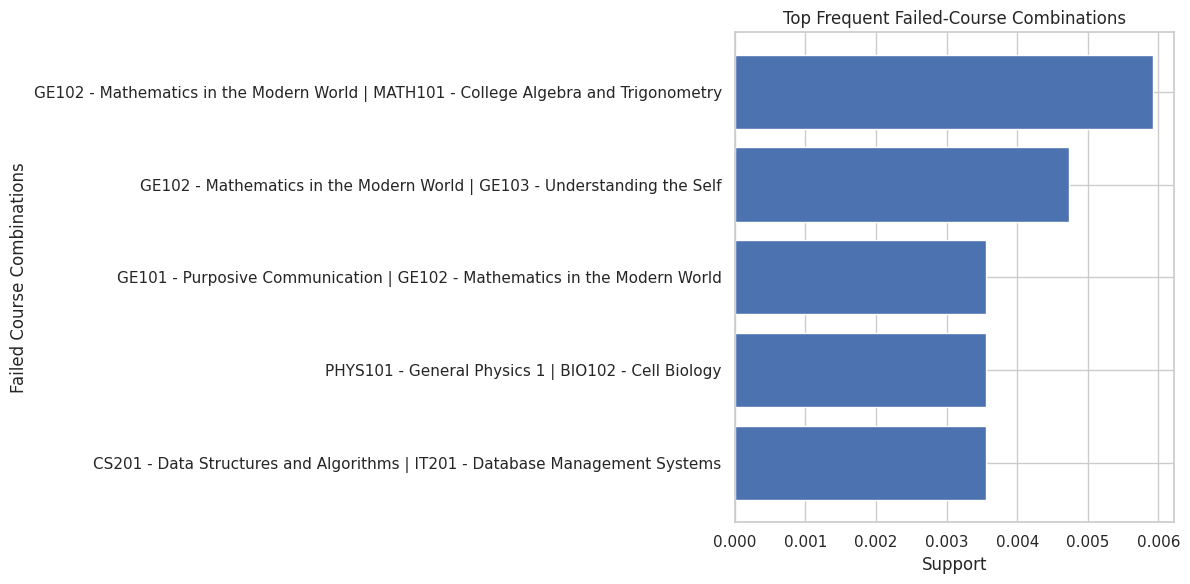

In [72]:
# ============================================================
# SECTION 11: TOP FREQUENT FAILED-COURSE COMBINATIONS
# ============================================================

plot_data = failed_frequent_itemsets[
    failed_frequent_itemsets["itemset_length"] >= 2
].copy() if not failed_frequent_itemsets.empty else pd.DataFrame()

if not plot_data.empty:

    plot_data = plot_data.nlargest(10, "support")

    plt.figure(figsize=(12, 6))

    plt.barh(
        plot_data["course_names"],
        plot_data["support"]
    )

    plt.xlabel("Support")
    plt.ylabel("Failed Course Combinations")
    plt.title("Top Frequent Failed-Course Combinations")

    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

else:

    print("No multi-course itemsets available for visualization.")

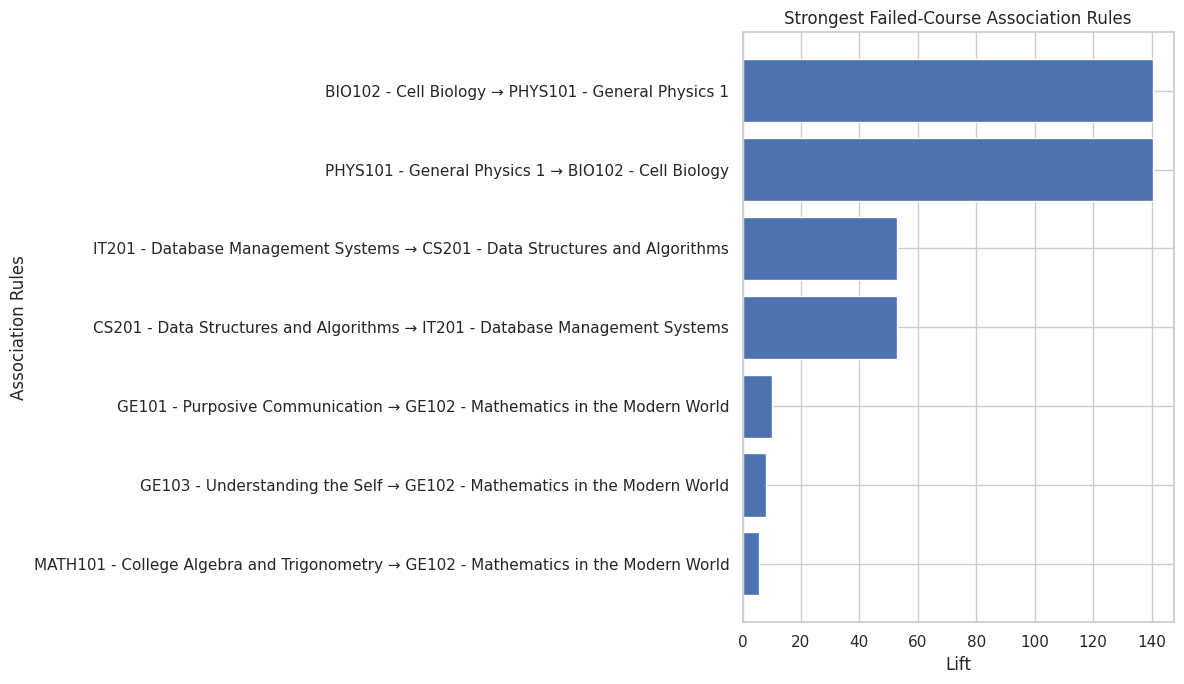

In [73]:
# ============================================================
# SECTION 12: STRONGEST ASSOCIATION RULES
# ============================================================

if not failed_rules.empty:

    top_rules = failed_rules.nlargest(
        10,
        "lift"
    ).copy()

    top_rules["rule_label"] = (
        top_rules["antecedent_names"]
        + " → "
        + top_rules["consequent_names"]
    )

    plt.figure(figsize=(12, 7))

    plt.barh(
        top_rules["rule_label"],
        top_rules["lift"]
    )

    plt.xlabel("Lift")
    plt.ylabel("Association Rules")
    plt.title("Strongest Failed-Course Association Rules")

    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

else:

    print("No association rules available for visualization.")

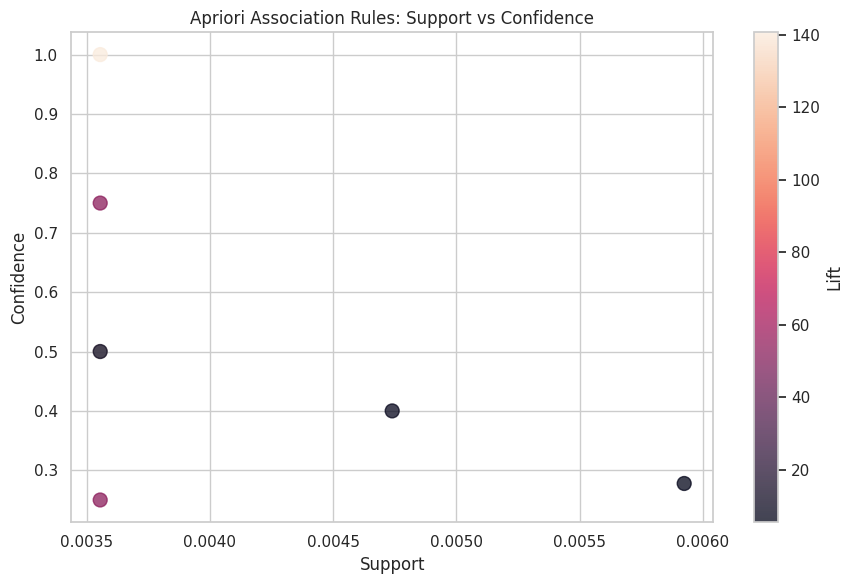

In [74]:
# ============================================================
# SECTION 13: SUPPORT VS CONFIDENCE
# ============================================================

if not failed_rules.empty:

    plt.figure(figsize=(9, 6))

    scatter = plt.scatter(
        failed_rules["support"],
        failed_rules["confidence"],
        c=failed_rules["lift"],
        s=100,
        alpha=0.75
    )

    plt.colorbar(
        scatter,
        label="Lift"
    )

    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title("Apriori Association Rules: Support vs Confidence")

    plt.tight_layout()
    plt.show()

else:

    print("No association rules available for visualization.")

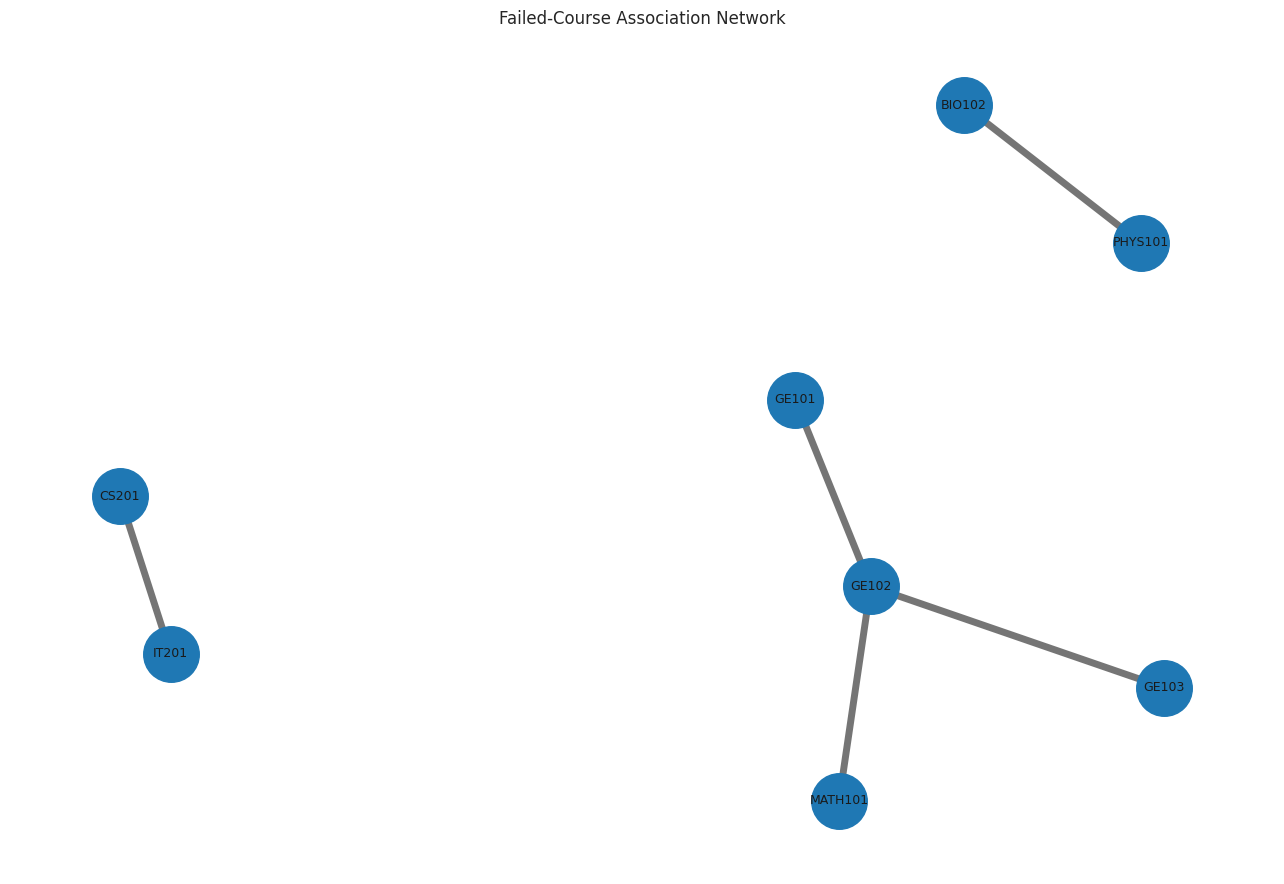

In [75]:
# ============================================================
# SECTION 14: COURSE ASSOCIATION NETWORK
# ============================================================

if not failed_rules.empty:

    network = nx.Graph()

    for _, row in failed_rules.iterrows():

        antecedents = list(row["antecedents"])
        consequents = list(row["consequents"])

        # Draw edges for individual course relationships.
        # Rules involving multiple items are expanded into
        # pairwise links for visualization only.

        for source in antecedents:

            for target in consequents:

                network.add_edge(
                    source,
                    target,
                    lift=float(row["lift"]),
                    support=float(row["support"]),
                    confidence=float(row["confidence"])
                )

    if network.number_of_edges() > 0:

        plt.figure(figsize=(13, 9))

        pos = nx.spring_layout(
            network,
            seed=42,
            k=0.9
        )

        edge_widths = [
            max(
                0.8,
                min(
                    network[u][v]["lift"],
                    5
                )
            )
            for u, v in network.edges()
        ]

        node_labels = {
            node: course_code_map.get(node, node)
            for node in network.nodes()
        }

        nx.draw_networkx_nodes(
            network,
            pos,
            node_size=1600
        )

        nx.draw_networkx_edges(
            network,
            pos,
            width=edge_widths,
            alpha=0.6
        )

        nx.draw_networkx_labels(
            network,
            pos,
            labels=node_labels,
            font_size=9
        )

        plt.title(
            "Failed-Course Association Network"
        )

        plt.axis("off")
        plt.tight_layout()
        plt.show()

    else:

        print("No course associations to display.")

else:

    print("No association network can be generated.")

In [77]:
# ============================================================
# SECTION 16: EXPORT APRIORI RESULTS
# ============================================================

OUTPUT_DIR = "/content/task3_apriori_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 1. FREQUENT ITEMSETS EXPORT
# ------------------------------------------------------------

frequent_export = failed_frequent_itemsets.copy()

if not frequent_export.empty:

    frequent_export["itemsets"] = (
        frequent_export["itemsets"].apply(
            lambda x: json.dumps(sorted(list(x)))
        )
    )

frequent_export.to_csv(
    f"{OUTPUT_DIR}/apriori_frequent_itemsets.csv",
    index=False
)


# ------------------------------------------------------------
# 2. ASSOCIATION RULES EXPORT
# ------------------------------------------------------------

rules_export = failed_rules.copy()

if not rules_export.empty:

    rules_export["antecedents"] = (
        rules_export["antecedents"].apply(
            lambda x: json.dumps(sorted(list(x)))
        )
    )

    rules_export["consequents"] = (
        rules_export["consequents"].apply(
            lambda x: json.dumps(sorted(list(x)))
        )
    )

rules_export.to_csv(
    f"{OUTPUT_DIR}/apriori_association_rules.csv",
    index=False
)


# ------------------------------------------------------------
# 3. REPEATED COURSE RESULTS
# ------------------------------------------------------------

repeat_itemsets_export = repeat_frequent_itemsets.copy()

if not repeat_itemsets_export.empty:

    repeat_itemsets_export["itemsets"] = (
        repeat_itemsets_export["itemsets"].apply(
            lambda x: json.dumps(sorted(list(x)))
        )
    )

repeat_itemsets_export.to_csv(
    f"{OUTPUT_DIR}/apriori_repeat_frequent_itemsets.csv",
    index=False
)


repeat_rules_export = repeat_rules.copy()

if not repeat_rules_export.empty:

    repeat_rules_export["antecedents"] = (
        repeat_rules_export["antecedents"].apply(
            lambda x: json.dumps(sorted(list(x)))
        )
    )

    repeat_rules_export["consequents"] = (
        repeat_rules_export["consequents"].apply(
            lambda x: json.dumps(sorted(list(x)))
        )
    )

repeat_rules_export.to_csv(
    f"{OUTPUT_DIR}/apriori_repeat_association_rules.csv",
    index=False
)


# ------------------------------------------------------------
# 4. SUMMARY JSON
# ------------------------------------------------------------

top_rules_summary = []

if not failed_rules.empty:

    for _, row in failed_rules.head(10).iterrows():

        top_rules_summary.append({

            "antecedent": row["antecedent_names"],

            "consequent": row["consequent_names"],

            "support": float(row["support"]),

            "confidence": float(row["confidence"]),

            "lift": float(row["lift"]),

            "leverage": float(row["leverage"]),

            "conviction": (
                float(row["conviction"])
                if pd.notna(row["conviction"])
                else None
            )
        })


summary = {

    "project": "Course Bottleneck Detection and Academic Progression Analysis",

    "task": "Task 3 - Apriori Association Rule Mining",

    "algorithm": "Apriori",

    "analysis_type": "Unsupervised Association Rule Mining",

    "primary_analysis": "Failed Course Transactions",

    "secondary_analysis": "Repeated Course Transactions",

    "dataset_information": {

        "total_failed_transactions": len(failed_baskets),

        "nonempty_failed_transactions": sum(
            len(x) > 0 for x in failed_baskets
        ),

        "failed_transactions_with_multiple_courses": sum(
            len(x) >= 2 for x in failed_baskets
        ),

        "total_repeated_transactions": len(repeat_baskets),

        "nonempty_repeated_transactions": sum(
            len(x) > 0 for x in repeat_baskets
        ),

        "repeated_transactions_with_multiple_courses": sum(
            len(x) >= 2 for x in repeat_baskets
        )
    },

    "model_parameters": {

        "minimum_support": MIN_SUPPORT,

        "minimum_confidence": MIN_CONFIDENCE,

        "minimum_itemset_length": MIN_ITEMSET_LENGTH,

        "maximum_itemset_length": MAX_ITEMSET_LENGTH
    },

    "results": {

        "failed_frequent_itemsets": len(
            failed_frequent_itemsets
        ),

        "failed_multi_course_itemsets": (
            int(
                (
                    failed_frequent_itemsets["itemsets"]
                    .apply(len) >= 2
                ).sum()
            )
            if not failed_frequent_itemsets.empty else 0
        ),

        "failed_association_rules": len(failed_rules),

        "repeated_frequent_itemsets": len(
            repeat_frequent_itemsets
        ),

        "repeated_association_rules": len(repeat_rules),

        "courses_in_multiple_failed_associations": len(
            course_association_summary
        )
    },

    "top_failed_course_associations": top_rules_summary,

    "threshold_sensitivity_analysis": (
        threshold_analysis.to_dict(orient="records")
    ),

    "methodological_notes": [

        "Apriori is an unsupervised pattern mining technique, not supervised model training.",

        "Transactions are grouped by student and academic semester.",

        "Empty transactions are retained in support calculations.",

        "Failed and repeated course transactions are analyzed separately.",

        "Association does not establish causation.",

        "Low support values require cautious interpretation.",

        "The results are exploratory and depend on the synthetic dataset."
    ]
}


with open(
    f"{OUTPUT_DIR}/apriori_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )


print("=" * 65)
print("APRIORI ANALYSIS EXPORT COMPLETED")
print("=" * 65)

for filename in sorted(os.listdir(OUTPUT_DIR)):

    print("✓", filename)


print("\nSUMMARY")

print("Failed itemsets:", len(failed_frequent_itemsets))
print("Failed rules:", len(failed_rules))
print("Repeated itemsets:", len(repeat_frequent_itemsets))
print("Repeated rules:", len(repeat_rules))


# Download required outputs
from google.colab import files

files.download(
    f"{OUTPUT_DIR}/apriori_frequent_itemsets.csv"
)

files.download(
    f"{OUTPUT_DIR}/apriori_association_rules.csv"
)

files.download(
    f"{OUTPUT_DIR}/apriori_summary.json"
)

APRIORI ANALYSIS EXPORT COMPLETED
✓ apriori_association_rules.csv
✓ apriori_frequent_itemsets.csv
✓ apriori_repeat_association_rules.csv
✓ apriori_repeat_frequent_itemsets.csv
✓ apriori_summary.json

SUMMARY
Failed itemsets: 28
Failed rules: 7
Repeated itemsets: 34
Repeated rules: 11


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [78]:
# ============================================================
# TASK 4: DISCRETE-TIME MARKOV CHAIN
# SECTION 1: INSTALLATION AND IMPORTS
# ============================================================

!pip install -q networkx seaborn

import os
import json
import zipfile
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from IPython.display import display

sns.set_theme(style="whitegrid")

print("Markov Chain libraries successfully imported.")

Markov Chain libraries successfully imported.


In [79]:
# ============================================================
# SECTION 2: LOAD TASK 2 OUTPUTS
# ============================================================

ZIP_PATH = "/content/TASK2_Preprocessed_Outputs.zip"

EXTRACT_DIR = "/content/task2_markov_data"

os.makedirs(EXTRACT_DIR, exist_ok=True)

required_files = [
    "student_state_sequences.csv",
    "markov_transitions_prepared.csv",
    "student_semester_features.csv"
]

# Extract ZIP if available
if os.path.exists(ZIP_PATH):

    with zipfile.ZipFile(ZIP_PATH, "r") as z:

        z.extractall(EXTRACT_DIR)

    print("Task 2 ZIP successfully extracted.")

# Locate files
def locate_file(filename):

    candidates = [
        os.path.join(EXTRACT_DIR, filename),
        os.path.join("/content", filename),
        os.path.join("/content/task2_preprocessed_outputs", filename)
    ]

    for path in candidates:

        if os.path.exists(path):
            return path

    raise FileNotFoundError(
        f"{filename} not found. Upload the Task 2 ZIP or CSV files."
    )


# Load datasets
student_state_sequences = pd.read_csv(
    locate_file("student_state_sequences.csv")
)

markov_transitions = pd.read_csv(
    locate_file("markov_transitions_prepared.csv")
)

student_semester_features = pd.read_csv(
    locate_file("student_semester_features.csv")
)


print("\nDATASET LOADING SUMMARY")
print("=" * 60)

print(
    "Student state sequences:",
    student_state_sequences.shape
)

print(
    "Markov transitions:",
    markov_transitions.shape
)

print(
    "Student semester features:",
    student_semester_features.shape
)


print("\nStudent state sequence preview:")

display(student_state_sequences.head())

print("\nMarkov transition preview:")

display(markov_transitions.head())

print("\nStudent semester feature preview:")

display(student_semester_features.head())

Task 2 ZIP successfully extracted.

DATASET LOADING SUMMARY
Student state sequences: (200, 4)
Markov transitions: (468, 6)
Student semester features: (844, 22)

Student state sequence preview:


,student_id,periods,states,number_of_observations
0,STU0001,"[1, 2, 3, 4]","[""At Risk"", ""On Track"", ""At Risk"", ""On Track""]",4
1,STU0002,"[1, 2, 3, 4]","[""At Risk"", ""At Risk"", ""On Track"", ""On Track""]",4
2,STU0003,"[3, 4]","[""At Risk"", ""On Track""]",2
3,STU0004,"[1, 3]","[""On Track"", ""On Track""]",2
4,STU0005,"[1, 2, 3, 4]","[""On Track"", ""On Track"", ""On Track"", ""At Risk""]",4



Markov transition preview:


,student_id,from_period,to_period,from_state,to_state,transition
0,STU0001,1,2,At Risk,On Track,At Risk -> On Track
1,STU0001,2,3,On Track,At Risk,On Track -> At Risk
2,STU0001,3,4,At Risk,On Track,At Risk -> On Track
3,STU0002,1,2,At Risk,At Risk,At Risk -> At Risk
4,STU0002,2,3,At Risk,On Track,At Risk -> On Track



Student semester feature preview:


,student_id,program_code,period_index,academic_period,expected_year_level,semester_courses_taken,semester_passed,semester_failed,semester_withdrawn,semester_incomplete,cumulative_courses_taken,cumulative_failed_attempts,unresolved_failed_count,unresolved_withdrawn_count,unresolved_incomplete_count,unresolved_course_ids,failed_prerequisite_ids,overdue_prerequisite_ids,blocked_course_ids,repeated_course_ids,repeated_course_count,progression_state
0,STU0001,BSA,1,"1st Semester, AY 2024-2025",1,4,3,0,0,1,4,0,0,0,1,"[""C001""]",[],[],[],[],0,At Risk
1,STU0001,BSA,2,"2nd Semester, AY 2024-2025",1,3,3,0,0,0,6,0,0,0,0,[],[],[],[],"[""C001""]",1,On Track
2,STU0001,BSA,3,"1st Semester, AY 2025-2026",2,3,2,0,0,1,9,0,0,0,1,"[""C030""]",[],[],"[""C031""]",[],0,At Risk
3,STU0001,BSA,4,"2nd Semester, AY 2025-2026",2,1,1,0,0,0,9,0,0,0,0,[],[],[],[],"[""C030""]",1,On Track
4,STU0001,BSA,5,"1st Semester, AY 2026-2027",3,1,1,0,0,0,10,0,0,0,0,[],[],[],[],[],0,On Track


In [80]:
# ============================================================
# SECTION 3: DEFINE STATES AND ACADEMIC PERIODS
# ============================================================

STATES = [
    "On Track",
    "At Risk",
    "Delayed"
]

PERIOD_LABELS = {

    1: "1st Semester, AY 2024-2025",

    2: "2nd Semester, AY 2024-2025",

    3: "1st Semester, AY 2025-2026",

    4: "2nd Semester, AY 2025-2026",

    5: "1st Semester, AY 2026-2027"
}

HISTORICAL_PERIODS = [1, 2, 3, 4]

CURRENT_SNAPSHOT_PERIOD = 5

print("ACADEMIC STATES")
for state in STATES:
    print("-", state)

print("\nHISTORICAL TRAINING PERIODS")
for period in HISTORICAL_PERIODS:
    print(period, "-", PERIOD_LABELS[period])

print(
    "\nCurrent snapshot excluded from historical estimation:",
    PERIOD_LABELS[CURRENT_SNAPSHOT_PERIOD]
)

ACADEMIC STATES
- On Track
- At Risk
- Delayed

HISTORICAL TRAINING PERIODS
1 - 1st Semester, AY 2024-2025
2 - 2nd Semester, AY 2024-2025
3 - 1st Semester, AY 2025-2026
4 - 2nd Semester, AY 2025-2026

Current snapshot excluded from historical estimation: 1st Semester, AY 2026-2027


In [81]:
# ============================================================
# SECTION 4: VALIDATE STUDENT STATE SEQUENCES
# ============================================================

def parse_list(value):

    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    if isinstance(value, str):

        try:
            return json.loads(value)

        except json.JSONDecodeError:
            return ast.literal_eval(value)

    return []


sequence_df = student_state_sequences.copy()

sequence_df["periods"] = (
    sequence_df["periods"].apply(parse_list)
)

sequence_df["states"] = (
    sequence_df["states"].apply(parse_list)
)


# Check matching lengths
sequence_length_valid = (
    sequence_df.apply(
        lambda row: len(row["periods"]) == len(row["states"]),
        axis=1
    )
).all()

# Check valid states
valid_states = sequence_df["states"].apply(
    lambda states: all(state in STATES for state in states)
).all()

# Check unique students
unique_students = sequence_df["student_id"].is_unique

# Count observations
sequence_df["number_of_observations"] = (
    sequence_df["periods"].apply(len)
)

# Check chronological order
chronological_valid = sequence_df["periods"].apply(
    lambda periods: periods == sorted(periods)
).all()

# Check for duplicate periods
duplicate_periods = sequence_df["periods"].apply(
    lambda periods: len(periods) != len(set(periods))
).sum()


# Identify students with missing semester gaps
def count_gaps(periods):

    return sum(
        1
        for a, b in zip(periods, periods[1:])
        if b - a > 1
    )


sequence_df["missing_semester_gaps"] = (
    sequence_df["periods"].apply(count_gaps)
)


# Identify valid consecutive transitions
sequence_df["valid_consecutive_transitions"] = (
    sequence_df["periods"].apply(
        lambda periods: sum(
            1
            for a, b in zip(periods, periods[1:])
            if b - a == 1
        )
    )
)


sequence_validation = pd.DataFrame({

    "check": [
        "Unique student IDs",
        "Matching period and state lengths",
        "Valid academic states",
        "Chronological sequences",
        "No duplicate periods"
    ],

    "status": [
        unique_students,
        sequence_length_valid,
        valid_states,
        chronological_valid,
        duplicate_periods == 0
    ]
})

display(sequence_validation)


print("\nSEQUENCE OBSERVATION SUMMARY")

display(
    sequence_df["number_of_observations"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_observations")
    .to_frame("students")
)


print("\nMISSING SEMESTER GAP SUMMARY")

print(
    "Students with missing semester gaps:",
    int(
        (sequence_df["missing_semester_gaps"] > 0).sum()
    )
)

print(
    "Total missing gaps:",
    int(sequence_df["missing_semester_gaps"].sum())
)

print(
    "Valid consecutive transitions reconstructed:",
    int(sequence_df["valid_consecutive_transitions"].sum())
)


assert sequence_length_valid
assert valid_states
assert unique_students
assert chronological_valid
assert duplicate_periods == 0

print("\nSequence validation completed.")

,check,status
0,Unique student IDs,True
1,Matching period and state lengths,True
2,Valid academic states,True
3,Chronological sequences,True
4,No duplicate periods,True



SEQUENCE OBSERVATION SUMMARY


,students
number_of_observations,
2,42
3,32
4,126



MISSING SEMESTER GAP SUMMARY
Students with missing semester gaps: 16
Total missing gaps: 16
Valid consecutive transitions reconstructed: 468

Sequence validation completed.


In [82]:
# ============================================================
# SECTION 5: VALIDATE PREPARED MARKOV TRANSITIONS
# ============================================================

transitions = markov_transitions.copy()

required_columns = [
    "student_id",
    "from_period",
    "to_period",
    "from_state",
    "to_state"
]

missing_columns = [
    col for col in required_columns
    if col not in transitions.columns
]

assert not missing_columns, (
    f"Missing transition columns: {missing_columns}"
)


# Ensure period columns are integers
transitions["from_period"] = pd.to_numeric(
    transitions["from_period"],
    errors="raise"
).astype(int)

transitions["to_period"] = pd.to_numeric(
    transitions["to_period"],
    errors="raise"
).astype(int)


# Check consecutive periods
consecutive_valid = (
    transitions["to_period"]
    - transitions["from_period"]
) == 1


# Check no current snapshot leakage
historical_only = (
    transitions["from_period"].isin(HISTORICAL_PERIODS[:-1])
    & transitions["to_period"].isin(HISTORICAL_PERIODS)
)


# Check valid states
transition_states_valid = (
    transitions["from_state"].isin(STATES).all()
    and transitions["to_state"].isin(STATES).all()
)


# Reconstruct expected transitions from sequences
expected_transitions = []

for _, row in sequence_df.iterrows():

    periods = row["periods"]
    states = row["states"]

    for i in range(len(periods) - 1):

        from_period = periods[i]
        to_period = periods[i + 1]

        if (
            to_period == from_period + 1
            and from_period in HISTORICAL_PERIODS[:-1]
            and to_period in HISTORICAL_PERIODS
        ):

            expected_transitions.append({

                "student_id": row["student_id"],

                "from_period": from_period,

                "to_period": to_period,

                "from_state": states[i],

                "to_state": states[i + 1]
            })


expected_df = pd.DataFrame(expected_transitions)

comparison_columns = required_columns

prepared_records = (
    transitions[comparison_columns]
    .sort_values(comparison_columns)
    .reset_index(drop=True)
)

expected_records = (
    expected_df[comparison_columns]
    .sort_values(comparison_columns)
    .reset_index(drop=True)
)


transition_records_match = prepared_records.equals(
    expected_records
)


transition_validation = pd.DataFrame({

    "validation": [
        "All transitions are consecutive",
        "No Period 5 training leakage",
        "All states are valid",
        "Prepared transitions match chronological sequences"
    ],

    "status": [
        bool(consecutive_valid.all()),
        bool(historical_only.all()),
        bool(transition_states_valid),
        bool(transition_records_match)
    ]
})


print("TRANSITION VALIDATION")

display(transition_validation)


print(
    "\nPrepared transitions:",
    len(transitions)
)

print(
    "Reconstructed valid transitions:",
    len(expected_df)
)

assert consecutive_valid.all()
assert historical_only.all()
assert transition_states_valid
assert transition_records_match

print("\nAll transition checks passed.")

TRANSITION VALIDATION


,validation,status
0,All transitions are consecutive,True
1,No Period 5 training leakage,True
2,All states are valid,True
3,Prepared transitions match chronological sequences,True



Prepared transitions: 468
Reconstructed valid transitions: 468

All transition checks passed.


In [83]:
# ============================================================
# SECTION 6: TRANSITION COUNT MATRIX
# ============================================================

transition_counts = pd.crosstab(

    transitions["from_state"],

    transitions["to_state"]

)

# Ensure all three states appear
transition_counts = transition_counts.reindex(
    index=STATES,
    columns=STATES,
    fill_value=0
)


print("MARKOV TRANSITION COUNT MATRIX")

display(transition_counts)


print("\nTOTAL TRANSITIONS PER ORIGIN STATE")

display(
    transition_counts.sum(axis=1).rename(
        "total_transitions"
    ).to_frame()
)


print(
    "\nTotal valid transitions:",
    int(transition_counts.values.sum())
)

MARKOV TRANSITION COUNT MATRIX


to_state,On Track,At Risk,Delayed
from_state,,,
On Track,216,56,2
At Risk,91,71,16
Delayed,7,1,8



TOTAL TRANSITIONS PER ORIGIN STATE


,total_transitions
from_state,
On Track,274
At Risk,178
Delayed,16



Total valid transitions: 468


In [84]:
# ============================================================
# SECTION 7: TRANSITION PROBABILITY MATRIX
# ============================================================

row_totals = transition_counts.sum(axis=1)

transition_matrix = transition_counts.div(
    row_totals.replace(0, np.nan),
    axis=0
)


print("TRANSITION PROBABILITY MATRIX")

display(
    transition_matrix.round(4)
)


# Verify probability row sums
row_sums = transition_matrix.sum(axis=1)

row_validation = pd.DataFrame({

    "state": STATES,

    "transition_count": row_totals.values,

    "probability_sum": row_sums.values,

    "valid": np.isclose(
        row_sums.fillna(0).values,
        np.where(row_totals.values > 0, 1, 0)
    )
})


print("\nROW SUM VALIDATION")

display(row_validation)


assert row_validation["valid"].all()

print("\nTransition probability validation completed.")

TRANSITION PROBABILITY MATRIX


to_state,On Track,At Risk,Delayed
from_state,,,
On Track,0.7883,0.2044,0.0073
At Risk,0.5112,0.3989,0.0899
Delayed,0.4375,0.0625,0.5000



ROW SUM VALIDATION


,state,transition_count,probability_sum,valid
0,On Track,274,1.0,True
1,At Risk,178,1.0,True
2,Delayed,16,1.0,True



Transition probability validation completed.


In [85]:
# ============================================================
# SECTION 8: ONE-STEP AND MULTI-STEP PROBABILITIES
# ============================================================

P = transition_matrix.to_numpy(dtype=float)

# Ensure every state has an observed outgoing transition
assert np.isfinite(P).all(), (
    "At least one state has no observed outgoing transitions. "
    "Multi-step probabilities cannot be calculated reliably "
    "for all states without an explicit additional assumption."
)

# One-step probability
P1 = P.copy()

# Two-step probability
P2 = np.linalg.matrix_power(P, 2)

# Three-step probability
P3 = np.linalg.matrix_power(P, 3)


def probability_dataframe(matrix):

    return pd.DataFrame(
        matrix,
        index=STATES,
        columns=STATES
    )


transition_1_step = probability_dataframe(P1)

transition_2_step = probability_dataframe(P2)

transition_3_step = probability_dataframe(P3)


print("ONE-STEP TRANSITION PROBABILITY")

display(transition_1_step.round(4))


print("\nTWO-STEP TRANSITION PROBABILITY")

display(transition_2_step.round(4))


print("\nTHREE-STEP TRANSITION PROBABILITY")

display(transition_3_step.round(4))


# Validate probability sums
for name, matrix in [
    ("P1", P1),
    ("P2", P2),
    ("P3", P3)
]:

    assert np.allclose(
        matrix.sum(axis=1),
        1.0
    )

    print(f"{name}: all probability rows sum to 1.")

ONE-STEP TRANSITION PROBABILITY


,On Track,At Risk,Delayed
On Track,0.7883,0.2044,0.0073
At Risk,0.5112,0.3989,0.0899
Delayed,0.4375,0.0625,0.5000



TWO-STEP TRANSITION PROBABILITY


,On Track,At Risk,Delayed
On Track,0.7291,0.2431,0.0278
At Risk,0.6463,0.2692,0.0845
Delayed,0.5956,0.1456,0.2588



THREE-STEP TRANSITION PROBABILITY


,On Track,At Risk,Delayed
On Track,0.7112,0.2477,0.0411
At Risk,0.6841,0.2447,0.0712
Delayed,0.6572,0.1960,0.1468


P1: all probability rows sum to 1.
P2: all probability rows sum to 1.
P3: all probability rows sum to 1.


In [86]:
# ============================================================
# SECTION 9: HISTORICAL STATE DISTRIBUTION
# ============================================================

semester_features = student_semester_features.copy()

semester_features["period_index"] = pd.to_numeric(
    semester_features["period_index"],
    errors="raise"
).astype(int)


# Exclude current snapshot
historical_features = semester_features[
    semester_features["period_index"].isin(
        HISTORICAL_PERIODS
    )
].copy()


# State distribution per semester
state_distribution_counts = pd.crosstab(

    historical_features["period_index"],

    historical_features["progression_state"]

).reindex(

    index=HISTORICAL_PERIODS,

    columns=STATES,

    fill_value=0
)


state_distribution_percent = (
    state_distribution_counts
    .div(
        state_distribution_counts.sum(axis=1),
        axis=0
    )
)


print("HISTORICAL STUDENT STATE COUNTS")

display(state_distribution_counts)


print("\nHISTORICAL STUDENT STATE PERCENTAGES")

display(
    (state_distribution_percent * 100).round(2)
)


# Initial distribution from Period 4
latest_historical_counts = (
    state_distribution_counts.loc[4]
)

initial_distribution = (
    latest_historical_counts
    / latest_historical_counts.sum()
).to_numpy(dtype=float)


initial_distribution_df = pd.DataFrame({

    "academic_state": STATES,

    "student_count": latest_historical_counts.values,

    "initial_probability": initial_distribution,

    "initial_percentage": initial_distribution * 100
})


print("\nINITIAL STATE DISTRIBUTION: PERIOD 4")

display(initial_distribution_df.round(4))

HISTORICAL STUDENT STATE COUNTS


progression_state,On Track,At Risk,Delayed
period_index,,,
1,102,69,0
2,99,56,0
3,131,53,16
4,113,35,10



HISTORICAL STUDENT STATE PERCENTAGES


progression_state,On Track,At Risk,Delayed
period_index,,,
1,59.65,40.35,0.00
2,63.87,36.13,0.00
3,65.50,26.50,8.00
4,71.52,22.15,6.33



INITIAL STATE DISTRIBUTION: PERIOD 4


,academic_state,student_count,initial_probability,initial_percentage
0,On Track,113,0.7152,71.5190
1,At Risk,35,0.2215,22.1519
2,Delayed,10,0.0633,6.3291


In [87]:
# ============================================================
# SECTION 10: FUTURE PROGRESSION DISTRIBUTIONS
# ============================================================

# Initial distribution from Period 4
current_distribution = initial_distribution.copy()

prediction_records = []

# Include the baseline Period 4
for step in range(0, 4):

    if step == 0:

        forecast = current_distribution.copy()

    else:

        forecast = current_distribution @ np.linalg.matrix_power(
            P,
            step
        )

    forecast = forecast / forecast.sum()

    for i, state in enumerate(STATES):

        prediction_records.append({

            "forecast_step": step,

            "academic_state": state,

            "probability": float(forecast[i]),

            "percentage": float(forecast[i] * 100),

            "estimated_students": float(
                forecast[i] * latest_historical_counts.sum()
            )
        })


markov_predictions = pd.DataFrame(
    prediction_records
)


print("MULTI-SEMESTER PROGRESSION PREDICTIONS")

display(
    markov_predictions.pivot(
        index="forecast_step",
        columns="academic_state",
        values="percentage"
    ).round(2)
)


print("\nDETAILED PROGRESSION PREDICTIONS")

display(markov_predictions.round(4))


# Validate projected distributions
forecast_sums = (
    markov_predictions.groupby("forecast_step")["probability"]
    .sum()
)

assert np.allclose(
    forecast_sums.values,
    1.0
)

print("\nAll forecast distributions sum to 1.")

MULTI-SEMESTER PROGRESSION PREDICTIONS


academic_state,At Risk,Delayed,On Track
forecast_step,,,
0,22.15,6.33,71.52
1,23.85,5.68,70.47
2,24.27,5.50,70.23
3,24.38,5.44,70.18



DETAILED PROGRESSION PREDICTIONS


,forecast_step,academic_state,probability,percentage,estimated_students
0,0,On Track,0.7152,71.5190,113.0000
1,0,At Risk,0.2215,22.1519,35.0000
2,0,Delayed,0.0633,6.3291,10.0000
3,1,On Track,0.7047,70.4738,111.3486
4,1,At Risk,0.2385,23.8485,37.6806
5,1,Delayed,0.0568,5.6778,8.9709
6,2,On Track,0.7023,70.2322,110.9668
7,2,At Risk,0.2427,24.2708,38.3479
8,2,Delayed,0.0550,5.4970,8.6852
9,3,On Track,0.7018,70.1786,110.8821



All forecast distributions sum to 1.


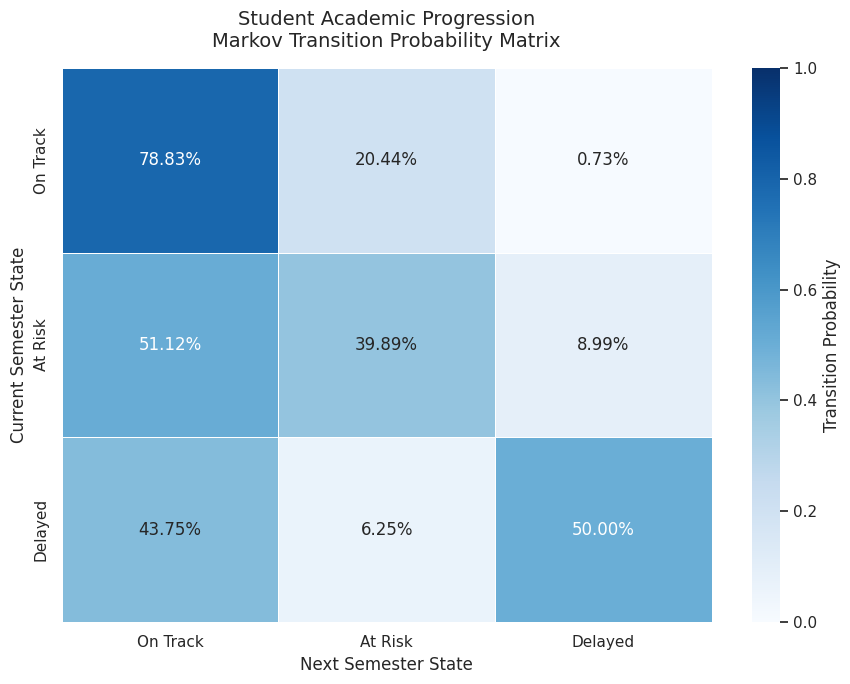

In [88]:
# ============================================================
# SECTION 11: TRANSITION PROBABILITY HEATMAP
# ============================================================

plt.figure(figsize=(9, 7))

sns.heatmap(

    transition_matrix,

    annot=True,

    fmt=".2%",

    cmap="Blues",

    linewidths=0.5,

    vmin=0,

    vmax=1,

    cbar_kws={
        "label": "Transition Probability"
    }

)

plt.title(
    "Student Academic Progression\nMarkov Transition Probability Matrix",
    fontsize=14,
    pad=15
)

plt.xlabel("Next Semester State")

plt.ylabel("Current Semester State")

plt.tight_layout()

plt.show()

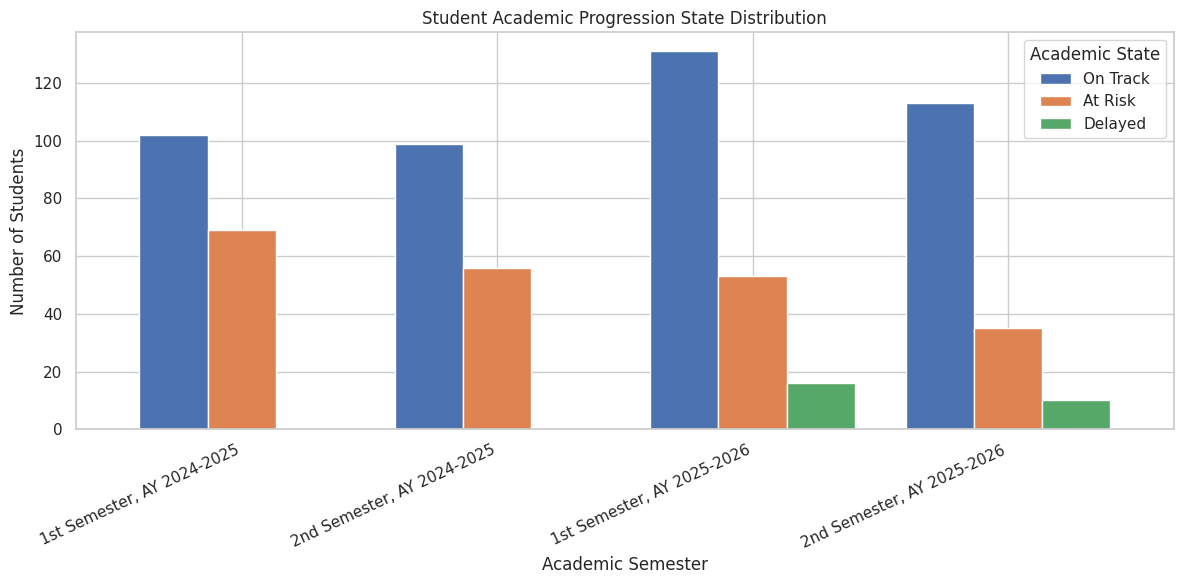

In [89]:
# ============================================================
# SECTION 12: HISTORICAL STATE DISTRIBUTION
# ============================================================

distribution_plot = state_distribution_counts.copy()

distribution_plot.index = [
    PERIOD_LABELS[i]
    for i in distribution_plot.index
]

distribution_plot.plot(

    kind="bar",

    figsize=(12, 6),

    width=0.8

)

plt.title(
    "Student Academic Progression State Distribution"
)

plt.xlabel("Academic Semester")

plt.ylabel("Number of Students")

plt.xticks(rotation=25, ha="right")

plt.legend(
    title="Academic State"
)

plt.tight_layout()

plt.show()

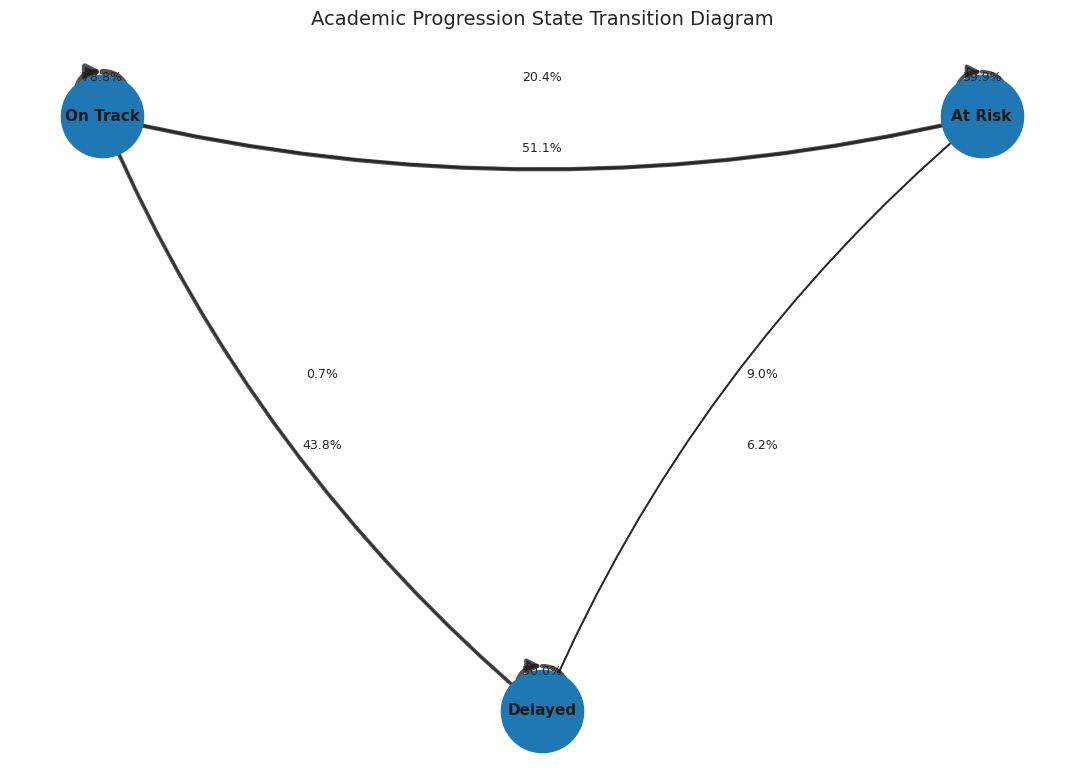

In [90]:
# ============================================================
# SECTION 13: MARKOV STATE TRANSITION DIAGRAM
# ============================================================

G_markov = nx.DiGraph()

for state in STATES:

    G_markov.add_node(state)


for i, from_state in enumerate(STATES):

    for j, to_state in enumerate(STATES):

        probability = P[i, j]

        G_markov.add_edge(

            from_state,

            to_state,

            weight=probability

        )


plt.figure(figsize=(11, 8))

positions = {

    "On Track": (0, 1),

    "At Risk": (2, 1),

    "Delayed": (1, -1)

}


nx.draw_networkx_nodes(

    G_markov,

    positions,

    node_size=3500

)


nx.draw_networkx_labels(

    G_markov,

    positions,

    font_size=11,

    font_weight="bold"

)


# Curved edges help distinguish opposite directions
for i, from_state in enumerate(STATES):

    for j, to_state in enumerate(STATES):

        probability = P[i, j]

        if probability <= 0:
            continue

        if from_state == to_state:

            connection = "arc3,rad=0.35"

        elif i < j:

            connection = "arc3,rad=0.12"

        else:

            connection = "arc3,rad=-0.12"

        nx.draw_networkx_edges(

            G_markov,

            positions,

            edgelist=[(from_state, to_state)],

            width=1 + probability * 4,

            arrows=True,

            arrowsize=20,

            connectionstyle=connection,

            alpha=0.75

        )

        midpoint = (

            (positions[from_state][0] + positions[to_state][0]) / 2,

            (positions[from_state][1] + positions[to_state][1]) / 2
        )

        plt.text(

            midpoint[0],

            midpoint[1] + (0.12 if i <= j else -0.12),

            f"{probability:.1%}",

            fontsize=9,

            ha="center"

        )


plt.title(
    "Academic Progression State Transition Diagram",
    fontsize=14
)

plt.axis("off")

plt.tight_layout()

plt.show()

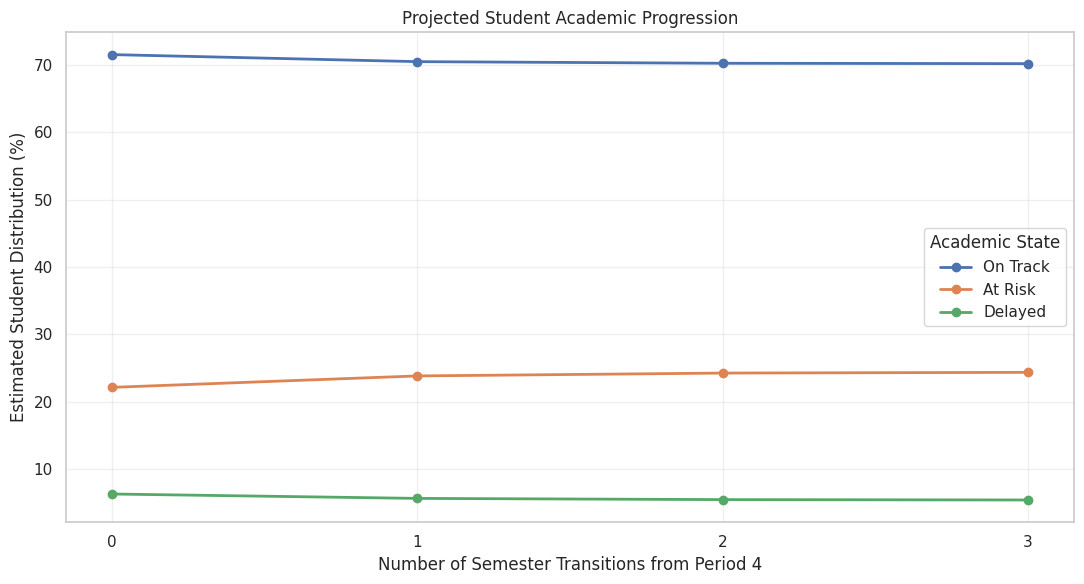

In [91]:
# ============================================================
# SECTION 14: MULTI-SEMESTER PROGRESSION CHART
# ============================================================

forecast_plot = markov_predictions.pivot(

    index="forecast_step",

    columns="academic_state",

    values="percentage"

)

forecast_plot = forecast_plot.reindex(
    columns=STATES
)


plt.figure(figsize=(11, 6))

for state in STATES:

    plt.plot(

        forecast_plot.index,

        forecast_plot[state],

        marker="o",

        linewidth=2,

        label=state

    )


plt.title(
    "Projected Student Academic Progression"
)

plt.xlabel(
    "Number of Semester Transitions from Period 4"
)

plt.ylabel(
    "Estimated Student Distribution (%)"
)

plt.xticks([0, 1, 2, 3])

plt.legend(title="Academic State")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [92]:
# ============================================================
# SECTION 15: EXPORT MARKOV CHAIN RESULTS
# ============================================================

OUTPUT_DIR = "/content/task4_markov_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 1. TRANSITION PROBABILITY MATRIX
# ------------------------------------------------------------

transition_matrix.to_csv(
    f"{OUTPUT_DIR}/markov_transition_matrix.csv",
    index=True
)


# ------------------------------------------------------------
# 2. TRANSITION COUNT MATRIX
# ------------------------------------------------------------

transition_counts.to_csv(
    f"{OUTPUT_DIR}/markov_transition_counts.csv",
    index=True
)


# ------------------------------------------------------------
# 3. PROGRESSION PREDICTIONS
# ------------------------------------------------------------

markov_predictions.to_csv(
    f"{OUTPUT_DIR}/markov_progression_predictions.csv",
    index=False
)


# ------------------------------------------------------------
# 4. MARKOV SUMMARY JSON
# ------------------------------------------------------------

state_distribution_summary = {}

for period in HISTORICAL_PERIODS:

    state_distribution_summary[
        PERIOD_LABELS[period]
    ] = {

        state: int(
            state_distribution_counts.loc[period, state]
        )

        for state in STATES
    }


transition_count_summary = {

    from_state: {

        to_state: int(
            transition_counts.loc[from_state, to_state]
        )

        for to_state in STATES
    }

    for from_state in STATES
}


transition_probability_summary = {

    from_state: {

        to_state: float(
            transition_matrix.loc[from_state, to_state]
        )

        for to_state in STATES
    }

    for from_state in STATES
}


summary = {

    "project": (
        "Course Bottleneck Detection and "
        "Academic Progression Analysis"
    ),

    "task": "Task 4 - Discrete-Time Markov Chain",

    "algorithm": "Discrete-Time Markov Chain",

    "analysis_type": "Unsupervised Probabilistic State Transition Analysis",

    "academic_states": STATES,

    "historical_periods": {

        str(period): PERIOD_LABELS[period]

        for period in HISTORICAL_PERIODS
    },

    "excluded_current_snapshot": {

        "period": CURRENT_SNAPSHOT_PERIOD,

        "academic_period": PERIOD_LABELS[
            CURRENT_SNAPSHOT_PERIOD
        ],

        "reason": (
            "Excluded from historical transition estimation "
            "to prevent future-data leakage."
        )
    },

    "dataset_information": {

        "total_students": int(
            sequence_df["student_id"].nunique()
        ),

        "total_student_semester_observations": int(
            historical_features.shape[0]
        ),

        "total_valid_transitions": int(
            len(transitions)
        ),

        "students_with_2_observations": int(
            (sequence_df["number_of_observations"] == 2).sum()
        ),

        "students_with_3_observations": int(
            (sequence_df["number_of_observations"] == 3).sum()
        ),

        "students_with_4_observations": int(
            (sequence_df["number_of_observations"] == 4).sum()
        ),

        "students_with_missing_semester_gaps": int(
            (sequence_df["missing_semester_gaps"] > 0).sum()
        ),

        "total_missing_semester_gaps": int(
            sequence_df["missing_semester_gaps"].sum()
        )
    },

    "transition_counts": transition_count_summary,

    "transition_probabilities": transition_probability_summary,

    "historical_state_distribution": (
        state_distribution_summary
    ),

    "initial_distribution": {

        state: float(initial_distribution[i])

        for i, state in enumerate(STATES)
    },

    "multi_step_probabilities": {

        "one_step": P1.tolist(),

        "two_step": P2.tolist(),

        "three_step": P3.tolist()
    },

    "forecast_steps": (
        markov_predictions.to_dict(orient="records")
    ),

    "validation": {

        "sequence_lengths_match": bool(
            sequence_length_valid
        ),

        "valid_academic_states": bool(
            valid_states
        ),

        "unique_student_ids": bool(
            unique_students
        ),

        "chronological_sequences": bool(
            chronological_valid
        ),

        "no_duplicate_periods": bool(
            duplicate_periods == 0
        ),

        "consecutive_transitions_only": bool(
            consecutive_valid.all()
        ),

        "current_snapshot_excluded": bool(
            historical_only.all()
        ),

        "prepared_transitions_match_sequences": bool(
            transition_records_match
        ),

        "probability_rows_sum_to_one": bool(
            row_validation["valid"].all()
        ),

        "multi_step_rows_sum_to_one": bool(
            np.allclose(P2.sum(axis=1), 1)
            and np.allclose(P3.sum(axis=1), 1)
        )
    },

    "assumptions_and_limitations": [

        "The next academic state depends on the current state under the first-order Markov assumption.",

        "Each transition represents consecutive observed academic semesters.",

        "Missing semester observations are not treated as transitions.",

        "Historical transition probabilities are estimated using observed transition frequencies.",

        "Period 5 is excluded from historical transition estimation.",

        "Transition probabilities describe aggregate patterns, not guaranteed individual outcomes.",

        "The Delayed state has fewer observations and therefore less reliable probability estimates.",

        "The model assumes historical transition patterns are sufficiently representative of future progression.",

        "The synthetic dataset limits generalization to actual university populations."
    ]
}


with open(
    f"{OUTPUT_DIR}/markov_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )


print("=" * 65)
print("TASK 4: MARKOV CHAIN EXPORT COMPLETED")
print("=" * 65)


for filename in sorted(os.listdir(OUTPUT_DIR)):

    print("✓", filename)


print("\nEXPORTED FILES:")

print("1. markov_transition_matrix.csv")

print("2. markov_transition_counts.csv")

print("3. markov_progression_predictions.csv")

print("4. markov_summary.json")


# Download outputs
from google.colab import files

for filename in [
    "markov_transition_matrix.csv",
    "markov_transition_counts.csv",
    "markov_progression_predictions.csv",
    "markov_summary.json"
]:

    files.download(
        f"{OUTPUT_DIR}/{filename}"
    )

TASK 4: MARKOV CHAIN EXPORT COMPLETED
✓ markov_progression_predictions.csv
✓ markov_summary.json
✓ markov_transition_counts.csv
✓ markov_transition_matrix.csv

EXPORTED FILES:
1. markov_transition_matrix.csv
2. markov_transition_counts.csv
3. markov_progression_predictions.csv
4. markov_summary.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [93]:
# ============================================================
# TASK 5: MODEL VALIDATION AND EVALUATION
# SECTION 1: LIBRARIES
# ============================================================

!pip install -q mlxtend seaborn scikit-learn

import os
import json
import ast
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score
)

from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Task 5 libraries successfully imported.")

Task 5 libraries successfully imported.


In [95]:
# ============================================================
# SECTION 2: LOAD ORIGINAL DATASETS AND MODEL OUTPUTS
# ============================================================

from google.colab import files

# Upload files only if they are not already available.
required_paths = {
    "student_course_history": "/content/student_course_history.csv",
    "prerequisite_mapping": "/content/prerequisite_mapping.csv",
    "course_master": "/content/course_master.csv",
    "apriori_itemsets": "/content/apriori_frequent_itemsets.csv",
    "apriori_rules": "/content/apriori_association_rules.csv",
    "markov_counts": "/content/markov_transition_counts.csv",
    "markov_matrix": "/content/markov_transition_matrix.csv",
    "markov_predictions": "/content/markov_progression_predictions.csv",
    "markov_transitions": "/content/markov_transitions_prepared.csv",
    "student_features": "/content/student_semester_features.csv"
}

missing = [
    path for path in required_paths.values()
    if not os.path.exists(path)
]

if missing:
    print("Upload the missing CSV files:")
    uploaded = files.upload()

    print("\nUploaded:", list(uploaded.keys()))


# Find files even when Colab places them in a subfolder.
def find_csv(filename):

    for root, dirs, filenames in os.walk("/content"):

        if filename in filenames:

            return os.path.join(root, filename)

    raise FileNotFoundError(
        f"{filename} was not found. Please upload it."
    )


# Load data
student_history = pd.read_csv(
    find_csv("student_course_history.csv")
)

prerequisites = pd.read_csv(
    find_csv("prerequisite_mapping.csv")
)

course_master = pd.read_csv(
    find_csv("course_master.csv")
)

apriori_itemsets = pd.read_csv(
    find_csv("apriori_frequent_itemsets.csv")
)

apriori_rules = pd.read_csv(
    find_csv("apriori_association_rules.csv")
)

markov_counts_export = pd.read_csv(
    find_csv("markov_transition_counts.csv"),
    index_col=0
)

markov_matrix_export = pd.read_csv(
    find_csv("markov_transition_matrix.csv"),
    index_col=0
)

markov_predictions_export = pd.read_csv(
    find_csv("markov_progression_predictions.csv")
)

markov_transitions = pd.read_csv(
    find_csv("markov_transitions_prepared.csv")
)

student_features = pd.read_csv(
    find_csv("student_semester_features.csv")
)


print("=" * 60)
print("DATASET LOADING SUMMARY")
print("=" * 60)

datasets = {
    "Student Course History": student_history,
    "Prerequisite Mapping": prerequisites,
    "Course Master": course_master,
    "Apriori Frequent Itemsets": apriori_itemsets,
    "Apriori Association Rules": apriori_rules,
    "Markov Transition Counts": markov_counts_export,
    "Markov Transition Matrix": markov_matrix_export,
    "Markov Predictions": markov_predictions_export,
    "Markov Prepared Transitions": markov_transitions,
    "Student Semester Features": student_features
}

for name, df in datasets.items():

    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

print("\nOriginal student-course history preview:")
display(student_history.head())

Upload the missing CSV files:


Saving apriori_association_rules.csv to apriori_association_rules.csv
Saving apriori_frequent_itemsets.csv to apriori_frequent_itemsets.csv
Saving apriori_summary.json to apriori_summary.json
Saving course_master.csv to course_master (1).csv
Saving course_performance.csv to course_performance (1).csv
Saving historical_course_records.csv to historical_course_records (1).csv
Saving markov_progression_predictions.csv to markov_progression_predictions.csv
Saving markov_summary.json to markov_summary.json
Saving markov_transition_counts.csv to markov_transition_counts.csv
Saving markov_transition_matrix.csv to markov_transition_matrix.csv
Saving prerequisite_mapping.csv to prerequisite_mapping (1).csv
Saving student_course_history.csv to student_course_history (1).csv
Saving student_progression.csv to student_progression (1).csv

Uploaded: ['apriori_association_rules.csv', 'apriori_frequent_itemsets.csv', 'apriori_summary.json', 'course_master (1).csv', 'course_performance (1).csv', 'histor

,history_id,student_id,course_id,semester,academic_year,final_grade,course_result,attempt_number,is_repeat
0,SCH00001,STU0001,C001,1st Semester,2024-2025,NaN,Incomplete,1,False
1,SCH00002,STU0001,C002,1st Semester,2024-2025,1.50,Passed,1,False
2,SCH00003,STU0001,C006,1st Semester,2024-2025,1.75,Passed,1,False
3,SCH00004,STU0001,C029,1st Semester,2024-2025,1.25,Passed,1,False
4,SCH00005,STU0001,C001,2nd Semester,2024-2025,2.50,Passed,2,True


In [96]:
# ============================================================
# SECTION 3: RECONSTRUCT APRIORI TRANSACTIONS
# ============================================================

history = student_history.copy()

# Standardize course results
history["course_result"] = (
    history["course_result"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Standardize identifiers
history["student_id"] = history["student_id"].astype(str).str.strip()
history["course_id"] = history["course_id"].astype(str).str.strip()

# Standardize academic period labels
history["semester"] = (
    history["semester"].astype(str).str.strip()
)

history["academic_year"] = (
    history["academic_year"].astype(str).str.strip()
)


# Map common result labels
result_mapping = {
    "fail": "failed",
    "failure": "failed",
    "failed": "failed",
    "pass": "passed",
    "passed": "passed",
    "withdraw": "withdrawn",
    "withdrawn": "withdrawn",
    "w": "withdrawn",
    "incomplete": "incomplete",
    "inc": "incomplete"
}

history["course_result"] = (
    history["course_result"].replace(result_mapping)
)


# Create semester key
history["semester_key"] = (
    history["student_id"]
    + "|"
    + history["semester"]
    + "|"
    + history["academic_year"]
)


# Failed course transactions
failed_records = history[
    history["course_result"] == "failed"
].copy()


failed_transactions = (
    failed_records.groupby("semester_key")["course_id"]
    .apply(lambda x: set(x))
    .to_dict()
)


# Retain all student-semester transactions,
# including transactions with no failed courses.
all_transactions = (
    history.groupby("semester_key")["course_id"]
    .apply(lambda x: set(x))
)

failed_baskets = [
    failed_transactions.get(key, set())
    for key in all_transactions.index
]


# Repeated-course transactions, using repeat flags
history["is_repeat"] = (
    history["is_repeat"]
    .astype(str)
    .str.lower()
    .isin(["true", "1", "yes"])
)

repeat_transactions = (
    history[history["is_repeat"]]
    .groupby("semester_key")["course_id"]
    .apply(lambda x: set(x))
)

repeat_baskets = [
    repeat_transactions.get(key, set())
    for key in all_transactions.index
]


print("APRIORI TRANSACTION SUMMARY")
print("=" * 60)

print("Total student-semester transactions:", len(failed_baskets))

print(
    "Transactions with failed courses:",
    sum(len(x) > 0 for x in failed_baskets)
)

print(
    "Transactions with multiple failed courses:",
    sum(len(x) >= 2 for x in failed_baskets)
)

print(
    "Transactions with repeated courses:",
    sum(len(x) > 0 for x in repeat_baskets)
)

print("\nSample failed-course transactions:")

for transaction in failed_baskets[:5]:
    print(transaction)

APRIORI TRANSACTION SUMMARY
Total student-semester transactions: 844
Transactions with failed courses: 193
Transactions with multiple failed courses: 37
Transactions with repeated courses: 239

Sample failed-course transactions:
set()
set()
set()
set()
set()


In [97]:
# ============================================================
# SECTION 4: VALIDATE FREQUENT ITEMSET SUPPORT
# ============================================================

def parse_itemset(value):

    if isinstance(value, (set, list, tuple)):
        return frozenset(str(x).strip() for x in value)

    if pd.isna(value):
        return frozenset()

    value = str(value).strip()

    try:
        parsed = json.loads(value)
    except Exception:
        parsed = ast.literal_eval(value)

    return frozenset(str(x).strip() for x in parsed)


itemsets = apriori_itemsets.copy()

itemsets["parsed_itemset"] = (
    itemsets["itemsets"].apply(parse_itemset)
)


def calculate_support(itemset, transactions):

    if not transactions:
        return np.nan

    count = sum(
        itemset.issubset(transaction)
        for transaction in transactions
    )

    return count / len(transactions)


itemset_validation = []

for _, row in itemsets.iterrows():

    itemset = row["parsed_itemset"]

    calculated_support = calculate_support(
        itemset,
        failed_baskets
    )

    exported_support = float(row["support"])

    itemset_validation.append({

        "itemset": list(itemset),

        "itemset_size": len(itemset),

        "exported_support": exported_support,

        "recalculated_support": calculated_support,

        "support_difference": abs(
            exported_support - calculated_support
        ),

        "valid": np.isclose(
            exported_support,
            calculated_support,
            atol=1e-6
        )
    })


itemset_validation_df = pd.DataFrame(
    itemset_validation
)


print("FREQUENT ITEMSET SUPPORT VALIDATION")

display(itemset_validation_df.head(20))


print("\nValidation results:")

print(
    "Valid itemsets:",
    int(itemset_validation_df["valid"].sum())
)

print(
    "Invalid itemsets:",
    int((~itemset_validation_df["valid"]).sum())
)


if not itemset_validation_df.empty:

    assert itemset_validation_df["valid"].all(), (
        "Some support values do not match the original records. "
        "Check the transaction definition and denominator."
    )

FREQUENT ITEMSET SUPPORT VALIDATION


,itemset,itemset_size,exported_support,recalculated_support,support_difference,valid
0,"[C002, C006]",2,0.005924,0.005924,4.336809e-17,True
1,"[C002, C003]",2,0.004739,0.004739,9.540979e-17,True
2,"[C002, C001]",2,0.003555,0.003555,4.640385e-17,True
3,"[C042, C009]",2,0.003555,0.003555,4.640385e-17,True
4,"[C025, C022]",2,0.003555,0.003555,4.640385e-17,True
5,[C002],1,0.049763,0.049763,4.857226e-17,True
6,[C010],1,0.042654,0.042654,6.245005e-17,True
7,[C006],1,0.021327,0.021327,7.979728e-17,True
8,[C007],1,0.020142,0.020142,3.122502e-17,True
9,[C005],1,0.015403,0.015403,3.469447e-17,True



Validation results:
Valid itemsets: 28
Invalid itemsets: 0


In [98]:
# ============================================================
# SECTION 5: VALIDATE ASSOCIATION RULE METRICS
# ============================================================

rules = apriori_rules.copy()


rules["parsed_antecedents"] = (
    rules["antecedents"].apply(parse_itemset)
)

rules["parsed_consequents"] = (
    rules["consequents"].apply(parse_itemset)
)


rule_validation = []

for _, row in rules.iterrows():

    antecedents = row["parsed_antecedents"]

    consequents = row["parsed_consequents"]

    union = antecedents.union(consequents)

    support_union = calculate_support(
        union,
        failed_baskets
    )

    support_antecedent = calculate_support(
        antecedents,
        failed_baskets
    )

    support_consequent = calculate_support(
        consequents,
        failed_baskets
    )

    confidence = (
        support_union / support_antecedent
        if support_antecedent > 0 else np.nan
    )

    lift = (
        confidence / support_consequent
        if support_consequent > 0 else np.nan
    )

    rule_validation.append({

        "antecedents": list(antecedents),

        "consequents": list(consequents),

        "exported_support": row["support"],

        "recalculated_support": support_union,

        "exported_confidence": row["confidence"],

        "recalculated_confidence": confidence,

        "exported_lift": row["lift"],

        "recalculated_lift": lift,

        "support_valid": np.isclose(
            row["support"],
            support_union,
            atol=1e-6
        ),

        "confidence_valid": np.isclose(
            row["confidence"],
            confidence,
            atol=1e-6
        ),

        "lift_valid": np.isclose(
            row["lift"],
            lift,
            atol=1e-6
        )
    })


rule_validation_df = pd.DataFrame(
    rule_validation
)


if not rule_validation_df.empty:

    rule_validation_df["all_metrics_valid"] = (
        rule_validation_df[
            ["support_valid", "confidence_valid", "lift_valid"]
        ].all(axis=1)
    )


print("ASSOCIATION RULE VALIDATION")

display(rule_validation_df.head(20))


print("\nVALIDATION SUMMARY")

if not rule_validation_df.empty:

    print(
        "Valid rules:",
        int(rule_validation_df["all_metrics_valid"].sum())
    )

    print(
        "Invalid rules:",
        int((~rule_validation_df["all_metrics_valid"]).sum())
    )

    print(
        "Support validation:",
        rule_validation_df["support_valid"].all()
    )

    print(
        "Confidence validation:",
        rule_validation_df["confidence_valid"].all()
    )

    print(
        "Lift validation:",
        rule_validation_df["lift_valid"].all()
    )

ASSOCIATION RULE VALIDATION


,antecedents,consequents,exported_support,recalculated_support,exported_confidence,recalculated_confidence,exported_lift,recalculated_lift,support_valid,confidence_valid,lift_valid,all_metrics_valid
0,[C042],[C009],0.003555,0.003555,1.000000,1.000000,140.666667,140.666667,True,True,True,True
1,[C009],[C042],0.003555,0.003555,0.500000,0.500000,140.666667,140.666667,True,True,True,True
2,[C025],[C022],0.003555,0.003555,0.750000,0.750000,52.750000,52.750000,True,True,True,True
3,[C022],[C025],0.003555,0.003555,0.250000,0.250000,52.750000,52.750000,True,True,True,True
4,[C001],[C002],0.003555,0.003555,0.500000,0.500000,10.047619,10.047619,True,True,True,True
5,[C003],[C002],0.004739,0.004739,0.400000,0.400000,8.038095,8.038095,True,True,True,True
6,[C006],[C002],0.005924,0.005924,0.277778,0.277778,5.582011,5.582011,True,True,True,True



VALIDATION SUMMARY
Valid rules: 7
Invalid rules: 0
Support validation: True
Confidence validation: True
Lift validation: True


In [99]:
# ============================================================
# SECTION 6: RULE QUALITY AND REDUNDANCY ANALYSIS
# ============================================================

if not rule_validation_df.empty:

    quality = rule_validation_df.copy()

    quality["quality_category"] = np.select(

        [
            quality["recalculated_lift"] <= 1,

            quality["recalculated_support"] < 0.05,

            (
                (quality["recalculated_lift"] > 1)
                & (quality["recalculated_confidence"] >= 0.60)
            ),

            (
                (quality["recalculated_lift"] > 1)
                & (quality["recalculated_confidence"] >= 0.40)
            )
        ],

        [
            "Weak / No Positive Association",

            "Low Support",

            "Strong Positive Association",

            "Moderate Positive Association"
        ],

        default="Needs Further Review"
    )


    # Identify potential redundancy:
    # Same consequent, but another rule has a smaller antecedent.
    quality["potentially_redundant"] = False

    for i, rule in quality.iterrows():

        A = frozenset(rule["antecedents"])
        B = frozenset(rule["consequents"])

        for j, other in quality.iterrows():

            if i == j:
                continue

            other_A = frozenset(other["antecedents"])
            other_B = frozenset(other["consequents"])

            if (
                other_B == B
                and other_A < A
                and other["recalculated_confidence"]
                    >= rule["recalculated_confidence"]
            ):

                quality.loc[i, "potentially_redundant"] = True
                break


    print("RULE QUALITY CLASSIFICATION")

    display(
        quality[
            [
                "antecedents",
                "consequents",
                "recalculated_support",
                "recalculated_confidence",
                "recalculated_lift",
                "quality_category",
                "potentially_redundant"
            ]
        ].sort_values(
            "recalculated_lift",
            ascending=False
        ).head(30)
    )


    print("\nRULE QUALITY COUNTS")

    display(
        quality["quality_category"]
        .value_counts()
        .rename_axis("quality_category")
        .to_frame("number_of_rules")
    )


    print(
        "\nPotentially redundant rules:",
        int(quality["potentially_redundant"].sum())
    )

else:

    quality = pd.DataFrame()
    print("No association rules available for quality assessment.")

RULE QUALITY CLASSIFICATION


,antecedents,consequents,recalculated_support,recalculated_confidence,recalculated_lift,quality_category,potentially_redundant
0,[C042],[C009],0.003555,1.000000,140.666667,Low Support,False
1,[C009],[C042],0.003555,0.500000,140.666667,Low Support,False
2,[C025],[C022],0.003555,0.750000,52.750000,Low Support,False
3,[C022],[C025],0.003555,0.250000,52.750000,Low Support,False
4,[C001],[C002],0.003555,0.500000,10.047619,Low Support,False
5,[C003],[C002],0.004739,0.400000,8.038095,Low Support,False
6,[C006],[C002],0.005924,0.277778,5.582011,Low Support,False



RULE QUALITY COUNTS


,number_of_rules
quality_category,
Low Support,7



Potentially redundant rules: 0


In [100]:
# ============================================================
# SECTION 7: PREREQUISITE CONSISTENCY CHECK
# ============================================================

course_lookup = dict(
    zip(
        course_master["course_id"].astype(str),
        course_master["course_code"].astype(str)
    )
)


prereq_pairs = set(

    zip(
        prerequisites["prerequisite_course_id"].astype(str),
        prerequisites["succeeding_course_id"].astype(str)
    )
)


def is_prerequisite_related(antecedents, consequents):

    related_pairs = []

    for a in antecedents:

        for b in consequents:

            if (a, b) in prereq_pairs:

                related_pairs.append((a, b))

            elif (b, a) in prereq_pairs:

                related_pairs.append((b, a))

    return related_pairs


if not quality.empty:

    quality["prerequisite_related_pairs"] = quality.apply(

        lambda row: is_prerequisite_related(
            row["antecedents"],
            row["consequents"]
        ),

        axis=1
    )

    quality["has_prerequisite_relationship"] = (
        quality["prerequisite_related_pairs"].apply(
            lambda x: len(x) > 0
        )
    )


    print("PREREQUISITE ASSOCIATION CHECK")

    display(
        quality[
            [
                "antecedents",
                "consequents",
                "recalculated_support",
                "recalculated_confidence",
                "recalculated_lift",
                "has_prerequisite_relationship",
                "prerequisite_related_pairs"
            ]
        ].head(20)
    )

PREREQUISITE ASSOCIATION CHECK


,antecedents,consequents,recalculated_support,recalculated_confidence,recalculated_lift,has_prerequisite_relationship,prerequisite_related_pairs
0,[C042],[C009],0.003555,1.000000,140.666667,False,[]
1,[C009],[C042],0.003555,0.500000,140.666667,False,[]
2,[C025],[C022],0.003555,0.750000,52.750000,False,[]
3,[C022],[C025],0.003555,0.250000,52.750000,False,[]
4,[C001],[C002],0.003555,0.500000,10.047619,False,[]
5,[C003],[C002],0.004739,0.400000,8.038095,False,[]
6,[C006],[C002],0.005924,0.277778,5.582011,False,[]


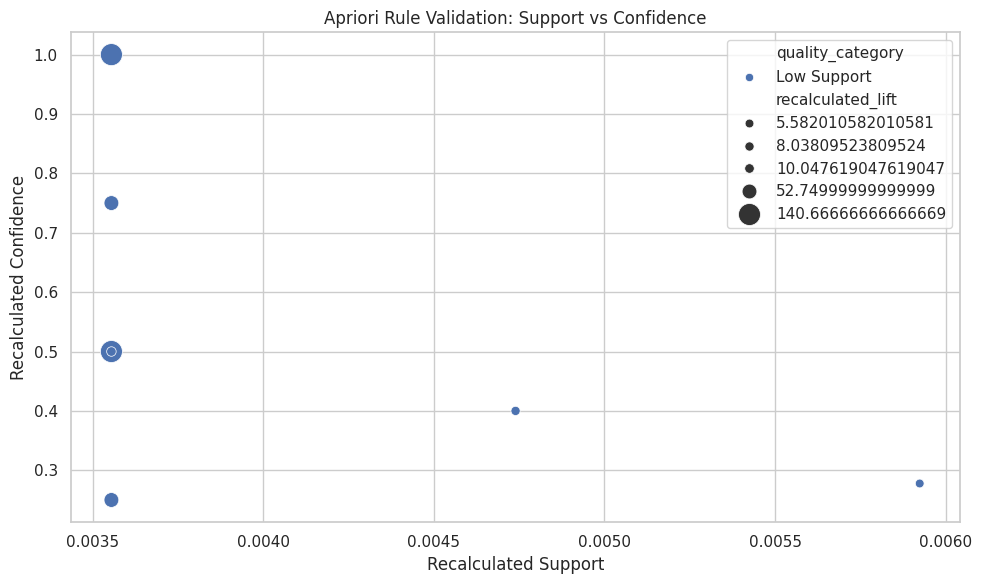

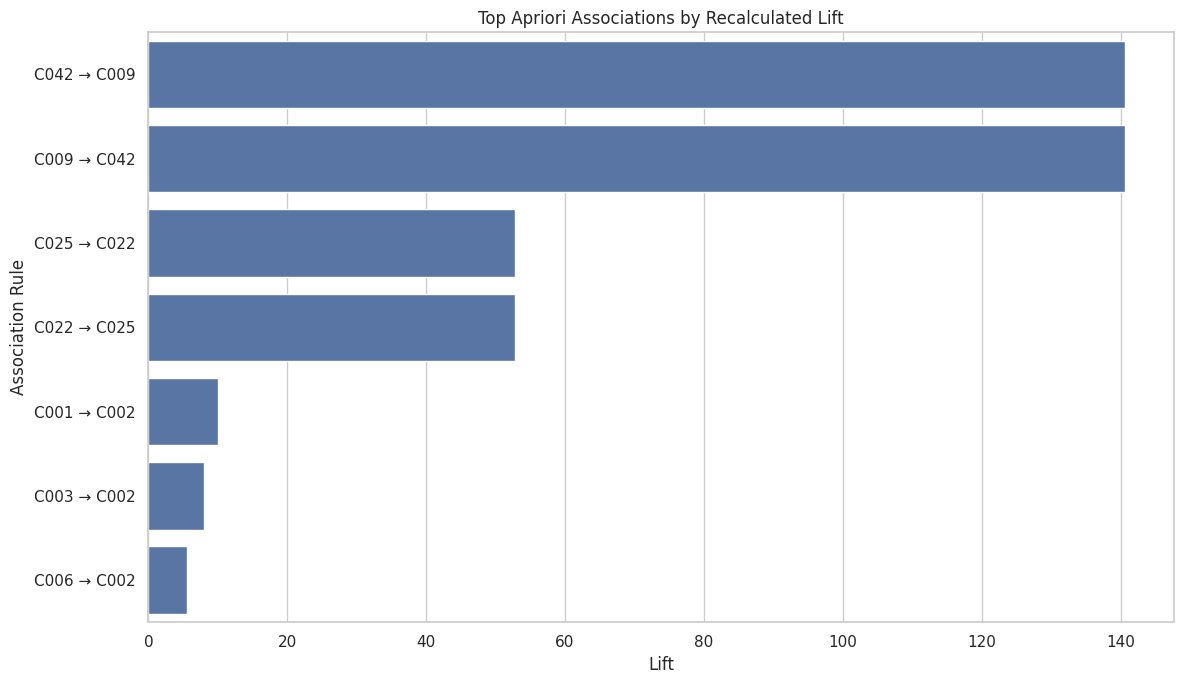

In [101]:
# ============================================================
# SECTION 8: APRIORI VALIDATION VISUALIZATIONS
# ============================================================

if not quality.empty:

    # Support versus Confidence
    plt.figure(figsize=(10, 6))

    sns.scatterplot(

        data=quality,

        x="recalculated_support",

        y="recalculated_confidence",

        size="recalculated_lift",

        hue="quality_category",

        sizes=(40, 250)

    )

    plt.title(
        "Apriori Rule Validation: Support vs Confidence"
    )

    plt.xlabel("Recalculated Support")

    plt.ylabel("Recalculated Confidence")

    plt.tight_layout()

    plt.show()


    # Top rules by lift
    top_rules = quality.sort_values(
        "recalculated_lift",
        ascending=False
    ).head(10).copy()


    top_rules["rule_label"] = top_rules.apply(

        lambda row: (
            f"{','.join(row['antecedents'])} → "
            f"{','.join(row['consequents'])}"
        ),

        axis=1
    )


    plt.figure(figsize=(12, 7))

    sns.barplot(

        data=top_rules,

        x="recalculated_lift",

        y="rule_label"

    )

    plt.title(
        "Top Apriori Associations by Recalculated Lift"
    )

    plt.xlabel("Lift")

    plt.ylabel("Association Rule")

    plt.tight_layout()

    plt.show()

In [102]:
# ============================================================
# SECTION 9: MARKOV TRANSITION MATRIX VALIDATION
# ============================================================

STATES = [
    "On Track",
    "At Risk",
    "Delayed"
]

transitions = markov_transitions.copy()

transitions["from_period"] = pd.to_numeric(
    transitions["from_period"],
    errors="raise"
).astype(int)

transitions["to_period"] = pd.to_numeric(
    transitions["to_period"],
    errors="raise"
).astype(int)


# Historical training transitions only
historical_transitions = transitions[
    transitions["from_period"].between(1, 3)
    & transitions["to_period"].between(2, 4)
].copy()


# Check consecutive periods
historical_transitions["consecutive"] = (
    historical_transitions["to_period"]
    - historical_transitions["from_period"]
) == 1


assert historical_transitions["consecutive"].all()


# Reconstruct count matrix
reconstructed_counts = pd.crosstab(

    historical_transitions["from_state"],

    historical_transitions["to_state"]

).reindex(

    index=STATES,

    columns=STATES,

    fill_value=0
)


# Reconstruct probability matrix
reconstructed_matrix = reconstructed_counts.div(

    reconstructed_counts.sum(axis=1).replace(0, np.nan),

    axis=0
)


print("RECONSTRUCTED TRANSITION COUNTS")

display(reconstructed_counts)


print("\nRECONSTRUCTED TRANSITION PROBABILITIES")

display(reconstructed_matrix.round(4))


# Compare with exported values
exported_counts = markov_counts_export.copy()

exported_counts.index = exported_counts.index.astype(str)
exported_counts.columns = exported_counts.columns.astype(str)

exported_counts = exported_counts.reindex(
    index=STATES,
    columns=STATES,
    fill_value=0
)

exported_matrix = markov_matrix_export.copy()

exported_matrix.index = exported_matrix.index.astype(str)
exported_matrix.columns = exported_matrix.columns.astype(str)

exported_matrix = exported_matrix.reindex(
    index=STATES,
    columns=STATES
)


count_match = np.array_equal(
    reconstructed_counts.values.astype(int),
    exported_counts.values.astype(int)
)


matrix_match = np.allclose(
    reconstructed_matrix.fillna(-1).values,
    exported_matrix.fillna(-1).values,
    atol=1e-6
)


print("\nCOMPARISON RESULTS")

print("Transition counts match:", count_match)

print("Transition probabilities match:", matrix_match)


# Verify probability rows
row_sums = reconstructed_matrix.sum(axis=1)

probability_validation = pd.DataFrame({

    "state": STATES,

    "outgoing_transitions": (
        reconstructed_counts.sum(axis=1).values
    ),

    "probability_row_sum": row_sums.values,

    "valid": [
        (
            np.isclose(row_sums[state], 1)
            if reconstructed_counts.loc[state].sum() > 0
            else False
        )
        for state in STATES
    ]
})


display(probability_validation)

print("\nProbability row sum validation:")
display(probability_validation)

RECONSTRUCTED TRANSITION COUNTS


to_state,On Track,At Risk,Delayed
from_state,,,
On Track,216,56,2
At Risk,91,71,16
Delayed,7,1,8



RECONSTRUCTED TRANSITION PROBABILITIES


to_state,On Track,At Risk,Delayed
from_state,,,
On Track,0.7883,0.2044,0.0073
At Risk,0.5112,0.3989,0.0899
Delayed,0.4375,0.0625,0.5000



COMPARISON RESULTS
Transition counts match: True
Transition probabilities match: True


,state,outgoing_transitions,probability_row_sum,valid
0,On Track,274,1.0,True
1,At Risk,178,1.0,True
2,Delayed,16,1.0,True



Probability row sum validation:


,state,outgoing_transitions,probability_row_sum,valid
0,On Track,274,1.0,True
1,At Risk,178,1.0,True
2,Delayed,16,1.0,True


In [103]:
# ============================================================
# SECTION 10: TEMPORAL HOLDOUT EVALUATION
# ============================================================

# TRAINING DATA: Period 1->2 and Period 2->3
train_data = transitions[
    (
        transitions["from_period"] == 1
    ) & (
        transitions["to_period"] == 2
    )
    |
    (
        transitions["from_period"] == 2
    ) & (
        transitions["to_period"] == 3
    )
].copy()


# TEST DATA: Period 3->4
test_data = transitions[
    (
        transitions["from_period"] == 3
    ) & (
        transitions["to_period"] == 4
    )
].copy()


# Training transition count matrix
train_counts = pd.crosstab(

    train_data["from_state"],

    train_data["to_state"]

).reindex(

    index=STATES,

    columns=STATES,

    fill_value=0
)


# Training transition probability matrix
train_matrix = train_counts.div(

    train_counts.sum(axis=1).replace(0, np.nan),

    axis=0
)


print("TEMPORAL HOLDOUT SUMMARY")

print("Training transitions:", len(train_data))

print("Testing transitions:", len(test_data))

print("\nTraining transition counts:")

display(train_counts)

print("\nTraining probability matrix:")

display(train_matrix.round(4))


# Predict using the highest probability destination
holdout_records = []

for _, row in test_data.iterrows():

    current_state = row["from_state"]

    actual_state = row["to_state"]

    if (
        current_state not in STATES
        or train_counts.loc[current_state].sum() == 0
    ):

        predicted_state = None
        prediction_status = "Unavailable: no training transitions"

    else:

        probabilities = train_matrix.loc[current_state]

        predicted_state = probabilities.idxmax()

        prediction_status = "Predicted"


    holdout_records.append({

        "student_id": row["student_id"],

        "from_period": row["from_period"],

        "to_period": row["to_period"],

        "current_state": current_state,

        "actual_next_state": actual_state,

        "predicted_next_state": predicted_state,

        "prediction_status": prediction_status,

        "correct": (
            predicted_state == actual_state
            if predicted_state is not None
            else None
        )
    })


holdout_results = pd.DataFrame(holdout_records)


print("\nHOLDOUT PREDICTION PREVIEW")

display(holdout_results.head(20))


print("\nPREDICTION COVERAGE")

display(
    holdout_results["prediction_status"]
    .value_counts()
    .to_frame("count")
)

TEMPORAL HOLDOUT SUMMARY
Training transitions: 310
Testing transitions: 158

Training transition counts:


to_state,On Track,At Risk,Delayed
from_state,,,
On Track,139,44,2
At Risk,62,49,14
Delayed,0,0,0



Training probability matrix:


to_state,On Track,At Risk,Delayed
from_state,,,
On Track,0.7514,0.2378,0.0108
At Risk,0.4960,0.3920,0.1120
Delayed,NaN,NaN,NaN



HOLDOUT PREDICTION PREVIEW


,student_id,from_period,to_period,current_state,actual_next_state,predicted_next_state,prediction_status,correct
0,STU0001,3,4,At Risk,On Track,On Track,Predicted,True
1,STU0002,3,4,On Track,On Track,On Track,Predicted,True
2,STU0003,3,4,At Risk,On Track,On Track,Predicted,True
3,STU0005,3,4,On Track,At Risk,On Track,Predicted,False
4,STU0007,3,4,On Track,On Track,On Track,Predicted,True
5,STU0008,3,4,On Track,On Track,On Track,Predicted,True
6,STU0009,3,4,On Track,On Track,On Track,Predicted,True
7,STU0010,3,4,On Track,At Risk,On Track,Predicted,False
8,STU0011,3,4,At Risk,At Risk,On Track,Predicted,False
9,STU0012,3,4,At Risk,On Track,On Track,Predicted,True



PREDICTION COVERAGE


,count
prediction_status,
Predicted,142
Unavailable: no training transitions,16


In [104]:
# ============================================================
# SECTION 11: MARKOV PREDICTION PERFORMANCE
# ============================================================

evaluated = holdout_results[
    holdout_results["predicted_next_state"].notna()
].copy()


total_test = len(holdout_results)

valid_predictions = len(evaluated)

coverage = (
    valid_predictions / total_test
    if total_test > 0 else np.nan
)


if valid_predictions > 0:

    y_true = evaluated["actual_next_state"]

    y_pred = evaluated["predicted_next_state"]


    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(

        y_true,

        y_pred,

        labels=STATES,

        average="macro",

        zero_division=0
    )


    cm = confusion_matrix(

        y_true,

        y_pred,

        labels=STATES
    )


    print("MARKOV HOLDOUT PERFORMANCE")

    print("Total holdout transitions:", total_test)

    print("Valid predictions:", valid_predictions)

    print(f"Prediction coverage: {coverage:.2%}")

    print(f"Accuracy: {accuracy:.4f}")

    print(f"Macro F1: {macro_f1:.4f}")


    confusion_df = pd.DataFrame(

        cm,

        index=[f"Actual {s}" for s in STATES],

        columns=[f"Predicted {s}" for s in STATES]

    )


    print("\nCONFUSION MATRIX")

    display(confusion_df)


    # Classification report
    report = classification_report(

        y_true,

        y_pred,

        labels=STATES,

        output_dict=True,

        zero_division=0
    )


    report_df = pd.DataFrame(report).transpose()

    print("\nCLASSIFICATION REPORT")

    display(report_df.round(4))


else:

    accuracy = np.nan
    macro_f1 = np.nan

    confusion_df = pd.DataFrame()

    report_df = pd.DataFrame()

    print(
        "Metrics cannot be calculated because no valid "
        "holdout predictions are available."
    )

MARKOV HOLDOUT PERFORMANCE
Total holdout transitions: 158
Valid predictions: 142
Prediction coverage: 89.87%
Accuracy: 0.7465
Macro F1: 0.2849

CONFUSION MATRIX


,Predicted On Track,Predicted At Risk,Predicted Delayed
Actual On Track,106,0,0
Actual At Risk,34,0,0
Actual Delayed,2,0,0



CLASSIFICATION REPORT


,precision,recall,f1-score,support
On Track,0.7465,1.0000,0.8548,106.0000
At Risk,0.0000,0.0000,0.0000,34.0000
Delayed,0.0000,0.0000,0.0000,2.0000
accuracy,0.7465,0.7465,0.7465,0.7465
macro avg,0.2488,0.3333,0.2849,142.0000
weighted avg,0.5572,0.7465,0.6381,142.0000


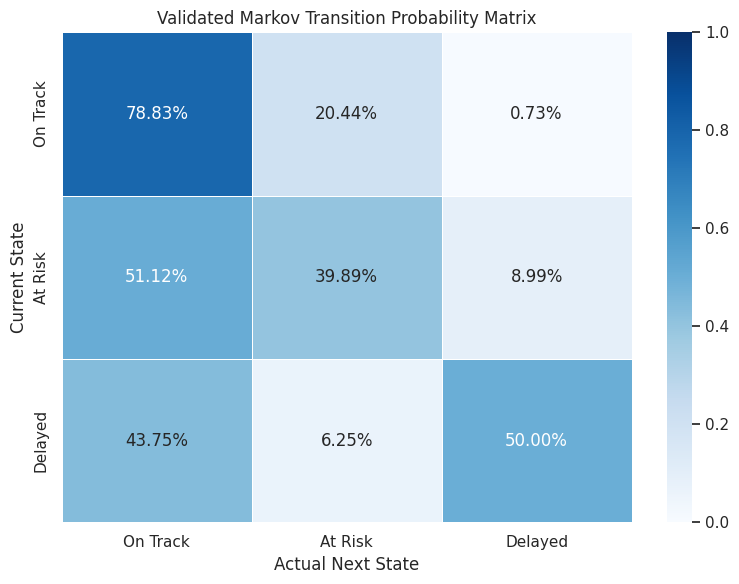

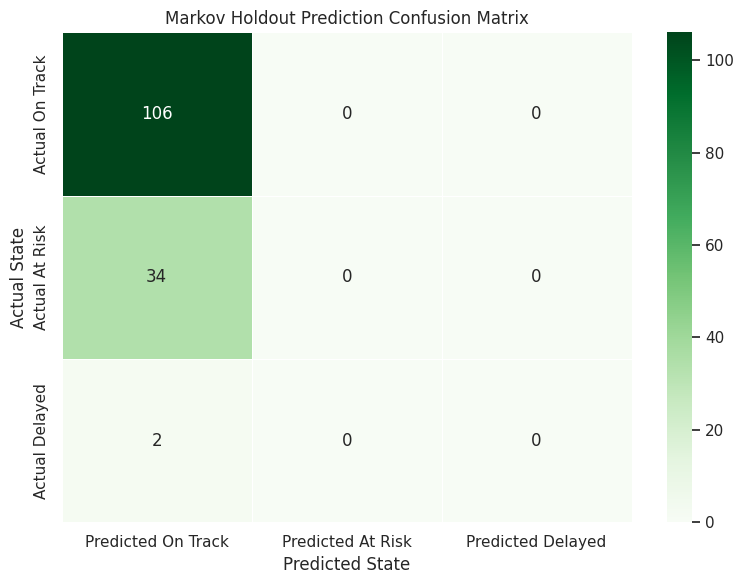

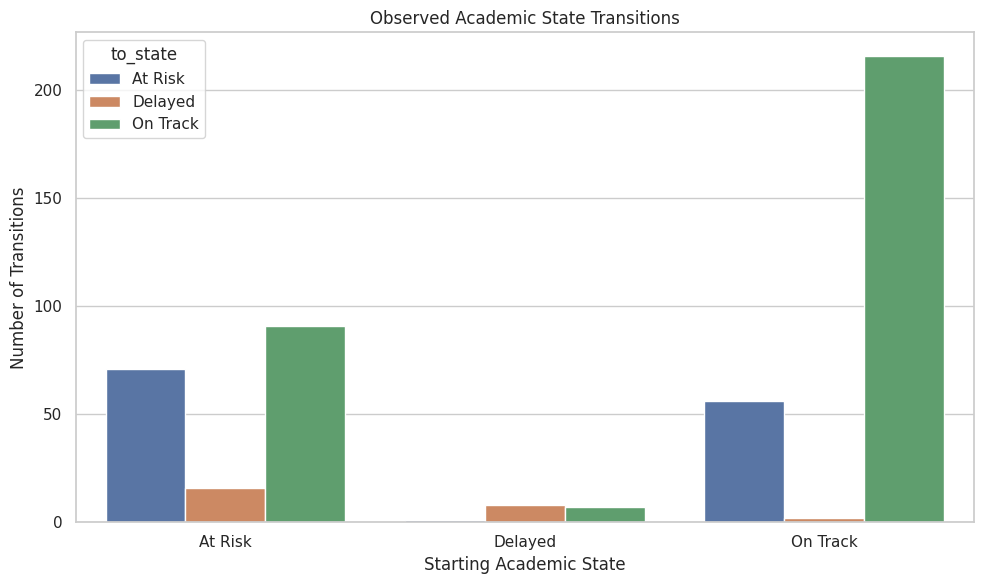

In [105]:
# ============================================================
# SECTION 12: MARKOV VALIDATION VISUALIZATIONS
# ============================================================

# 1. Reconstructed probability heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(

    reconstructed_matrix,

    annot=True,

    fmt=".2%",

    cmap="Blues",

    linewidths=0.5,

    vmin=0,

    vmax=1

)

plt.title(
    "Validated Markov Transition Probability Matrix"
)

plt.xlabel("Actual Next State")

plt.ylabel("Current State")

plt.tight_layout()

plt.show()


# 2. Confusion matrix
if not confusion_df.empty:

    plt.figure(figsize=(8, 6))

    sns.heatmap(

        confusion_df,

        annot=True,

        fmt="d",

        cmap="Greens",

        linewidths=0.5

    )

    plt.title(
        "Markov Holdout Prediction Confusion Matrix"
    )

    plt.xlabel("Predicted State")

    plt.ylabel("Actual State")

    plt.tight_layout()

    plt.show()


# 3. Observed transitions by state pair
observed_pairs = (
    historical_transitions
    .groupby(["from_state", "to_state"])
    .size()
    .reset_index(name="transition_count")
)

plt.figure(figsize=(10, 6))

sns.barplot(

    data=observed_pairs,

    x="from_state",

    y="transition_count",

    hue="to_state"

)

plt.title(
    "Observed Academic State Transitions"
)

plt.xlabel("Starting Academic State")

plt.ylabel("Number of Transitions")

plt.tight_layout()

plt.show()

In [106]:
# ============================================================
# SECTION 13: HOLDOUT PROBABILITY EVALUATION
# ============================================================

holdout_probability_records = []

for _, row in test_data.iterrows():

    current_state = row["from_state"]

    actual_state = row["to_state"]

    if (
        current_state not in STATES
        or train_counts.loc[current_state].sum() == 0
    ):
        continue

    actual_probability = train_matrix.loc[
        current_state,
        actual_state
    ]

    if pd.isna(actual_probability):
        continue

    holdout_probability_records.append({

        "student_id": row["student_id"],

        "current_state": current_state,

        "actual_next_state": actual_state,

        "probability_assigned": float(actual_probability),

        "negative_log_likelihood": float(
            -np.log(max(actual_probability, 1e-15))
        )
    })


holdout_probability_df = pd.DataFrame(
    holdout_probability_records
)


if not holdout_probability_df.empty:

    mean_log_loss = (
        holdout_probability_df[
            "negative_log_likelihood"
        ].mean()
    )

    print(
        "Evaluated probability predictions:",
        len(holdout_probability_df)
    )

    print(
        f"Mean negative log-likelihood: {mean_log_loss:.4f}"
    )

    print(
        "Lower values indicate better probability assignments."
    )

    display(holdout_probability_df.head(15))

else:

    mean_log_loss = np.nan

    print(
        "Log loss unavailable: no supported holdout probabilities."
    )

Evaluated probability predictions: 142
Mean negative log-likelihood: 0.5955
Lower values indicate better probability assignments.


,student_id,current_state,actual_next_state,probability_assigned,negative_log_likelihood
0,STU0001,At Risk,On Track,0.496000,0.701179
1,STU0002,On Track,On Track,0.751351,0.285882
2,STU0003,At Risk,On Track,0.496000,0.701179
3,STU0005,On Track,At Risk,0.237838,1.436166
4,STU0007,On Track,On Track,0.751351,0.285882
5,STU0008,On Track,On Track,0.751351,0.285882
6,STU0009,On Track,On Track,0.751351,0.285882
7,STU0010,On Track,At Risk,0.237838,1.436166
8,STU0011,At Risk,At Risk,0.392000,0.936493
9,STU0012,At Risk,On Track,0.496000,0.701179


In [107]:
# ============================================================
# SECTION 14: SIX-DATASET RELATIONAL VALIDATION
# ============================================================

# Load remaining original datasets
course_performance = pd.read_csv(
    find_csv("course_performance.csv")
)

student_progression = pd.read_csv(
    find_csv("student_progression.csv")
)

historical_records = pd.read_csv(
    find_csv("historical_course_records.csv")
)


# Normalize identifiers
course_ids = set(
    course_master["course_id"].astype(str)
)

student_ids = set(
    student_progression["student_id"].astype(str)
)


def check_foreign_key(series, reference_set):

    values = set(series.dropna().astype(str))

    return {

        "total_references": len(series),

        "valid_references": len(
            values.intersection(reference_set)
        ),

        "invalid_references": len(
            values - reference_set
        ),

        "all_valid": values.issubset(reference_set)
    }


checks = {

    "Course Performance → Course Master": check_foreign_key(
        course_performance["course_id"],
        course_ids
    ),

    "Prerequisite Mapping → Course Master (prerequisite)": check_foreign_key(
        prerequisites["prerequisite_course_id"],
        course_ids
    ),

    "Prerequisite Mapping → Course Master (succeeding)": check_foreign_key(
        prerequisites["succeeding_course_id"],
        course_ids
    ),

    "Student Progression → Course Master (failed courses)": check_foreign_key(
        student_progression["failed_course_ids"].dropna().astype(str)
        .str.findall(r"C\d+").explode(),
        course_ids
    ),

    "Historical Records → Course Master": check_foreign_key(
        historical_records["course_id"],
        course_ids
    ),

    "Student Course History → Course Master": check_foreign_key(
        student_history["course_id"],
        course_ids
    ),

    "Student Course History → Student Progression": check_foreign_key(
        student_history["student_id"],
        student_ids
    )
}


relational_validation = pd.DataFrame([

    {
        "relationship": name,
        **result
    }

    for name, result in checks.items()

])


print("SIX-DATASET RELATIONAL VALIDATION")

display(relational_validation)


print("\nDATASET RECORD COUNTS")

dataset_counts = pd.DataFrame({

    "dataset": [
        "Course Master",
        "Course Performance",
        "Prerequisite Mapping",
        "Student Progression",
        "Historical Course Records",
        "Student Course History"
    ],

    "records": [
        len(course_master),
        len(course_performance),
        len(prerequisites),
        len(student_progression),
        len(historical_records),
        len(student_history)
    ]
})

display(dataset_counts)

SIX-DATASET RELATIONAL VALIDATION


,relationship,total_references,valid_references,invalid_references,all_valid
0,Course Performance → Course Master,50,50,0,True
1,Prerequisite Mapping → Course Master (prerequisite),60,35,0,True
2,Prerequisite Mapping → Course Master (succeeding),60,38,0,True
3,Student Progression → Course Master (failed courses),174,39,0,True
4,Historical Records → Course Master,200,50,0,True
5,Student Course History → Course Master,1928,50,0,True
6,Student Course History → Student Progression,1928,200,0,True



DATASET RECORD COUNTS


,dataset,records
0,Course Master,50
1,Course Performance,50
2,Prerequisite Mapping,60
3,Student Progression,200
4,Historical Course Records,200
5,Student Course History,1928


In [108]:
# ============================================================
# SECTION 15: OVERALL MODEL EVALUATION
# ============================================================

apriori_valid_items = (
    int(itemset_validation_df["valid"].sum())
    if not itemset_validation_df.empty else 0
)

apriori_invalid_items = (
    int((~itemset_validation_df["valid"]).sum())
    if not itemset_validation_df.empty else 0
)

apriori_valid_rules = (
    int(rule_validation_df["all_metrics_valid"].sum())
    if not rule_validation_df.empty else 0
)

apriori_invalid_rules = (
    int((~rule_validation_df["all_metrics_valid"]).sum())
    if not rule_validation_df.empty else 0
)


findings = [

    {
        "model": "Apriori",

        "validation_area": "Frequent Itemset Support",

        "result": (
            f"{apriori_valid_items} valid / "
            f"{len(itemset_validation_df)} total"
        ),

        "status": (
            "Passed"
            if apriori_invalid_items == 0
            else "Needs Review"
        )
    },

    {
        "model": "Apriori",

        "validation_area": "Association Rule Metrics",

        "result": (
            f"{apriori_valid_rules} valid / "
            f"{len(rule_validation_df)} total"
        ),

        "status": (
            "Passed"
            if apriori_invalid_rules == 0
            else "Needs Review"
        )
    },

    {
        "model": "Markov Chain",

        "validation_area": "Transition Count Consistency",

        "result": str(count_match),

        "status": "Passed" if count_match else "Needs Review"
    },

    {
        "model": "Markov Chain",

        "validation_area": "Transition Probability Consistency",

        "result": str(matrix_match),

        "status": "Passed" if matrix_match else "Needs Review"
    },

    {
        "model": "Markov Chain",

        "validation_area": "Temporal Holdout",

        "result": (
            f"{valid_predictions}/{total_test} predictions"
            if total_test > 0 else "No test records"
        ),

        "status": (
            "Evaluated"
            if valid_predictions > 0
            else "Insufficient Data"
        )
    },

    {
        "model": "Markov Chain",

        "validation_area": "Prediction Accuracy",

        "result": (
            f"{accuracy:.4f}"
            if not np.isnan(accuracy)
            else "Not available"
        ),

        "status": (
            "Evaluated"
            if not np.isnan(accuracy)
            else "Insufficient Data"
        )
    },

    {
        "model": "Markov Chain",

        "validation_area": "Macro F1",

        "result": (
            f"{macro_f1:.4f}"
            if not np.isnan(macro_f1)
            else "Not available"
        ),

        "status": (
            "Evaluated"
            if not np.isnan(macro_f1)
            else "Insufficient Data"
        )
    },

    {
        "model": "Overall",

        "validation_area": "Six-Dataset Relationships",

        "result": (
            f"{int(relational_validation['all_valid'].sum())}/"
            f"{len(relational_validation)} valid checks"
        ),

        "status": (
            "Passed"
            if relational_validation["all_valid"].all()
            else "Needs Review"
        )
    }
]


evaluation_summary = pd.DataFrame(findings)

print("OVERALL VALIDATION SUMMARY")

display(evaluation_summary)

OVERALL VALIDATION SUMMARY


,model,validation_area,result,status
0,Apriori,Frequent Itemset Support,28 valid / 28 total,Passed
1,Apriori,Association Rule Metrics,7 valid / 7 total,Passed
2,Markov Chain,Transition Count Consistency,True,Passed
3,Markov Chain,Transition Probability Consistency,True,Passed
4,Markov Chain,Temporal Holdout,142/158 predictions,Evaluated
5,Markov Chain,Prediction Accuracy,0.7465,Evaluated
6,Markov Chain,Macro F1,0.2849,Evaluated
7,Overall,Six-Dataset Relationships,7/7 valid checks,Passed


In [109]:
# ============================================================
# SECTION 16: EXPORT TASK 5 RESULTS
# ============================================================

OUTPUT_DIR = "/content/task5_validation_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# Export validation tables
exports = {

    "apriori_itemset_validation.csv":
        itemset_validation_df,

    "apriori_rule_validation.csv":
        rule_validation_df,

    "apriori_rule_quality.csv":
        quality,

    "markov_transition_count_validation.csv":
        reconstructed_counts,

    "markov_transition_probability_validation.csv":
        reconstructed_matrix,

    "markov_holdout_predictions.csv":
        holdout_results,

    "markov_probability_evaluation.csv":
        holdout_probability_df,

    "markov_confusion_matrix.csv":
        confusion_df,

    "relational_validation.csv":
        relational_validation,

    "model_evaluation_summary.csv":
        evaluation_summary
}


for filename, dataframe in exports.items():

    dataframe.to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=True
    )


# Create JSON summary
validation_summary = {

    "project": (
        "Course Bottleneck Detection and "
        "Academic Progression Analysis"
    ),

    "task": "Task 5 - Model Validation and Evaluation",

    "data_sources": [
        "course_master.csv",
        "course_performance.csv",
        "prerequisite_mapping.csv",
        "student_progression.csv",
        "historical_course_records.csv",
        "student_course_history.csv"
    ],

    "apriori_validation": {

        "total_frequent_itemsets": len(itemset_validation_df),

        "valid_frequent_itemsets": apriori_valid_items,

        "invalid_frequent_itemsets": apriori_invalid_items,

        "total_association_rules": len(rule_validation_df),

        "valid_association_rules": apriori_valid_rules,

        "invalid_association_rules": apriori_invalid_rules,

        "weak_rules": (
            int(
                (
                    quality["quality_category"]
                    == "Weak / No Positive Association"
                ).sum()
            )
            if not quality.empty else 0
        ),

        "potentially_redundant_rules": (
            int(quality["potentially_redundant"].sum())
            if not quality.empty else 0
        )
    },

    "markov_validation": {

        "training_transitions": len(train_data),

        "testing_transitions": len(test_data),

        "valid_predictions": valid_predictions,

        "prediction_coverage": (
            float(coverage)
            if not np.isnan(coverage) else None
        ),

        "accuracy": (
            float(accuracy)
            if not np.isnan(accuracy) else None
        ),

        "macro_f1": (
            float(macro_f1)
            if not np.isnan(macro_f1) else None
        ),

        "mean_negative_log_likelihood": (
            float(mean_log_loss)
            if not np.isnan(mean_log_loss) else None
        ),

        "transition_counts_match": bool(count_match),

        "transition_probabilities_match": bool(matrix_match)
    },

    "relational_validation": {

        "total_checks": len(relational_validation),

        "passed_checks": int(
            relational_validation["all_valid"].sum()
        ),

        "failed_checks": int(
            (~relational_validation["all_valid"]).sum()
        )
    },

    "limitations": [

        "Apriori identifies associations, not causation.",

        "Low-support association rules may be unstable.",

        "Markov estimates depend on the quality and size of historical transition records.",

        "The Delayed state has relatively few observations.",

        "The Markov model assumes first-order state dependence.",

        "Only one chronological holdout interval is available for evaluation.",

        "The datasets are synthetic and do not establish real university outcomes."
    ]
}


with open(
    os.path.join(OUTPUT_DIR, "task5_validation_summary.json"),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        validation_summary,
        f,
        indent=4,
        ensure_ascii=False
    )


print("=" * 65)
print("TASK 5 VALIDATION EXPORT COMPLETED")
print("=" * 65)

for filename in sorted(os.listdir(OUTPUT_DIR)):

    print("✓", filename)


# Download all results as ZIP
import shutil

zip_path = shutil.make_archive(
    "/content/task5_validation_outputs",
    "zip",
    OUTPUT_DIR
)

files.download(zip_path)

TASK 5 VALIDATION EXPORT COMPLETED
✓ apriori_itemset_validation.csv
✓ apriori_rule_quality.csv
✓ apriori_rule_validation.csv
✓ markov_confusion_matrix.csv
✓ markov_holdout_predictions.csv
✓ markov_probability_evaluation.csv
✓ markov_transition_count_validation.csv
✓ markov_transition_probability_validation.csv
✓ model_evaluation_summary.csv
✓ relational_validation.csv
✓ task5_validation_summary.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>